# 虚実行があるからこそ解ける問題 ―― 部品の意味と計算量

(Version 0.9.1)

**0.9.1 での変更**: 読み直して、§4.4 の表と記述を §4.6 の結果(定理 K、$|S|=4$ の境界の検証、CS 6 個の反例)に合わせた。定理 H′ の証明の式の誤植を直した。今後の課題に callCC の意味論の形式化を足した。

**0.9.0 での変更**: §8.5 を足した。状態の値を保存して配れるスケジューラで作れる rf は、rf ∪ po が循環しないもの(階層の I 以下)にちょうど一致する(定理 E′、Lean)。これにより、§8.3・§8.4 の「線形な継続 = 実実行」を、状態が継続の中にしかない場合の話として限定し、複数のプロセスでは「継続のコピー」と「状態のコピー」が別の軸であることを書いた。

**0.8.0 での変更**: 定理 J(区別の正確な条件)の両向きと、定理 H (3)(どの lock の割り込みも省けない)を Lean で証明した。CS がちょうど状態の数の場合(予想 2″ の残り)を調べ、証明の途中までを §4.6 に書いた。

**0.7.0 での変更**: 予想 2″ に取り組んだ。記憶のある相手が $P'$ に値を出させないようにできるのは「一手で潰せる」ときに限ること(補題 S)と、区別の正確な条件(定理 J)を示し、それを使って **CS が状態の数 − 1 個以下なら予想 2″ は正しい** ことを証明した(定理 K、Lean)。残る CS = 状態の数の場合を $|S|=4$ で計算機により調べ、$|S| \le 4$ では予想 2″ が正しいことを確かめた(§4.5・§4.6)。

**0.6.0 での変更**: 記憶のある相手で区別できるかの厳密な判定法(長さの補題と知識の状態のゲーム)を作り、予想 2′ が $|S|=3$・CS 4 個でも破れることを示した。予想 2″(CS の数 ≦ 状態の数なら成り立つ)に改めた。

**0.5.0 での変更**: 予想 2′ を、$|S|=3$・CS 3 個以下と $|S|=4$・CS 2 個以下で計算機により完全に検証し、何かをする CS が一つの場合を Lean で証明した。

**0.4.0 での変更**: 予想 2 を調べ、元の形では誤りであることを示した。記憶のある相手にも、何もしない CS の位置は見えない(定理 I、Lean)。予想 2′ に改め、$|S|=3$ で確かめた。

**0.3.0 での変更**: 予想 1(スケジュールを選べない観測でも、プロセスと同じ長さの相手で足りる)を証明した(定理 H′、Lean)。

**0.2.0 での変更**: 中心問題(必要な虚の量)を、検査者がスケジュールを選べる設定で解いた(定理 H、Lean)。§4 を書き直し、スケジュールを選べない観測についての予想 1 を CS 3 個まで確かめた。

文責: JRF ( http://jrf.cocolog-nifty.com/ ) ／ 執筆・計算の大部分: Claude Opus 5.5 (Anthropic) ／ 2026年11月

**要旨.** 第一報「虚実行論」(report0)は、並列処理の実行を「各クリティカルセクション(CS)がどの状態を読んだか」の木として見て、**実実行 = 状態を移動させた実行、虚実行 = 状態をコピーしてしまった実行** と整理した。虚数は「現実にはない量」だが、それを経由すると計算が楽になり、見通しがよくなり、方程式の一部分だけを取り出して扱えるようになった。この稿は、虚実行にも同じ種類の効用があるかを調べる。

主な結果は次のとおり。

1. **部品に意味を与える問題.** 並列プログラムをプロセスごとに理解したいとき、各プロセスを単独で(誰にも邪魔されずに)走らせたときの振る舞い ―― 実実行だけ ―― を意味としたのでは、並列に組み合わせた結果を計算できない(**定理 C**、Lean で証明)。プロセスの意味には、実際の相手が渡さないかもしれない「虚の入力」を受け取ったときの振る舞いを含めなければならない。これは Brookes(1996)の完全抽象意味論や、rely-guarantee 推論(Jones 1983)と同じ構造で、ELDE その1 の「受け渡しがなければ自分の直前の状態で続ける」という規則は、Brookes の軌跡の「隙間」と同じ形をしている(§1〜§3)。
2. **どれだけの虚が要るか.** 検査者がスケジュールを選べる設定(ELDE が lock 仕様で実行を選んでいた設定)では、完全抽象な意味は「各 lock の前に任意の関数を一つずつ割り込ませた実行」であり、**各 lock に一つずつの虚の入力が必要かつ十分** である(**定理 H**。完全抽象・十分性・必要性を Lean で証明)。これは ELDE その1 の lock 仕様の形そのもので、report0 の「E0 が最小限の虚か」という問いに、この意味で肯定的に答える。ただし観測する側が記憶を持つと、すべての虚の入力が必要になる(スケジュールを選べない観測では、少なくとも何もしない CS の位置は見えない。**定理 I**、Lean)。スケジュールを選べない観測で記憶のある相手が見分けるのは、虚の入力の列のうち「外れたときに一手で潰せる」ものだけである(**定理 J**、Lean)。これを使うと、CS が状態の数 − 1 個以下なら、恒等写像の CS を消して一致することが文脈同値に等しい(**定理 K**、Lean)。CS が多いと、それより粗くなる例がある(§4)。
3. **計算量が下がる問題.** 不変条件を調べるとき、各スレッドが「ほかのスレッドが作りうるどの共有状態でも読む」と考えれば(虚の入力の総体)、スレッドごとの計算の和程度の手間で済む(スレッド・モジュラー検査、Flanagan & Qadeer 2003)。実実行の総当りが指数関数的に増えるのに、こちらは多項式で済むことを実測する。ただし判定できるのは局所的な不変条件までで、個数・保存則は判定できない(§5・§6)。
4. **非因果的な部品.** report0 §5.5 で触れた弱いメモリモデルの load buffering と out-of-thin-air 問題を、「部品の意味に未来の値を含める(promise)」話として整理する(§7)。
5. **継続.** ELDE が虚実行を作るために「プロセスを最初から再実行」していたのは、一度しか再開できない継続から何度でも再開できる継続(call/cc)を作る、知られた方法(Koppel ら 2018)と同じである。継続を余分に再開した回数だけ世界が増える(**定理 E**、Lean)。継続を一度しか使わない(線形な)制御はすべて実実行で、虚実行を必要とするのはバックトラック(やり直し)だけである(Berdine ら 2002。ただし状態が継続の中にしかない場合。複数のプロセスでは、状態の値のコピーだけで I 以下の虚実行がすべて作れる。**定理 E′**、Lean)。JRF の 2011 年の「時間泥棒」の物語を再実行で再現する(§8)。

計算はすべてこのノートの中で再現できる(実行には数分かかる)。定理 C・E・E′・H・H′・I・J・K と補題 S は Lean 4(Mathlib)で証明し、Lean のコードは各定理の直後に置いてノートの最後でまとめて検査する。定理の番号は、report0 の 1〜4、report1 の A・B に続けて C・E・E′・H・H′・I・J・K とする(補題 S・定理 J・定理 K も Lean)。

## 目次

- §0 問い ―― 虚数の効用と虚実行の効用
- §1 部品と並列合成のモデル
- §2 定理 C: 実実行だけでは並列合成について閉じない
- §3 虚の入力を含む意味 ―― Brookes の軌跡と ELDE その1
- §4 どれだけの虚が要るか ―― 定理 H・H′・I・J・K と予想
- §5 rely-guarantee ―― 虚の入力を仮定として切り出す
- §6 スレッド・モジュラー検査 ―― 虚の入力で計算量を下げる
- §7 非因果的な部品 ―― load buffering・out-of-thin-air・promise
- §8 継続と虚実行 ―― 再実行・世界の数・線形な継続
- §9 まとめ・予想・今後の課題
- 参考文献
- 付録 Lean による一括検証

## §0 問い ―― 虚数の効用と虚実行の効用

虚数が「なければ原理的に解けない」問題は、実はほとんどない。3 次方程式の実数解は、手間をかければ実数の範囲で求められる。虚数の価値は、(1) 計算が楽になる、(2) 見通しがよくなる、(3) 全体の一部分だけを取り出して意味を与えられる、の三つにあった。量子力学で虚数が「本当に」必要だと実験で示されたのは 2021 年になってからである(Renou ら 2021)。

虚実行についても同じことが言える。実実行は有限個しかないので、総当りすれば何でも答えは出る。だから問うべきは「虚実行がないと原理的に解けない問題」ではなく、虚実行を経由すると **楽に、見通しよく、部分に分けて** 解ける問題である。この稿は、その中でいちばん「必要性」に近いもの ―― 部品(プロセス)に意味を与える問題 ―― と、いちばん実用的なもの ―― 計算量が下がる問題 ―― を扱う。

report0 の言葉を確認しておく。

- 実行は、各 CS が読んだ状態を書いた CS を親とする木(読み出し関係 rf)。**実実行 ⇔ どの状態も高々一度しか読まれない ⇔ 一本道**(定理 1)。
- ELDE その1 の規則: lock で他のプロセスから状態を受け渡されなければ、自分の直前の unlock の状態で続ける。
- 虚実行の階層は「コピー」と「因果(時間の向き)」の二つの軸を緩めていた。因果を破る(未来を読む)と、実行は自己無撞着なものとしてしか存在しない(定理 4)。
- report1 では、コピーした世界を合流させ、合流が実実行と見分けられない条件(定理 A)を調べた。

## §1 部品と並列合成のモデル

できるだけ単純なモデルで考える。

- 共有状態は $S=\{0,1,\dots,n-1\}$ の一つの値。初期状態は 0。
- プロセスは CS の列。**記憶のないプロセス** では、各 CS は状態から状態への関数 $f: S\to S$ で、CS の列 $(f_1, \dots, f_L)$ がプロセスである。**記憶のあるプロセス** では、$m$ 番目の CS の出力が、そのプロセスがそれまでに読んだ値すべてに依存する(局所変数がある)。report0 の ELDE のプロセスは記憶のあるプロセスである。
- 並列合成 $P \parallel Q$ の **観測** は、CS 単位のすべてのインタリーブを初期状態から実行したときの最終状態の集合とする。
- 二つのプロセスが **文脈同値** であるとは、どんな相手 $Q$ と組んでも観測が同じになることをいう。部品の「意味」に求めたい理想は、文脈同値をちょうど捉えるもの(**完全抽象**)である。少なくとも、意味が同じなら文脈同値であってほしい(**合成的**)。

以下のセルは `kj_comp.py` を書き出す。

In [1]:
import matplotlib
import matplotlib.pyplot as plt
try:
    import japanize_matplotlib  # noqa: F401
except Exception:
    from matplotlib import font_manager
    for name in ["Noto Sans CJK JP", "IPAexGothic", "IPAGothic", "TakaoGothic", "Yu Gothic", "Meiryo"]:
        if any(name == f.name for f in font_manager.fontManager.ttflist):
            matplotlib.rcParams["font.family"] = name
            break
matplotlib.rcParams["axes.unicode_minus"] = False
import numpy as np
import itertools, time
from collections import Counter, defaultdict
print("ok")

ok


#### `kj_comp.py`

インタリーブの観測 `finals`、文脈同値 `context_classes`・`refines`、記憶のある相手で区別できるかの厳密な判定 `distinguishable`、定理 K の相手 `separating_partner`(`killer`・`is_full`・`run_with_partner`)、全状態探索 `explore_global` とスレッド・モジュラー検査 `explore_modular`、再実行による callCC `run_with_callcc`。

In [2]:
%%writefile kj_comp.py
# -*- coding: utf-8 -*-
"""kj_comp.py -- 「部品の意味と計算量」(report2)の計算コア。

* CS 単位のプロセス(各 CS は状態から状態への関数。記憶のあるプロセスは、それまでに読んだ値すべてに依存する表)
* 並列合成の結果(すべてのインタリーブの最終状態の集合)と、文脈同値
* スレッド・モジュラー検査(Flanagan & Qadeer 2003 の考え方)と、全状態探索の比較
* 一度しか再開できない継続(Python のジェネレータ)と再実行による、何度でも再開できる継続
"""
from __future__ import annotations
import itertools
import random
import time
from collections import defaultdict, deque


Overwriting kj_comp.py


In [3]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
# CS 単位のプロセスと並列合成
#   記憶のないプロセス: CS の関数の列。関数 S→S は値の組 (f(0), f(1), ...) で表す。
#   記憶のあるプロセス: m 番目の CS の出力が、そのプロセスが 0..m 番目に読んだ値すべてに依存する表。


Appending to kj_comp.py


In [4]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
def functions(nS):
    return list(itertools.product(range(nS), repeat=nS))


def finals(P, Q, init=0, memP=False, memQ=False, nS=None):
    """P と Q のすべてのインタリーブ(CS 単位)を実行し、最終状態の集合を返す。"""
    res = set()

    def step(proc, mem, k, s, hist):
        if not mem:
            return proc[k][s]
        idx = 0
        for v in hist + (s,):
            idx = idx * nS + v
        return proc[k][idx]

    def rec(i, j, s, hp, hq):
        if i == len(P) and j == len(Q):
            res.add(s)
            return
        if i < len(P):
            rec(i + 1, j, step(P, memP, i, s, hp), hp + (s,), hq)
        if j < len(Q):
            rec(i, j + 1, step(Q, memQ, j, s, hq), hp, hq + (s,))
    rec(0, 0, init, (), ())
    return frozenset(res)


def compose(P, nS):
    """記憶のないプロセスを、途中で邪魔されずに走らせたときの全体の関数(実実行だけの意味)。"""
    out = []
    for s in range(nS):
        for f in P:
            s = f[s]
        out.append(s)
    return tuple(out)


def memory_contexts(nS, L):
    """長さ L の記憶のある文脈をすべて作る。"""
    tabs = [list(itertools.product(range(nS), repeat=nS ** (m + 1))) for m in range(L)]
    return list(itertools.product(*tabs))


def context_classes(procs, contexts, nS, memQ=False):
    """文脈ごとの観測(最終状態の集合)の組で、プロセスを類に分ける。"""
    sig = {P: tuple(finals(P, Q, memQ=memQ, nS=nS) for Q in contexts) for P in procs}
    return sig


def refines(procs, key, sig):
    """key が同じなら文脈同値か(合成的・健全)、文脈同値なら key が同じか(完全)。"""
    by_key, by_sig = defaultdict(set), defaultdict(set)
    for P in procs:
        by_key[key(P)].add(sig[P])
        by_sig[sig[P]].add(key(P))
    return all(len(v) == 1 for v in by_key.values()), all(len(v) == 1 for v in by_sig.values())


Appending to kj_comp.py


In [5]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
# スレッド・モジュラー検査
#   スレッド i の局所状態 l、共有状態 g。遷移 step_i(l, g) -> [(l', g')]。
#   全状態探索: 大域状態 (l_0, ..., l_{N-1}, g) をすべてたどる。
#   スレッド・モジュラー: 各スレッドについて (l, g) の集合 R_i を、自分の遷移と、
#   他のスレッドが起こしうる共有状態の変化 g -> g'(保証 G_j)で閉じるまで広げる。


Appending to kj_comp.py


In [6]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
def explore_global(N, init_local, init_shared, step):
    start = (tuple(init_local for _ in range(N)), init_shared)
    seen = {start}
    dq = deque([start])
    while dq:
        ls, g = dq.popleft()
        for i in range(N):
            for l2, g2 in step(i, ls[i], g):
                st = (ls[:i] + (l2,) + ls[i + 1:], g2)
                if st not in seen:
                    seen.add(st)
                    dq.append(st)
    return seen


def explore_modular(N, init_local, init_shared, step):
    R = [{(init_local, init_shared)} for _ in range(N)]
    G = [set() for _ in range(N)]          # スレッド j が起こしうる共有状態の変化
    changed = True
    work = 0
    while changed:
        changed = False
        for i in range(N):
            new = set()
            for (l, g) in R[i]:
                for l2, g2 in step(i, l, g):
                    work += 1
                    new.add((l2, g2))
                    if g2 != g and (g, g2) not in G[i]:
                        G[i].add((g, g2)); changed = True
            for j in range(N):             # 他のスレッドによる共有状態の変化(虚の入力)
                if j == i:
                    continue
                for (l, g) in R[i]:
                    for (ga, gb) in G[j]:
                        if ga == g:
                            work += 1
                            new.add((l, gb))
            if not new <= R[i]:
                R[i] |= new; changed = True
    return R, G, work


Appending to kj_comp.py


In [7]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
# 継続: 一度しか再開できない継続(ジェネレータ)を、最初から再実行することで何度でも再開する
#   プログラムはジェネレータで、 x = yield ("callcc",) で「現在の継続」を受け取る。
#   受け取った値が ("right", k) のとき、後で yield ("throw", k, v) すると、
#   その callcc の時点に戻って ("left", v) を受け取ったかのように、最初から再実行する。


Appending to kj_comp.py


In [8]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
class Jump(Exception):
    pass


def run_with_callcc(program, max_worlds=50):
    """世界(再実行)の列と、各世界の結果を返す。"""
    answers = {}            # callcc の番号 -> 与える値
    worlds = []
    for _ in range(max_worlds):
        g = program()
        log = []
        n_callcc = 0
        try:
            req = next(g)
            while True:
                if req[0] == "callcc":
                    k = n_callcc
                    n_callcc += 1
                    val = answers.get(k, ("right", k))
                    log.append(f"callcc#{k} → {val[0]}")
                    req = g.send(val)
                elif req[0] == "throw":
                    _, k, v = req
                    log.append(f"継続#{k} を値 {v!r} で再開(この世界は捨てる)")
                    answers[k] = ("left", v)
                    answers = {kk: vv for kk, vv in answers.items() if kk <= k}
                    raise Jump()
                else:
                    raise ValueError(req)
        except StopIteration as e:
            worlds.append((log, e.value))
            return worlds
        except Jump:
            worlds.append((log, None))
    raise RuntimeError("too many worlds")


Appending to kj_comp.py


In [9]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
# 大きめの場合の文脈同値の類の数(numpy で全プロセスをまとめて計算する)
#   controlled=True : 検査者がスケジュールを選ぶ(ELDE の lock 仕様)。観測は各スケジュールの最終状態。
#   controlled=False: スケジュールは選べない。観測は全スケジュールの最終状態の集合。
#   相手 Q の関数を L+1 個の連続ブロックに分ける切り方が、スケジュールに対応する(定理 H の分解の補題)。


Appending to kj_comp.py


In [10]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
def count_classes_np(nS, L, ctx_lens, controlled, sample=None, seed=0):
    import numpy as np
    import random
    F = np.array(list(itertools.product(range(nS), repeat=nS)))
    ID = np.arange(nS)
    P = np.array(list(itertools.product(range(len(F)), repeat=L)))
    nP = len(P)
    fs = [F[P[:, k]] for k in range(L)]
    idx = np.arange(nP)
    rng = random.Random(seed)

    def comp(qs):
        r = ID.copy()
        for q in qs:
            r = q[r]
        return r
    sig = np.zeros(nP, dtype=np.uint64)
    out = []
    for m in ctx_lens:
        if sample is None or len(F) ** m <= sample:
            Qs = itertools.product(range(len(F)), repeat=m)
            nq = len(F) ** m
        else:
            Qs = [tuple(rng.randrange(len(F)) for _ in range(m)) for _ in range(sample)]
            nq = sample
        for Q in Qs:
            qf = [F[i] for i in Q]
            mask = np.zeros(nP, dtype=np.uint64)
            for cuts in itertools.combinations_with_replacement(range(m + 1), L):
                cut = (0,) + cuts + (m,)
                hs = [comp(qf[cut[j]:cut[j + 1]]) for j in range(L + 1)]
                x = np.full(nP, hs[0][0])
                for k in range(L):
                    x = hs[k + 1][fs[k][idx, x]]
                if controlled:
                    sig = sig * np.uint64(1000003) + x.astype(np.uint64) + np.uint64(1)
                else:
                    mask |= (np.uint64(1) << x.astype(np.uint64))
            if not controlled:
                sig = sig * np.uint64(1000003) + mask
        out.append((m, nq, len(np.unique(sig))))
    return out


def interference_classes_np(nS, L):
    """割り込みの意味(各 CS の前に任意の関数を一つずつ割り込ませた実行)で同値な類の数。"""
    import numpy as np
    F = np.array(list(itertools.product(range(nS), repeat=nS)))
    P = np.array(list(itertools.product(range(len(F)), repeat=L)))
    nP = len(P)
    fs = [F[P[:, k]] for k in range(L)]
    idx = np.arange(nP)
    sig = np.zeros(nP, dtype=np.uint64)
    for hs in itertools.product(range(len(F)), repeat=L - 1):
        for x0 in range(nS):
            x = fs[0][idx, np.full(nP, x0)]
            for k in range(1, L):
                x = fs[k][idx, F[hs[k - 1]][x]]
            sig = sig * np.uint64(1000003) + x.astype(np.uint64) + np.uint64(1)
    return len(np.unique(sig))


Appending to kj_comp.py


In [11]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
# 記憶のある相手に対する観測を、全プロセスについてまとめて計算する(予想 2′ の検証用)
#   相手から見ると、P の CS は連続したブロック A_0, …, A_T として相手の CS の間に入る。
#   x_1 = A_0(init), y_t = Q_t(x_1..x_t), x_{t+1} = A_t(y_t), 最終状態 = A_T(y_T)。


Appending to kj_comp.py


In [12]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
class MemObs:
    def __init__(self, nS, L, procs=None, init=0):
        import numpy as np
        self.np = np
        self.nS, self.L, self.init = nS, L, init
        self.F = np.array(list(itertools.product(range(nS), repeat=nS)))
        if procs is None:
            procs = list(itertools.product(range(len(self.F)), repeat=L))
        self.P = np.array(procs)
        nP = len(self.P)
        self.idx = np.arange(nP)
        ident = np.tile(np.arange(nS), (nP, 1))
        self.seg = {}
        for i in range(L + 1):
            cur = ident
            self.seg[(i, i)] = cur
            for j in range(i + 1, L + 1):
                cur = self.F[self.P[:, j - 1]][self.idx[:, None], cur]
                self.seg[(i, j)] = cur

    def mask(self, Q, sub=None):
        """相手 Q(表の列)に対する観測(最終状態の集合のビット列)を、プロセスごとに返す。"""
        np = self.np
        idx = self.idx if sub is None else sub
        T, L, nS = len(Q), self.L, self.nS
        m = np.zeros(len(idx), dtype=np.int64)
        for cuts in itertools.combinations_with_replacement(range(L + 1), T):
            x = self.seg[(0, cuts[0])][idx, self.init]
            h = x.copy()
            for t in range(T):
                y = np.asarray(Q[t])[h]
                nxt = cuts[t + 1] if t + 1 < T else L
                x = self.seg[(cuts[t], nxt)][idx, y]
                h = h * nS + x
            m |= (1 << x)
        return m


Appending to kj_comp.py


In [13]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
# 予想 2′ の有限の場合の完全な検証:
#   恒等写像を消した形ごとに代表を一つとり(定理 I)、記憶のある相手で観測を比べて、
#   すべての代表が区別されるまで分割を細かくする。


Appending to kj_comp.py


In [14]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
def verify_conj2(nS, L, seed=0, budget=200000, log=print):
    import numpy as np
    F = list(itertools.product(range(nS), repeat=nS))
    ident = F.index(tuple(range(nS)))
    nonid = [i for i in range(len(F)) if i != ident]
    reps = [tuple(seq) + (ident,) * (L - len(seq))
            for n in range(L + 1) for seq in itertools.product(nonid, repeat=n)]
    mo = MemObs(nS, L, reps)
    group = np.zeros(len(reps), dtype=np.int64)
    rng = random.Random(seed)
    t0 = time.time()
    used = []
    for trial in range(budget):
        sizes = np.bincount(group)
        active = np.nonzero(sizes[group] > 1)[0]
        if len(active) == 0:
            break
        T = rng.choice([1, 2, 3, 4, 5])
        Q = [tuple(rng.randrange(nS) for _ in range(nS ** (t + 1))) for t in range(T)]
        m = mo.mask(Q, active)
        key = group[active] * (1 << nS) + m
        _, newid = np.unique(key, return_inverse=True)
        before = len(np.unique(group))
        g2 = group.copy()
        g2[active] = newid + group.max() + 1
        _, group = np.unique(g2, return_inverse=True)
        if len(np.unique(group)) > before:
            used.append(Q)
        if trial % 2000 == 0:
            log(f"  試行 {trial}: 類 {len(np.unique(group))} / {len(reps)}  ({time.time() - t0:.0f} 秒)")
    n = len(np.unique(group))
    log(f"|S|={nS}, CS {L} 個以下: 代表 {len(reps)} 個、区別された類 {n}、"
        f"役に立った相手 {len(used)} 個、{time.time() - t0:.0f} 秒")
    return n == len(reps), used


Appending to kj_comp.py


In [15]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
# 記憶のある相手で二つのプロセスを区別できるかの厳密な判定(予想 2′ の反例の確認用)
#   相手の一回の手番 = 状態を読み、書く。相手から見た知識は (読んだ値, P がどこまで進んだかの可能性の集合,
#   P' の同じ集合) に尽きる。相手が勝つ = ある値 v を、P のあるスケジュールは出し、P' のどのスケジュールも
#   出さない(または逆)。相手の長さは max(L, L') + 1 で足りる(記憶版の分割の補題)ので、有限の判定になる。


Appending to kj_comp.py


In [16]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
def distinguishable(A, B, nS, init=0, extra_depth=0):
    """記憶のある相手で A と B を区別できれば (v, 向き) を、できなければ None を返す。

    A, B は関数(値の組)の列。"""
    from functools import lru_cache

    def segs(P):
        L = len(P)
        seg = {}
        for i in range(L + 1):
            cur = tuple(range(nS))
            seg[(i, i)] = cur
            for j in range(i + 1, L + 1):
                cur = tuple(P[j - 1][c] for c in cur)
                seg[(i, j)] = cur
        return seg

    sa, sb = segs(A), segs(B)
    La, Lb = len(A), len(B)
    depth0 = max(La, Lb) + 1 + extra_depth

    def advance(seg, L, belief, y):
        """値 y を書いた後、P が 0 歩以上進んでから読まれる値ごとの、新しい位置の集合。"""
        out = {}
        for i in belief:
            for j in range(i, L + 1):
                out.setdefault(seg[(i, j)][y], set()).add(j)
        return out

    for v in range(nS):
        for (sP, LP, sQ, LQ) in [(sa, La, sb, Lb), (sb, Lb, sa, La)]:
            @lru_cache(maxsize=None)
            def safe(bp, bq, d):
                # bq(避けたい側)のどの分岐も v を出さないようにできるか。bp は使わない
                if not bq:
                    return True
                for y in range(nS):
                    if all(sQ[(j, LQ)][y] != v for j in bq):
                        return True                     # ここで止める
                    if d > 0:
                        ch = advance(sQ, LQ, bq, y)
                        if all(safe(frozenset(), frozenset(s), d - 1) for s in ch.values()):
                            return True
                return False

            @lru_cache(maxsize=None)
            def good(bp, bq, d):
                # bp(出させたい側)のある分岐で v を出し、bq のどの分岐も v を出さないようにできるか
                if not bp:
                    return False
                for y in range(nS):
                    if any(sP[(i, LP)][y] == v for i in bp) and all(sQ[(j, LQ)][y] != v for j in bq):
                        return True
                    if d > 0:
                        cp, cq = advance(sP, LP, bp, y), advance(sQ, LQ, bq, y)
                        keys = set(cp) | set(cq)
                        kids = {x: (frozenset(cp.get(x, ())), frozenset(cq.get(x, ()))) for x in keys}
                        if all(safe(frozenset(), q, d - 1) for p, q in kids.values()) and \
                                any(good(p, q, d - 1) for p, q in kids.values()):
                            return True
                return False

            # 相手がいない場合
            if sP[(0, LP)][init] == v and sQ[(0, LQ)][init] != v:
                return (v, "相手なし")
            # 最初の手番の前に、P が 0 歩以上進んでいる
            cp, cq = advance(sP, LP, {0}, init), advance(sQ, LQ, {0}, init)
            kids = {x: (frozenset(cp.get(x, ())), frozenset(cq.get(x, ()))) for x in set(cp) | set(cq)}
            if all(safe(frozenset(), q, depth0 - 1) for p, q in kids.values()) and \
                    any(good(p, q, depth0 - 1) for p, q in kids.values()):
                return (v, "A が出し B が出さない" if sP is sa else "B が出し A が出さない")
    return None


Appending to kj_comp.py


In [17]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
# 潰す一手と定理 K(予想 2″ の CS ≦ |S|−1 の部分)
#   接尾写像 s_j = f_L ∘ … ∘ f_{j+1}: 位置 j から邪魔されずに最後まで走ったときの効果(s_L = id)。
#   位置の集合 B が v について「潰せる」: ある w について、どの j ∈ B でも s_j(w) ≠ v。
#   プロセスが「満ちている」: どの w についても {s_0(w), …, s_L(w)} = S。


Appending to kj_comp.py


In [18]:
%%writefile -a kj_comp.py
# ------------------------------------------------------------------
def suffix_maps(P, nS):
    out = [tuple(range(nS))]
    for f in reversed(P):
        s = out[0]
        out.insert(0, tuple(s[f[x]] for x in range(nS)))
    return out


def prefix_maps(P, nS):
    out = [tuple(range(nS))]
    for f in P:
        p = out[-1]
        out.append(tuple(f[p[x]] for x in range(nS)))
    return out


def killer(P, nS, B, v):
    """B を v について潰す値 w(なければ None)。"""
    sf = suffix_maps(P, nS)
    for w in range(nS):
        if all(sf[j][w] != v for j in B):
            return w
    return None


def is_full(P, nS):
    sf = suffix_maps(P, nS)
    return all(len({s[w] for s in sf}) == nS for w in range(nS))


def run_with_partner(P, partner, T, init=0):
    """記憶のない P と、読んだ値の履歴から書く値を決める相手(T 手)の、すべてのインタリーブの最終状態の集合。"""
    out = set()

    def rec(i, t, s, hist):
        if i == len(P) and t == T:
            out.add(s)
            return
        if i < len(P):
            rec(i + 1, t, P[i][s], hist)
        if t < T:
            h = hist + (s,)
            rec(i, t + 1, partner(h), h)
    rec(0, 0, init, ())
    return frozenset(out)


def separating_partner(A, B, nS, init=0):
    """定理 K の証明どおりの相手を作る。返り値: (出す側, 避ける側, 相手, 手数, v)。
    A, B は恒等写像を含まない異なるプロセスで、避ける側が「満ちていない」か CS が nS−1 個であること。"""
    LA, LB = len(A), len(B)
    probe = None
    if LA != LB:
        P, X = (A, B) if LA > LB else (B, A)
    else:
        t0 = next(t for t in range(LA) if A[t] != B[t])
        b = next(b for b in range(nS) if A[t0][b] != B[t0][b])
        P, X = (A, B) if A[t0][b] != b else (B, A)
        probe = (t0, b)
    L, M = len(P), len(X)
    ys = [probe[1] if probe and t == probe[0] else next(y for y in range(nS) if P[t][y] != y)
          for t in range(L)]
    sX, pX = suffix_maps(X, nS), prefix_maps(X, nS)
    if not is_full(X, nS):
        v = next(v for v in range(nS) if any(all(s[w] != v for s in sX) for w in range(nS)))
    else:
        assert M == nS - 1, "定理 K の仮定の外"
        v = sX[0][init]
    expected = [init] + [P[t][ys[t]] for t in range(L)]

    def belief(h):
        Bs = {j for j in range(M + 1) if pX[j][init] == h[0]}
        for t in range(1, len(h)):
            y = ys[t - 1]
            Bs = {j for i in Bs for j in range(i, M + 1)
                  if suffix_seg(X, i, j, y) == h[t]}
        return Bs

    def partner(h):
        t = len(h) - 1
        for k in range(len(h)):
            if h[k] != expected[k]:
                if k == t:                         # いま外れた: X の信念を潰す
                    return killer(X, nS, belief(h), v)
                return h[-1]                       # 潰した後は、読んだ値を写すだけ
        return ys[t] if t < L else v
    return P, X, partner, L + 1, v


def suffix_seg(P, i, j, y):
    for f in P[i:j]:
        y = f[y]
    return y


Appending to kj_comp.py


In [19]:
from kj_comp import *
print('ok')

ok


## §2 定理 C: 実実行だけでは並列合成について閉じない

プロセスを単独で、誰にも邪魔されずに走らせたときの全体の関数(CS の関数の合成)を、そのプロセスの「実実行だけの意味」とする。これは、プロセスを外から見て「どんな状態から始めたら、どんな状態で終わるか」だけを記録したもので、途中で他から状態を渡されることは考えない。

$S=\{0,1,2\}$ で、次の三つを考える(加算は 3 を法とする)。

- $P_1$: 一つの CS で「2 を書く」。
- $P_2$: 一つ目の CS で「1 を書く」、二つ目の CS で「1 を足す」。
- $Q$: 一つの CS で「0 を書く」。

単独では、$P_1$ も $P_2$ もどこから始めても 2 で終わるので、実実行だけの意味は同じである。ところが $Q$ と組むと、$Q$ が $P_2$ の二つの CS の **間** に入る実行で、$P_2$ の二つ目の CS は $Q$ の書いた 0 を受け取り、最終状態は 1 になる。$P_1 \parallel Q$ では 1 は出ない。

In [20]:
P1 = [(2, 2, 2)]                      # 関数を (f(0), f(1), f(2)) で表す
P2 = [(1, 1, 1), (1, 2, 0)]           # 1 を書く / 1 を足す(3 を法)
Q = [(0, 0, 0)]
print("単独の意味(全体の関数):", compose(P1, 3), compose(P2, 3))
print("P1 ∥ Q の最終状態:", sorted(finals(P1, Q)), "   P2 ∥ Q の最終状態:", sorted(finals(P2, Q)))

単独の意味(全体の関数): (2, 2, 2) (2, 2, 2)
P1 ∥ Q の最終状態: [0, 2]    P2 ∥ Q の最終状態: [0, 1, 2]


**定理 C(分離).** 並列合成の観測を、各プロセスの「実実行だけの意味」から計算する関数は存在しない。

**証明.** そのような関数 $F$ があれば、$P_1, P_2$ の実実行だけの意味は同じなので $F$ の値も同じになり、$P_1\parallel Q$ と $P_2\parallel Q$ の観測が一致するはずだが、上のとおり一致しない。∎

ほとんど自明な定理だが、言っていることは大きい。**並列プログラムを部品ごとに理解するためには、部品の意味に「実際に単独で走らせたときには起こらない入力」を受け取ったときの振る舞いを含めなければならない。** $P_2$ の二つ目の CS は、単独では必ず 1 を受け取る。0 を受け取るのは、相手が割り込んだとき、すなわち $P_2$ から見れば、自分が書いたのではない状態を受け取ったときだけである。

一方、各 CS の関数そのもの(各 lock でどんな状態を受け取ってもどう振る舞うか)を意味にすれば、並列合成の観測は定義によって計算できる(合成的)。

Lean では、状態を `Fin 3`、プロセスを CS の関数のリストとし、インタリーブの全体 `inter` と観測 `results` を定義して、`not_compositional`(定理 C)を示す。

In [21]:
%%writefile test.lean
import Mathlib

set_option autoImplicit false

namespace ImagExec.R2

/-! ## 1. 定理 C: 実実行だけの意味は、並列合成について合成的でない

状態は `Fin 3`。プロセスは CS の関数の列 `List (Fin 3 → Fin 3)`(記憶のないプロセス)。
並列合成の結果は、二つの列のすべてのインタリーブを初期状態 0 から実行した最終状態の集合。
プロセスを単独で(誰にも邪魔されずに)走らせたときの全体の関数 `comp` を「実実行だけの意味」とする。 -/

/-- 二つの列のインタリーブをすべて並べる。 -/
def inter {α : Type} : List α → List α → List (List α)
  | [], ys => [ys]
  | xs, [] => [xs]
  | x :: xs, y :: ys => (inter xs (y :: ys)).map (x :: ·) ++ (inter (x :: xs) ys).map (y :: ·)

/-- 関数の列を順に施す。 -/
def runSeq (fs : List (Fin 3 → Fin 3)) (s : Fin 3) : Fin 3 := fs.foldl (fun s f => f s) s

/-- 並列合成 P ∥ Q の観測: 初期状態 0 からの最終状態の集合。 -/
def results (P Q : List (Fin 3 → Fin 3)) : Finset (Fin 3) :=
  ((inter P Q).map (fun fs => runSeq fs 0)).toFinset

/-- 実実行だけの意味: 単独で走らせたときの全体の関数。 -/
def comp (P : List (Fin 3 → Fin 3)) : Fin 3 → Fin 3 := runSeq P

/-- `P₁` は一つの CS で 2 を書く。`P₂` は 1 を書いてから 1 を足す。単独では区別できない。 -/
def P₁ : List (Fin 3 → Fin 3) := [fun _ => 2]
def P₂ : List (Fin 3 → Fin 3) := [fun _ => 1, fun x => x + 1]
/-- 文脈 `Q` は一つの CS で 0 を書く。 -/
def Q : List (Fin 3 → Fin 3) := [fun _ => 0]

theorem comp_eq : comp P₁ = comp P₂ := by
  funext s; fin_cases s <;> rfl

/-- `P₂ ∥ Q` では、`Q` が二つの CS の間に入ると最終状態 1 が出る。`P₁ ∥ Q` では出ない。 -/
theorem one_mem : (1 : Fin 3) ∈ results P₂ Q := by
  simp [results, inter, P₂, Q, runSeq]

theorem one_not_mem : (1 : Fin 3) ∉ results P₁ Q := by
  simp [results, inter, P₁, Q, runSeq]

theorem results_ne : results P₁ Q ≠ results P₂ Q := fun h => one_not_mem (h ▸ one_mem)

/-- **定理 C.** 並列合成の結果を、各プロセスの「実実行だけの意味」から計算する関数 `F` は存在しない。 -/
theorem not_compositional :
    ¬ ∃ F : (Fin 3 → Fin 3) → (Fin 3 → Fin 3) → Finset (Fin 3),
      ∀ P Q, results P Q = F (comp P) (comp Q) := by
  rintro ⟨F, hF⟩
  apply results_ne
  rw [hF P₁ Q, hF P₂ Q, comp_eq]

/-- 一方、各 CS の関数の列そのもの(各 lock でどんな状態を受け取ってもどう振る舞うか。
「虚の入力」を含む意味)からは、並列合成の結果は定義によって計算できる。 -/
theorem compositional_full : ∃ F : List (Fin 3 → Fin 3) → List (Fin 3 → Fin 3) → Finset (Fin 3),
    ∀ P Q, results P Q = F P Q := ⟨results, fun _ _ => rfl⟩


Overwriting test.lean


## §3 虚の入力を含む意味 ―― Brookes の軌跡と ELDE その1

### 3.1 Brookes の軌跡と ELDE その1 の規則

Brookes(1996)は、共有変数の並列言語に、部品から全体を組み立てられ(合成的)、しかも余計な区別をしない(完全抽象な)意味論を与えた。そこでは、プロセスの意味は **遷移の軌跡**(transition trace)の集合

$$ (s_1, s_1'), (s_2, s_2'), \dots, (s_k, s_k') $$

である。各組 $(s_i, s_i')$ は「プロセスが状態 $s_i$ から $s_i'$ へ(原子的に)進めた」ことを表し、$s_i'$ と $s_{i+1}$ の **間は一致しなくてよい**。その隙間は、環境(ほかのプロセス)が勝手に状態を書き換えたことを表す。プロセス単独の実行は、すべての隙間が閉じている($s_i' = s_{i+1}$)軌跡である。

これは、ELDE その1 の規則と同じ形をしている。ELDE その1 では、プロセス $q$ の $m$ 番目の lock は、

- 他から受け渡しがなければ、自分の直前の unlock の状態(隙間なし)、
- 受け渡し $\pi p\upsilon n\to\pi q\lambda m$ があれば、他のプロセスの状態(隙間あり)

を受け取る。lock 仕様は、プロセスの軌跡のどこに隙間を開けるかを指定したものだと言える。JRF が「lock のときにのみ調べればよい」と見抜いたことは、Brookes の軌跡が CS の境目でだけ隙間を持つことにあたる。

### 3.2 虚の入力

部品の意味としての軌跡には、**その部品を実際にどんな相手と組んでも決して起きない隙間** も含まれる。たとえば「0 を書く」相手が存在しない文脈でも、$P_2$ の意味には「二つ目の CS が 0 を受け取る」軌跡が入っている。これが、部品の意味に含まれる **虚の入力** である。

report0 の虚実行は、状態をコピーした実行だった。部品の意味に含まれる虚の入力は、それとは少し違い、**相手が誰であっても成り立つように、相手の振る舞いを任意のものとして先取りした入力** である。共通しているのは、どちらも「一つの実実行の中には現れない状態を、局所的には正しく読む」ことである。

### 3.3 細かすぎる意味

各 CS の関数そのもの(すべての虚の入力に対する振る舞い)を意味にすると、合成的にはなるが、文脈同値より細かくなりすぎる。$S=\{0,1,2\}$、CS 2 個の記憶のないプロセス 729 個について、相手を CS 2 個以下の記憶のないプロセス(756 個)に限って文脈同値を計算し、三つの候補と比べる。

In [22]:
nS = 3
F3 = functions(nS)
procs = list(itertools.product(F3, repeat=2))
ctxs = [q for L in range(1, 3) for q in itertools.product(F3, repeat=L)]
sig = context_classes(procs, ctxs, nS)
print(f"プロセス {len(procs)} 個、相手 {len(ctxs)} 個 → 文脈同値の類 {len(set(sig.values()))}")
cands = {"実実行だけ(全体の関数)": lambda P: compose(P, nS),
         "途中からの実行(各 CS 以降の合成)": lambda P: tuple(compose(P[i:], nS) for i in range(len(P))),
         "すべての虚の入力(各 CS の関数)": lambda P: P}
for name, key in cands.items():
    comp_ok, full_ok = refines(procs, key, sig)
    print(f"  {name:<18} 類 {len({key(P) for P in procs}):>4}   同じなら文脈同値(合成的): {comp_ok}   文脈同値なら同じ: {full_ok}")

プロセス 729 個、相手 756 個 → 文脈同値の類 603
  実実行だけ(全体の関数)       類   27   同じなら文脈同値(合成的): False   文脈同値なら同じ: True
  途中からの実行(各 CS 以降の合成) 類  309   同じなら文脈同値(合成的): False   文脈同値なら同じ: False
  すべての虚の入力(各 CS の関数) 類  729   同じなら文脈同値(合成的): True   文脈同値なら同じ: False


- **実実行だけ** は 27 類しかなく、合成的でない(定理 C)。粗すぎるので、文脈同値なら必ず同じになる(右の列が True)。完全抽象は、二つの列がともに True であることである。
- **途中からの実行**(どこかの lock で任意の状態を受け取って、そこから最後まで邪魔されずに走る)も、合成的でない。相手が二つの CS の間で状態を **関数として** 書き換えると($f_2\circ h\circ f_1$)、最初の CS の振る舞いも見えるからである。
- **すべての虚の入力** は合成的だが、729 類で、文脈同値の 603 類より細かい。たとえば最後の CS が定数関数なら、その前の CS の違いはどんな相手と組んでも外から見えないことがある。

Brookes は、軌跡の集合を「隙間に何もしない段を足しても、二つの段をつなげても変わらない」ように閉じる(stuttering と mumbling に関する閉包)ことで、この細かすぎる部分を取り除き、完全抽象を得た。ここでのモデルは Brookes の言語と同じではないので、その閉包をそのまま当てはめることはしない。次節では代わりに、**相手にどれだけ割り込ませれば文脈同値が確定するか** を数える。

## §4 どれだけの虚が要るか ―― 定理 H・H′・I・J・K と予想

§3 で、文脈同値(603 類)は「すべての虚の入力」(729 類)より粗いことを見た。その差がどこから来るのかを調べると、二つの別々の原因が混ざっていることがわかる。

1. **虚の入力の一部が外から見えない.** たとえば最後の CS が定数関数なら、その前の CS が何をしても結果は同じになる。これは部品そのものの性質である。
2. **観測が「最終状態の集合」である.** スケジュールを選べない観測では、すべてのインタリーブの最終状態を集めて比べる。ある割り込みのもとで二つのプロセスが違う値を出しても、その値がほかのスケジュールからもたまたま出ていれば、集合としては区別できない(「隠れる」)。これは観測の仕方の性質である。

そこで、まず 2 を取り除いた設定 ―― **検査者がスケジュールを選べる** 設定 ―― で、問いに正確に答える。これは ELDE そのものの設定である。ELDE は lock 仕様で「どの実行を調べるか」を一つずつ指定し、それぞれの結果を見ていた。

### 4.1 定理 H: スケジュールを選べる検査者に対しては、各 lock に一つずつの虚の入力が必要十分

記号を決める。プロセス $P = (f_1, \dots, f_L)$(記憶なし)。検査者は、相手 $Q$(記憶のない関数の列)と、$P$ と $Q$ のインタリーブ(スケジュール)を一つ選び、初期状態から実行した最終状態を観測する。二つのプロセスが **検査で区別できない** とは、どの相手とどのスケジュールでも観測が同じことをいう。

**割り込みの意味.** 各 CS の前に任意の関数を一つずつ割り込ませた実行

$$ \Phi_P(h_1, \dots, h_L) = f_L\, h_L\, f_{L-1}\, h_{L-1} \cdots f_1\, h_1 \;(\text{初期状態}) $$

を考える。$h_1$ は最初の lock の前の割り込み(開始状態を任意にする)、$h_i$($i \ge 2$)は $i$ 番目の lock で、自分の直前の状態の代わりに受け取る「虚の入力」を作る割り込みである。

**定理 H.** 同じ長さの二つのプロセスについて、

1. **(完全抽象)** 検査で区別できない ⇔ 割り込みの意味 $\Phi$ が一致する(すべての $h_1,\dots,h_L$ について)。
2. **(十分)** 検査には、長さ $L$ の相手(各 lock の前に一つずつ割り込む)があれば足りる。
3. **(必要)** 状態が 2 つ以上あるとき、どの lock $i$ についても、そこでの割り込みを許さない($h_i$ を恒等写像に固定する)意味は、検査で区別できる二つのプロセスを同じとみなしてしまう。すなわち、どの lock の虚の入力も省けない。

**証明の筋.** (1) の要は **分解の補題** である: $P$ と $Q$ のどのインタリーブも、$Q$ を $L+1$ 個の連続したブロックに分け、$P$ の各 CS の前(と最後)にブロックの合成を割り込ませた実行に等しい。逆に、どんなブロックの組も、適当なインタリーブで実現できる(検査者はスケジュールを選べる)。ブロックの合成は任意の関数になりうるので、検査の観測の全体は $\Phi$ の値の全体と一致する(最後のブロックは両方のプロセスに同じ関数を施すだけなので、恒等写像にとってよい)。(2) は、各ブロックを一つの関数にすればよいことから従う。(3) は例で示せる。lock $i$($i \ge 2$)について、$P$ は $i-1$ 番目の CS が「$a$ を書く」でほかは恒等写像、$P'$ はそれに加えて $i$ 番目の CS も「$a$ を書く」とする。lock $i$ で割り込まなければ、どちらも lock $i$ で $a$ を受け取り、$i$ 番目の CS の後の状態は $a$ で同じになる。lock $i$ で「$b$ を書く」割り込みを入れると、$P$ は $b$ を、$P'$ は $a$ を残して区別できる。$i = 1$(開始状態)については、初期状態でだけ一致する二つの関数を一つずつ持つプロセスが例になる。∎

(1)(2) は Lean で証明した(分解の補題 `inter_blocks`、実現可能性 `blocks_realizable`、`thmH`)。(3) も上の構成どおりに `thmH3` として証明した(状態が二つ以上あれば、どの長さ・どの lock についても例がある)。

**記憶のある検査者.** 検査者(相手 $Q$)が局所変数を持ち、それまでに見た状態すべてにもとづいて割り込めるなら、検査者は各 lock で任意の状態を渡し(入力の列を自由に選び)、途中の出力を覚えておいて最後に書き出せる。そのため、検査で区別できないことは、**どんな入力の列に対しても、すべての途中の出力が一致すること**(すべての虚の入力に対する振る舞い、各 CS の関数そのもの)と同値になる。これは記憶のあるプロセス $P$ についても同じ議論で成り立つ。

**答え.** 「並列合成について閉じた意味を作るには、虚実行に相当するものを最小限どれだけ加えればよいか」という問いに、スケジュールを選べる検査者(ELDE の設定)については、次のように答えられる。

- **各 lock に一つずつの虚の入力(他から渡される、自分の実行には現れない状態)が、必要かつ十分である。** 一つ多くても情報は増えず(定理 H (2))、一つでも欠けると閉じない(定理 H (3))。
- これは ELDE その1 の lock 仕様の形そのものである。ELDE その1 では、各 lock は「自分の直前の状態」か「他から受け渡された状態」の **どちらか一つ** を受け取る。受け渡しは一つの lock に高々一つで、どの lock にも起こりうる。report0 で立てた「E0 が最小限の虚か」という問いは、この意味で **肯定的に** 答えられる。
- ただしそれは、検査者が記憶を持たない場合である。記憶のある検査者に対しては、すべての虚の入力と、それに対するすべての途中の出力が必要になる。**必要な虚の量は、観測する側の記憶の能力で決まる。**

以下のセルで、類の数を数えて確かめる。$|S|=3$ で、割り込みの意味の類の数と、スケジュールを選べる検査者に対する類の数(相手の CS の数ごと)を比べる。CS 3 個の場合は計算に 1 分ほどかかる。

In [23]:
%%writefile -a test.lean
end ImagExec.R2

namespace ImagExec.R2H

variable {S : Type}

/-! ## 1. インタリーブは「ブロックの割り込み」に分解できる

プロセス `P` は CS の関数の列(記憶なし)。相手 `Q` も関数の列。
`P` と `Q` のインタリーブを実行した結果は、`Q` を `P.length + 1` 個の連続したブロックに分け、
`P` の各 CS の前(と最後)にブロックの合成を割り込ませた結果に等しい。 -/

/-- 関数の列を順に施す。 -/
def runSeq (fs : List (S → S)) (x : S) : S := fs.foldl (fun s f => f s) x

/-- 二つの列のインタリーブをすべて並べる。 -/
def inter {α : Type} : List α → List α → List (List α)
  | [], ys => [ys]
  | xs, [] => [xs]
  | x :: xs, y :: ys => (inter xs (y :: ys)).map (x :: ·) ++ (inter (x :: xs) ys).map (y :: ·)

/-- ブロック `B = [b₀, b₁, …, b_L]` を `P` の各 CS の前と最後に割り込ませて実行する。 -/
def runB : List (S → S) → List (List (S → S)) → S → S
  | [], [b], x => runSeq b x
  | f :: fs, b :: bs, x => runB fs bs (f (runSeq b x))
  | _, _, x => x

theorem runSeq_cons (f : S → S) (fs : List (S → S)) (x : S) :
    runSeq (f :: fs) x = runSeq fs (f x) := rfl

theorem runSeq_nil (x : S) : runSeq ([] : List (S → S)) x = x := rfl

/-- 空のブロックだけを割り込ませると、`P` をそのまま走らせたのと同じ。 -/
theorem runB_empty (fs : List (S → S)) (x : S) :
    runB fs (List.replicate (fs.length + 1) []) x = runSeq fs x := by
  induction fs generalizing x with
  | nil => rfl
  | cons f fs ih =>
    show runB fs (List.replicate (fs.length + 1) []) (f (runSeq [] x)) = runSeq (f :: fs) x
    rw [ih]; rfl

/-- **分解の補題.** `P` と `Q` のどのインタリーブも、`Q` を `P.length + 1` 個の連続ブロックに
分けて割り込ませた実行に等しい。 -/
theorem inter_blocks (fs qs : List (S → S)) :
    ∀ seq ∈ inter fs qs, ∃ B : List (List (S → S)),
      B.flatten = qs ∧ B.length = fs.length + 1 ∧ ∀ x, runSeq seq x = runB fs B x := by
  induction fs generalizing qs with
  | nil =>
    intro seq hseq
    cases qs <;> simp [inter] at hseq <;> subst hseq
    · exact ⟨[[]], by simp, by simp, fun x => rfl⟩
    · rename_i q qs
      exact ⟨[q :: qs], by simp, by simp, fun x => rfl⟩
  | cons f fs ihf =>
    induction qs with
    | nil =>
      intro seq hseq
      simp [inter] at hseq; subst hseq
      refine ⟨List.replicate (fs.length + 2) [], by simp, by simp, fun x => ?_⟩
      show runSeq (f :: fs) x = runB fs (List.replicate (fs.length + 1) []) (f (runSeq [] x))
      rw [runB_empty]; rfl
    | cons q qs ihq =>
      intro seq hseq
      simp only [inter, List.mem_append, List.mem_map] at hseq
      rcases hseq with ⟨s, hs, rfl⟩ | ⟨s, hs, rfl⟩
      · -- f が先
        obtain ⟨B, hB1, hB2, hB3⟩ := ihf (q :: qs) s hs
        refine ⟨[] :: B, by simp [hB1], by simp [hB2], fun x => ?_⟩
        rw [runSeq_cons, hB3]; rfl
      · -- q が先
        obtain ⟨B, hB1, hB2, hB3⟩ := ihq s hs
        cases B with
        | nil => simp at hB2
        | cons b B =>
          refine ⟨(q :: b) :: B, by simp [← hB1], by simp at hB2 ⊢; omega, fun x => ?_⟩
          rw [runSeq_cons, hB3]; rfl

/-- 逆に、どんなブロックの組も、適当な `Q` とインタリーブで実現できる(検査者はスケジュールを選べる)。 -/
theorem blocks_realizable (fs : List (S → S)) (B : List (List (S → S)))
    (hB : B.length = fs.length + 1) :
    ∃ seq ∈ inter fs B.flatten, ∀ x, runSeq seq x = runB fs B x := by
  induction fs generalizing B with
  | nil =>
    match B, hB with
    | [b], _ =>
      refine ⟨b, ?_, fun x => rfl⟩
      cases b <;> simp [inter]
  | cons f fs ih =>
    match B, hB with
    | b :: B', hB' =>
      have hB'' : B'.length = fs.length + 1 := by simp at hB'; omega
      obtain ⟨s, hs, hrun⟩ := ih B' hB''
      -- まず b を全部先に、次に f、残りは s
      have key : ∀ (b : List (S → S)), ∃ seq ∈ inter (f :: fs) (b ++ B'.flatten),
          ∀ x, runSeq seq x = runB fs B' (f (runSeq b x)) := by
        intro b
        induction b with
        | nil =>
          refine ⟨f :: s, ?_, fun x => ?_⟩
          · cases hfl : B'.flatten with
            | nil =>
              rw [hfl] at hs
              simp only [List.nil_append, inter]
              cases fs <;> simp_all [inter]
            | cons y ys =>
              rw [hfl] at hs
              simp only [List.nil_append, inter, List.mem_append, List.mem_map]
              exact Or.inl ⟨s, hs, rfl⟩
          · rw [runSeq_cons, hrun]; rfl
        | cons q b ihb =>
          obtain ⟨s', hs', hrun'⟩ := ihb
          refine ⟨q :: s', ?_, fun x => ?_⟩
          · simp only [List.cons_append, inter, List.mem_append, List.mem_map]
            exact Or.inr ⟨s', hs', rfl⟩
          · rw [runSeq_cons, hrun']; rfl
      obtain ⟨seq, hseq, hr⟩ := key b
      exact ⟨seq, by simpa using hseq, fun x => by rw [hr]; rfl⟩


Appending to test.lean


In [24]:
%%writefile -a test.lean
/-! ## 2. 定理 H: 完全抽象な意味 = 各 lock での一回の割り込み

検査者は相手 `Q` とスケジュールを選び、初期状態 `init` から最終状態を観測する。
二つのプロセスが **検査で区別できない** とは、どんな `Q` とスケジュールでも観測が同じこと。
分解の補題と実現可能性から、それはブロックの組 `B` ごとに `runB` が同じことと同値で、
さらに **各 CS の前に一つずつ任意の関数を割り込ませた実行** が同じことと同値になる。 -/

/-- 各 CS の前に関数 `h` を一つずつ割り込ませ、最後に `hL` を施す(割り込みの意味)。 -/
def runI : List (S → S) → List (S → S) → S → S
  | f :: fs, h :: hs, x => runI fs hs (f (h x))
  | _, _, x => x

/-- 検査で区別できない(同じ長さのプロセスについて、同じスケジュールの形で比べる)。 -/
def TestEq (init : S) (P P' : List (S → S)) : Prop :=
  ∀ B : List (List (S → S)), B.length = P.length + 1 → runB P B init = runB P' B init

theorem runB_singletons (fs hs : List (S → S)) (hL : S → S) (hlen : hs.length = fs.length) (x : S) :
    runB fs ((hs ++ [hL]).map (fun h => [h])) x = hL (runI fs hs x) := by
  induction fs generalizing hs x with
  | nil =>
    cases hs with
    | nil => rfl
    | cons _ _ => simp at hlen
  | cons f fs ih =>
    cases hs with
    | nil => simp at hlen
    | cons h hs =>
      simp at hlen
      show runB fs ((hs ++ [hL]).map (fun h => [h])) (f (runSeq [h] x)) = hL (runI fs hs (f (h x)))
      rw [ih hs hlen]; rfl

/-- 一般のブロックの実行は、ブロックを合成した関数を一つずつ割り込ませた実行に等しい。 -/
theorem runB_eq_runI (fs : List (S → S)) (B : List (List (S → S)))
    (hB : B.length = fs.length + 1) (x : S) :
    runB fs B x = runSeq (B.getLast (by intro h; rw [h] at hB; simp at hB))
      (runI fs ((B.dropLast).map runSeq) x) := by
  induction fs generalizing B x with
  | nil =>
    match B, hB with
    | [b], _ => rfl
  | cons f fs ih =>
    match B, hB with
    | b :: B', hB' =>
      have hB'' : B'.length = fs.length + 1 := by simp at hB'; omega
      have hne : B' ≠ [] := by intro h; rw [h] at hB''; simp at hB''
      show runB fs B' (f (runSeq b x)) = _
      rw [ih B' hB'']
      have : (b :: B').dropLast = b :: B'.dropLast := List.dropLast_cons_of_ne_nil hne
      simp only [this, List.map_cons, runI, List.getLast_cons hne]

/-- **定理 H.** 同じ長さの二つのプロセスについて、次は同値:
(1) どんな相手とスケジュールで検査しても区別できない、
(2) どの CS の前にも任意の関数を一つずつ割り込ませた実行が、どの状態から始めても一致する。 -/
theorem thmH (init : S) (P P' : List (S → S)) (hlen : P'.length = P.length) :
    TestEq init P P' ↔ ∀ (hs : List (S → S)) (x : S), hs.length = P.length →
      runI P hs x = runI P' hs x := by
  constructor
  · intro h hs x hhs
    -- 最初の割り込みを「x を書く」にすれば、初期状態によらず x から始められる
    cases hs with
    | nil =>
      cases P with
      | nil => cases P' with
        | nil => rfl
        | cons _ _ => simp at hlen
      | cons _ _ => simp at hhs
    | cons h₀ hs =>
      have hhs' : hs.length + 1 = P.length := by simpa using hhs
      have e := h ((((fun _ => h₀ x) :: hs) ++ [id]).map (fun g => [g])) (by simp; omega)
      rw [runB_singletons _ _ _ (by simp; omega), runB_singletons _ _ _ (by simp; omega)] at e
      cases P with
      | nil => simp at hhs
      | cons f fs =>
        cases P' with
        | nil => simp at hlen
        | cons f' fs' => simpa [runI] using e
  · intro h B hB
    rw [runB_eq_runI P B hB, runB_eq_runI P' B (by rw [hlen]; exact hB)]
    congr 1
    exact h _ _ (by simp [hB])


Appending to test.lean


In [25]:
%%writefile -a test.lean
/-! ## 2′. 定理 H (3): どの lock の割り込みも省けない

各 lock `i` について、`i` 番目の CS の前で割り込まない検査では区別できないが、そこで割り込めば区別できる
二つのプロセスがある。`i ≥ 1` では、`P` の `i−1` 番目の CS が「`a` を書く」でほかは何もしない、`P'` はさらに
`i` 番目の CS も「`a` を書く」。`i = 0` では、初期状態でだけ一致する二つの関数(定数 `init` と恒等写像)。 -/

theorem runI_append (A B hs₁ hs₂ : List (S → S)) (h : hs₁.length = A.length) (x : S) :
    runI (A ++ B) (hs₁ ++ hs₂) x = runI B hs₂ (runI A hs₁ x) := by
  induction A generalizing hs₁ x with
  | nil =>
    cases hs₁ with
    | nil => rfl
    | cons _ _ => simp at h
  | cons f A ih =>
    cases hs₁ with
    | nil => simp at h
    | cons g hs₁ =>
      simp only [List.length_cons, Nat.add_right_cancel_iff] at h
      exact ih hs₁ h (f (g x))

theorem runI_ids (n : ℕ) (x : S) :
    runI (List.replicate n id) (List.replicate n id) x = x := by
  induction n generalizing x with
  | zero => rfl
  | succ n ih => exact ih x

/-- 長さ `L` の列を、`i` 番目の要素とその前後に分ける。 -/
theorem split_at (hs : List (S → S)) (i : ℕ) (hi : i < hs.length) :
    hs = hs.take i ++ hs.getD i id :: hs.drop (i + 1) := by
  rw [List.getD_eq_getElem _ _ hi]
  simp

/-- **定理 H (3).** どの lock `i` についても、そこでの割り込みを省いた検査では区別できないが、
そこで割り込めば区別できる二つのプロセスがある。 -/
theorem thmH3 [Nontrivial S] (init : S) (L i : ℕ) (hi : i < L) :
    ∃ P P' : List (S → S), P.length = L ∧ P'.length = L ∧
      (∀ hs : List (S → S), hs.length = L → hs.getD i id = id →
        runI P hs init = runI P' hs init) ∧
      ∃ hs : List (S → S), hs.length = L ∧ runI P hs init ≠ runI P' hs init := by
  obtain ⟨b, hb⟩ := exists_ne init
  cases i with
  | zero =>
    -- 定数 init と恒等写像: 初期状態でだけ一致する
    refine ⟨(fun _ => init) :: List.replicate (L - 1) id, id :: List.replicate (L - 1) id,
      by simp; omega, by simp; omega, ?_, ?_⟩
    · intro hs hlen h0
      obtain ⟨g, hs', rfl⟩ : ∃ g hs', hs = g :: hs' := by
        cases hs with
        | nil => simp at hlen; omega
        | cons g hs' => exact ⟨g, hs', rfl⟩
      simp only [List.getD_cons_zero] at h0
      subst h0
      rfl
    · refine ⟨(fun _ => b) :: List.replicate (L - 1) id, by simp; omega, ?_⟩
      show runI (List.replicate (L - 1) id) (List.replicate (L - 1) id) init ≠
        runI (List.replicate (L - 1) id) (List.replicate (L - 1) id) b
      rw [runI_ids, runI_ids]
      exact hb.symm
  | succ k =>
    let A : List (S → S) := List.replicate k id
    let C : List (S → S) := List.replicate (L - k - 2) id
    refine ⟨A ++ (fun _ => init) :: id :: C, A ++ (fun _ => init) :: (fun _ => init) :: C,
      by simp [A, C]; omega, by simp [A, C]; omega, ?_, ?_⟩
    · intro hs hlen hi'
      have hk : k < hs.length := by omega
      have hk1 : k + 1 < hs.length := by omega
      obtain ⟨T, h0, h1, R, rfl, hT⟩ : ∃ T h0 h1 R, hs = T ++ h0 :: h1 :: R ∧ T.length = k := by
        refine ⟨hs.take k, hs[k], hs[k + 1], hs.drop (k + 2), ?_, by simp; omega⟩
        conv_lhs => rw [← List.take_append_drop k hs]
        rw [List.drop_eq_getElem_cons hk, List.drop_eq_getElem_cons hk1]
      have h1id : h1 = id := by
        have e : (T ++ h0 :: h1 :: R).getD (k + 1) id = h1 := by
          rw [List.getD_eq_getElem _ _ (by simp; omega)]
          rw [List.getElem_append_right (by omega)]
          simp [hT]
        rw [← e, hi']
      subst h1id
      have hA : T.length = A.length := by simp [A, hT]
      rw [runI_append _ _ _ _ hA, runI_append _ _ _ _ hA]
      rfl
    · refine ⟨A ++ id :: (fun _ => b) :: C, by simp [A, C]; omega, ?_⟩
      have hA : A.length = A.length := rfl
      rw [runI_append _ _ _ _ hA, runI_append _ _ _ _ hA]
      show runI C C (id ((fun _ => b) init)) ≠ runI C C ((fun _ => init) ((fun _ => b) init))
      simp only [id, C, runI_ids]
      exact hb


Appending to test.lean


In [26]:
%%writefile -a test.lean
/-! ## 3. 定理 H′(予想 1): スケジュールを選べない観測でも、相手は P と同じ長さで足りる

観測は「すべてのインタリーブの最終状態の集合」。二つのプロセスが長さ `L` 以下のどの相手でも
同じ集合を出すなら、どんな長さの相手でも同じ集合を出す。

証明: 長い相手 `Q` のあるスケジュールで `P` だけが値 `v` を出すとする。分解の補題でそのスケジュールを
ブロック `B₀ … B_L` に分け、各ブロックを一つの関数にまとめた短い相手 `Q'' = (B₀, …, B_{L-1})` を作る。
`P` は `Q''` と組んで `w`(`v = B_L(w)`)を出す。もし `P'` も `Q''` と組んで `w` を出せるなら、
そのスケジュールの各関数をもとのブロックに展開し、最後に `B_L` を足せば、`P'` と `Q` のスケジュールで
`v` が出てしまう。 -/

theorem runSeq_append (a b : List (S → S)) (x : S) :
    runSeq (a ++ b) x = runSeq b (runSeq a x) := by
  simp [runSeq, List.foldl_append]

theorem runSeq_flatten (bs : List (List (S → S))) (x : S) :
    runSeq bs.flatten x = runSeq (bs.map runSeq) x := by
  induction bs generalizing x with
  | nil => rfl
  | cons b bs ih => rw [List.flatten_cons, runSeq_append, ih]; rfl

/-- 先頭に `P` 側の要素を足す。 -/
theorem inter_cons_left {α : Type} (x : α) (xs ys s : List α) (h : s ∈ inter xs ys) :
    x :: s ∈ inter (x :: xs) ys := by
  cases ys with
  | nil =>
    cases xs with
    | nil => simp [inter] at h ⊢; exact h
    | cons _ _ => simp [inter] at h ⊢; exact h
  | cons y ys => simp only [inter, List.mem_append, List.mem_map]; exact Or.inl ⟨s, h, rfl⟩

/-- 先頭に `Q` 側の要素を足す。 -/
theorem inter_cons_right {α : Type} (q : α) (xs zs t : List α) (h : t ∈ inter xs zs) :
    q :: t ∈ inter xs (q :: zs) := by
  cases xs with
  | nil => simp [inter] at h ⊢; exact h
  | cons x xs => simp only [inter, List.mem_append, List.mem_map]; exact Or.inr ⟨t, h, rfl⟩

theorem inter_prepend_right {α : Type} (b xs ys s : List α) (h : s ∈ inter xs ys) :
    b ++ s ∈ inter xs (b ++ ys) := by
  induction b with
  | nil => exact h
  | cons q b ih => exact inter_cons_right q xs (b ++ ys) (b ++ s) ih

theorem append_mem_inter {α : Type} (xs zs : List α) : xs ++ zs ∈ inter xs zs := by
  induction xs with
  | nil => simp [inter]
  | cons x xs ih => exact inter_cons_left x xs zs (xs ++ zs) ih

/-- 末尾に `Q` 側の要素をまとめて足す。 -/
theorem inter_append_right {α : Type} (xs : List α) :
    ∀ (ys zs s : List α), s ∈ inter xs ys → s ++ zs ∈ inter xs (ys ++ zs) := by
  induction xs with
  | nil => intro ys zs s h; simp [inter] at h; subst h; simp [inter]
  | cons x xs ihx =>
    intro ys
    induction ys with
    | nil => intro zs s h; simp [inter] at h; subst h; exact append_mem_inter _ _
    | cons y ys ihy =>
      intro zs s h
      simp only [inter, List.mem_append, List.mem_map] at h
      rcases h with ⟨t, ht, rfl⟩ | ⟨t, ht, rfl⟩
      · exact inter_cons_left x xs _ _ (ihx (y :: ys) zs t ht)
      · exact inter_cons_right y (x :: xs) _ _ (ihy zs t ht)

/-- 合成した関数を、もとのブロックに展開しても、インタリーブのままで結果は変わらない。 -/
theorem expand (fs : List (S → S)) :
    ∀ (bs : List (List (S → S))) (seq : List (S → S)), seq ∈ inter fs (bs.map runSeq) →
      ∃ seq₂ ∈ inter fs bs.flatten, ∀ x, runSeq seq₂ x = runSeq seq x := by
  induction fs with
  | nil =>
    intro bs seq h
    simp [inter] at h; subst h
    exact ⟨bs.flatten, by simp [inter], fun x => runSeq_flatten bs x⟩
  | cons f fs ihf =>
    intro bs
    induction bs with
    | nil =>
      intro seq h
      simp [inter] at h; subst h
      exact ⟨f :: fs, by simp [inter], fun x => rfl⟩
    | cons b bs ihb =>
      intro seq h
      simp only [List.map_cons, inter, List.mem_append, List.mem_map] at h
      rcases h with ⟨t, ht, rfl⟩ | ⟨t, ht, rfl⟩
      · obtain ⟨t₂, ht₂, hr⟩ := ihf (b :: bs) t (by simpa using ht)
        refine ⟨f :: t₂, inter_cons_left f fs _ t₂ (by simpa using ht₂), fun x => ?_⟩
        rw [runSeq_cons, runSeq_cons, hr]
      · obtain ⟨t₂, ht₂, hr⟩ := ihb t ht
        refine ⟨b ++ t₂, ?_, fun x => ?_⟩
        · rw [List.flatten_cons]; exact inter_prepend_right b _ _ t₂ ht₂
        · rw [runSeq_append, hr, runSeq_cons]

/-- スケジュールを選べない観測: すべてのインタリーブの最終状態の集合。 -/
def obs (init : S) (P Q : List (S → S)) : Set S := {v | ∃ seq ∈ inter P Q, runSeq seq init = v}

theorem runSeq_singleton (g : S → S) : runSeq [g] = g := by funext x; rfl

theorem obs_sub (init : S) (P P' : List (S → S))
    (h : ∀ Q : List (S → S), Q.length ≤ P.length → obs init P Q ⊆ obs init P' Q)
    (Q : List (S → S)) : obs init P Q ⊆ obs init P' Q := by
  rintro v ⟨seq, hseq, rfl⟩
  obtain ⟨B, hB1, hB2, hB3⟩ := inter_blocks P Q seq hseq
  have hne : B ≠ [] := by intro h; rw [h] at hB2; simp at hB2
  set Bd := B.dropLast with hBd
  set bl := B.getLast hne with hbl
  have hsplit : B = Bd ++ [bl] := (List.dropLast_append_getLast hne).symm
  set Q'' := Bd.map runSeq with hQ''
  have hQlen : Q''.length = P.length := by
    simp [hQ'', hBd, List.length_dropLast, hB2]
  -- P は Q'' と組んで w を出す
  set w := runI P Q'' init with hw
  have hv : runSeq seq init = runSeq bl w := by
    rw [hB3 init, runB_eq_runI P B hB2 init]
  have hwP : w ∈ obs init P Q'' := by
    set B'' := Q''.map (fun g => [g]) ++ [[]] with hB''
    have hB''len : B''.length = P.length + 1 := by simp [hB'', hQlen]
    obtain ⟨s, hs, hr⟩ := blocks_realizable P B'' hB''len
    have hsing : ∀ l : List (S → S), (l.map (fun g => [g])).flatten = l := by
      intro l; induction l with
      | nil => rfl
      | cons g l ih => simp [ih]
    have hflat : B''.flatten = Q'' := by simp [hB'', hsing]
    refine ⟨s, by rw [← hflat]; exact hs, ?_⟩
    rw [hr, runB_eq_runI P B'' hB''len]
    have hd : B''.dropLast = Q''.map (fun g => [g]) := by simp [hB'']
    have hl : B''.getLast (by intro h; rw [h] at hB''len; simp at hB''len) = [] := by simp [hB'']
    rw [hl, runSeq_nil, hd]
    simp [Function.comp_def, runSeq_singleton, hw]
  -- P' も w を出すなら、展開して最後に bl を足すと v が出る
  obtain ⟨s', hs', hr'⟩ := h Q'' (le_of_eq hQlen) hwP
  obtain ⟨s₂, hs₂, hr₂⟩ := expand P' Bd s' (by rw [← hQ'']; exact hs')
  refine ⟨s₂ ++ bl, ?_, ?_⟩
  · have := inter_append_right P' Bd.flatten bl s₂ hs₂
    rwa [← List.flatten_concat, ← hsplit, hB1] at this
  · rw [runSeq_append, hr₂, hr', hv]

/-- **定理 H′(予想 1).** 同じ長さの二つのプロセスが、長さ `L` 以下のどの相手に対しても
同じ観測(最終状態の集合)を出すなら、どんな相手に対しても同じ観測を出す。 -/
theorem thmH' (init : S) (P P' : List (S → S)) (hlen : P'.length = P.length)
    (h : ∀ Q : List (S → S), Q.length ≤ P.length → obs init P Q = obs init P' Q)
    (Q : List (S → S)) : obs init P Q = obs init P' Q := by
  apply Set.Subset.antisymm
  · exact obs_sub init P P' (fun Q hQ => (h Q hQ).le) Q
  · exact obs_sub init P' P (fun Q hQ => (h Q (hlen ▸ hQ)).ge) Q


Appending to test.lean


In [27]:
%%writefile -a test.lean
/-! ## 4. 定理 I: 何もしない CS は見えない(stuttering)

観測は、ブロックの組 `B` ごとの `runB` の値の集合として書ける。何もしない CS(恒等写像)を
一つ挟んでも、その前後のブロックをつなげれば同じ実行になり、逆に空のブロックを足せば元に戻る。
したがって、恒等写像の CS を足しても消しても、どの相手に対する観測も変わらない。 -/

theorem obs_iff_blocks (init : S) (P Q : List (S → S)) (v : S) :
    v ∈ obs init P Q ↔ ∃ B : List (List (S → S)),
      B.flatten = Q ∧ B.length = P.length + 1 ∧ runB P B init = v := by
  constructor
  · rintro ⟨seq, hseq, rfl⟩
    obtain ⟨B, h1, h2, h3⟩ := inter_blocks P Q seq hseq
    exact ⟨B, h1, h2, (h3 init).symm⟩
  · rintro ⟨B, h1, h2, rfl⟩
    obtain ⟨seq, hs, hr⟩ := blocks_realizable P B h2
    exact ⟨seq, h1 ▸ hs, hr init⟩

/-- 恒等写像の CS を挟んだ実行は、前後のブロックをつないだ実行に等しい。 -/
theorem runB_id (A Bs : List (S → S)) :
    ∀ (C : List (List (S → S))) (b₁ b₂ : List (S → S)) (D : List (List (S → S))) (x : S),
      C.length = A.length → D.length = Bs.length →
      runB (A ++ id :: Bs) (C ++ b₁ :: b₂ :: D) x = runB (A ++ Bs) (C ++ (b₁ ++ b₂) :: D) x := by
  induction A with
  | nil =>
    intro C b₁ b₂ D x hC hD
    cases C with
    | nil =>
      simp only [List.nil_append]
      show runB Bs (b₂ :: D) (id (runSeq b₁ x)) = runB Bs ((b₁ ++ b₂) :: D) x
      cases Bs with
      | nil =>
        cases D with
        | nil => show runSeq b₂ (runSeq b₁ x) = runSeq (b₁ ++ b₂) x; rw [runSeq_append]
        | cons _ _ => simp at hD
      | cons f Bs =>
        cases D with
        | nil => simp at hD
        | cons d D =>
          show runB Bs (d :: D) (f (runSeq b₂ (id (runSeq b₁ x)))) =
            runB Bs (d :: D) (f (runSeq (b₁ ++ b₂) x))
          rw [runSeq_append]; rfl
    | cons _ _ => simp at hC
  | cons a A ih =>
    intro C b₁ b₂ D x hC hD
    cases C with
    | nil => simp at hC
    | cons c C =>
      simp only [List.cons_append]
      show runB (A ++ id :: Bs) (C ++ b₁ :: b₂ :: D) (a (runSeq c x)) =
        runB (A ++ Bs) (C ++ (b₁ ++ b₂) :: D) (a (runSeq c x))
      exact ih C b₁ b₂ D _ (by simpa using hC) hD

/-- **定理 I(stuttering).** 恒等写像の CS を一つ挟んでも、どの相手に対する観測も変わらない。 -/
theorem thmI (init : S) (A Bs Q : List (S → S)) :
    obs init (A ++ id :: Bs) Q = obs init (A ++ Bs) Q := by
  ext v
  rw [obs_iff_blocks, obs_iff_blocks]
  constructor
  · rintro ⟨B, h1, h2, rfl⟩
    -- B を A の長さで切り、恒等写像の前後のブロックをつなぐ
    have hdl : (B.drop A.length).length = Bs.length + 2 := by simp at h2 ⊢; omega
    obtain ⟨b₁, b₂, D, hdeq⟩ : ∃ b₁ b₂ D, B.drop A.length = b₁ :: b₂ :: D := by
      rcases hx : B.drop A.length with _ | ⟨b₁, _ | ⟨b₂, D⟩⟩
      · rw [hx] at hdl; simp at hdl
      · rw [hx] at hdl; simp at hdl
      · exact ⟨b₁, b₂, D, rfl⟩
    have hD : D.length = Bs.length := by rw [hdeq] at hdl; simp at hdl; omega
    have hB : B = B.take A.length ++ b₁ :: b₂ :: D := by
      rw [← hdeq, List.take_append_drop]
    have hC : (B.take A.length).length = A.length := by simp at h2 ⊢; omega
    refine ⟨B.take A.length ++ (b₁ ++ b₂) :: D, ?_, ?_, ?_⟩
    · rw [← h1]; conv_rhs => rw [hB]
      simp
    · simp [hC, hD]; omega
    · rw [← runB_id A Bs _ b₁ b₂ D init hC hD, ← hB]
  · rintro ⟨B, h1, h2, rfl⟩
    have hdl : (B.drop A.length).length = Bs.length + 1 := by simp at h2 ⊢; omega
    obtain ⟨b, D, hdeq⟩ : ∃ b D, B.drop A.length = b :: D := by
      rcases hx : B.drop A.length with _ | ⟨b, D⟩
      · rw [hx] at hdl; simp at hdl
      · exact ⟨b, D, rfl⟩
    have hD : D.length = Bs.length := by rw [hdeq] at hdl; simp at hdl; omega
    have hB : B = B.take A.length ++ b :: D := by
      rw [← hdeq, List.take_append_drop]
    have hC : (B.take A.length).length = A.length := by simp at h2 ⊢; omega
    refine ⟨B.take A.length ++ b :: [] :: D, ?_, ?_, ?_⟩
    · rw [← h1]; conv_rhs => rw [hB]
      simp
    · simp [hC, hD]; omega
    · rw [runB_id A Bs _ b [] D init hC hD, List.append_nil, ← hB]


Appending to test.lean


In [28]:
%%writefile -a test.lean
/-! ## 5. 予想 2′ の一部: 何かをする CS が高々一つなら、区別できる

恒等写像を消した形が `[g]` と `[h]`(`g ≠ h`)、または `[g]` と `[]`(`g ≠ id`)なら、
定数を書く一つの CS だけの相手で区別できる(状態の数によらない)。 -/

theorem obs_single_const (init z : S) (g : S → S) :
    obs init [g] [fun _ => z] = {g z, z} := by
  ext v
  constructor
  · rintro ⟨seq, hseq, hv⟩
    simp only [inter, List.map_cons, List.map_nil, List.cons_append, List.nil_append,
      List.mem_cons, List.not_mem_nil, or_false] at hseq
    rcases hseq with rfl | rfl
    · simp only [runSeq, List.foldl] at hv; simp [← hv]
    · simp only [runSeq, List.foldl] at hv; simp [← hv]
  · intro hv
    simp only [Set.mem_insert_iff, Set.mem_singleton_iff] at hv
    rcases hv with hv | hv
    · exact ⟨[fun _ => z, g], by simp [inter], by simp [runSeq, hv]⟩
    · exact ⟨[g, fun _ => z], by simp [inter], by simp [runSeq, hv]⟩

theorem obs_nil_const (init z : S) : obs init [] [fun _ => z] = {z} := by
  ext v; simp [obs, inter, runSeq]

/-- 二つの異なる関数 `g`, `h` は、一つの CS の相手で区別できる。 -/
theorem sep_single (init : S) (g h : S → S) (hgh : g ≠ h) :
    ∃ Q : List (S → S), obs init [g] Q ≠ obs init [h] Q := by
  obtain ⟨z, hz⟩ : ∃ z, g z ≠ h z := by
    by_contra hc; push Not at hc; exact hgh (funext hc)
  refine ⟨[fun _ => z], ?_⟩
  rw [obs_single_const, obs_single_const]
  intro he
  have : g z ∈ ({h z, z} : Set S) := he ▸ (by simp)
  have : h z ∈ ({g z, z} : Set S) := he.symm ▸ (by simp)
  simp only [Set.mem_insert_iff, Set.mem_singleton_iff] at *
  rcases ‹g z = h z ∨ g z = z› with h1 | h1
  · exact hz h1
  rcases ‹h z = g z ∨ h z = z› with h2 | h2
  · exact hz h2.symm
  · exact hz (h1.trans h2.symm)

/-- 恒等写像でない関数 `g` の CS は、一つの CS の相手で、何もしないプロセスと区別できる。 -/
theorem sep_single_nil (init : S) (g : S → S) (hg : g ≠ id) :
    ∃ Q : List (S → S), obs init [g] Q ≠ obs init [] Q := by
  obtain ⟨z, hz⟩ : ∃ z, g z ≠ z := by
    by_contra hc; push Not at hc; exact hg (funext hc)
  refine ⟨[fun _ => z], ?_⟩
  rw [obs_single_const, obs_nil_const]
  intro he
  have : g z ∈ ({z} : Set S) := he ▸ (by simp)
  exact hz (by simpa using this)

end ImagExec.R2H

namespace ImagExec.R2


Appending to test.lean


In [29]:
t0 = time.time()
for L in [2, 3]:
    phi = interference_classes_np(3, L)
    rows = count_classes_np(3, L, list(range(1, L + 1)), controlled=True)
    print(f"|S|=3, CS {L} 個: 割り込みの意味の類 {phi}")
    print("   スケジュールを選べる検査者(相手の CS の数 → 類):", ", ".join(f"{m}→{c}" for m, _, c in rows))
print(f"({time.time() - t0:.0f} 秒)")

|S|=3, CS 2 個: 割り込みの意味の類 651
   スケジュールを選べる検査者(相手の CS の数 → 類): 1→381, 2→651


|S|=3, CS 3 個: 割り込みの意味の類 15627
   スケジュールを選べる検査者(相手の CS の数 → 類): 1→4287, 2→14007, 3→15627
(69 秒)


相手の CS の数がプロセスの CS の数($L$)に達したところで、類の数は割り込みの意味の類の数(651、15627)にちょうど一致する(定理 H (1)(2))。$L$ より短い相手では足りない。

### 4.2 スケジュールを選べない観測 ―― 定理 H′

次に、観測が「すべてのスケジュールの最終状態の集合」である場合(スケジュールは選べない。§3 の設定)に戻る。この場合、文脈同値は割り込みの意味より粗い(CS 2 個で 603 < 651、CS 3 個で 11653 < 15627)。粗くなるのは §4 の冒頭の原因 2(値が隠れる)のためで、虚の入力が要らなくなったわけではない。割り込みの意味は依然として合成的であり(定理 H の分解の補題から、集合の観測も $\Phi$ から計算できる)、完全抽象な意味はその商(隠れる値を同一視したもの)になる。Brookes が軌跡の集合を閉包をとって完全抽象を得たのと同じ種類の操作である。

相手の CS の数を増やしながら類の数を数える(記憶のない相手)。

In [30]:
t0 = time.time()
for L in [2, 3]:
    rows = count_classes_np(3, L, list(range(1, L + 1)), controlled=False)
    print(f"|S|=3, CS {L} 個(集合の観測): " + ", ".join(f"相手 {m} 個→{c}" for m, _, c in rows))
print(f"({time.time() - t0:.0f} 秒)")

|S|=3, CS 2 個(集合の観測): 相手 1 個→310, 相手 2 個→603


|S|=3, CS 3 個(集合の観測): 相手 1 個→1622, 相手 2 個→9270, 相手 3 個→11653
(68 秒)


CS 2 個では相手 2 個で 603、CS 3 個では相手 3 個で 11653 に達する。別に行った計算で、CS 2 個では相手 3 個(19683 通りすべて)、CS 3 個では相手 4〜6 個(各 3000 通りを無作為に選んで計 9000 通り)を加えても、類は増えなかった。$|S|=2$ でも同様に止まる(§4.3)。

0.2.0 ではこれを予想 1 として述べたが、次のように証明できる。

**定理 H′(相手はプロセスと同じ長さで足りる).** 記憶のないプロセス $P, P'$ が、長さ $L$($P$ の CS の数)以下のどの記憶のない相手 $Q$ と組んでも同じ観測(最終状態の集合)を出すなら、どんな長さの相手と組んでも同じ観測を出す。

**証明.** 長い相手 $Q$ と組んだとき、$P$ だけが出す値 $v$ があったとする。$v$ を出すスケジュールを、分解の補題で $Q$ のブロック $B_0, B_1, \dots, B_L$ の割り込みに分ける($B_0$ は最初の CS の前、$B_L$ は最後の CS の後)。各ブロックを一つの関数にまとめ、最後のブロックを捨てた短い相手

$$ Q'' = (B_0, B_1, \dots, B_{L-1}) \qquad (\text{長さ } L) $$

を作る。$P$ は $Q''$ と組んで、各関数をそれぞれの CS の前に置くスケジュールで値 $w$ を出し、$v = B_L(w)$ である。仮定から $P'$ も $Q''$ と組んで $w$ を出す。そのスケジュールで、$Q''$ の各関数をもとのブロック(関数の列)に展開し、最後に $B_L$ を足すと、それは $P'$ と $Q$ のスケジュールになり、値は $B_L(w) = v$ になる。これは「$P$ だけが $v$ を出す」に反する。∎

要は、**長い相手の働きは、「各 lock の前に一回ずつ割り込む」働きと、「最後に結果を加工する」働きに分けられ、後者は二つのプロセスに同じように効くので比較には要らない** ということである。§4.1 の定理 H (2) と同じ「各 lock に一つずつ」が、スケジュールを選べない観測でも成り立つ。Lean では、分解の補題に加えて、まとめた関数をもとのブロックに展開してもインタリーブのまま結果が変わらないこと(`expand`)と、末尾に相手の関数を足してもインタリーブであること(`inter_append_right`)を示し、`thmH'` として証明した。

この定理から、記憶のない部品の文脈同値は、有限個(長さ $L$ 以下の相手、$|S|^{|S|}$ 通りの関数の $L$ 個以下の列)の検査で **判定できる** ことも従う。上の数値(CS 2 個で 603、CS 3 個で 11653)は、定理 H′ により、どんなに長い相手を加えても変わらない。

### 4.3 記憶のある相手 ―― 定理 I と予想 2′・2″

スケジュールを選べない観測で、記憶のある相手に対しては、§3 と同じ小さな場合を数える。

In [31]:
def classes_by_context_length(nS, LP, LQmax, mem):
    Fs = functions(nS)
    procs = list(itertools.product(Fs, repeat=LP))
    sig = {P: () for P in procs}
    rows = []
    for L in range(0, LQmax + 1):
        if L == 0:
            cs = [()]
        elif mem:
            cs = memory_contexts(nS, L)
        else:
            cs = list(itertools.product(Fs, repeat=L))
        for P in procs:
            sig[P] = sig[P] + tuple(finals(P, Q, memQ=mem, nS=nS) for Q in cs)
        rows.append((L, len(cs), len(set(sig.values()))))
    return len(procs), rows

for nS, LP, LQ, mem in [(2, 2, 4, False), (2, 3, 4, False), (2, 2, 3, True), (2, 3, 3, True)]:
    n, rows = classes_by_context_length(nS, LP, LQ, mem)
    print(f"|S|={nS} CS {LP} 個(全 {n} 個), 相手の記憶 {'あり' if mem else 'なし'}: "
          + ", ".join(f"{L}→{c}" for L, _, c in rows))

|S|=2 CS 2 個(全 16 個), 相手の記憶 なし: 0→2, 1→7, 2→7, 3→7, 4→7


|S|=2 CS 3 個(全 64 個), 相手の記憶 なし: 0→2, 1→7, 2→7, 3→7, 4→7


|S|=2 CS 2 個(全 16 個), 相手の記憶 あり: 0→2, 1→7, 2→9, 3→13


|S|=2 CS 3 個(全 64 個), 相手の記憶 あり: 0→2, 1→7, 2→13, 3→25


記憶のない相手では、$|S|=2$ でも相手 1 個で止まる(状態が少ないと、プロセスの CS の数より短い相手で足りることもある)。記憶のある相手では、相手の CS を増やすほど区別が増える。

0.2.0 では、記憶のある相手は「すべての虚の入力に対する振る舞い」を区別するようになる、と予想した(予想 2)。しかし、どんなに長い相手でも区別できない組を調べると、この予想は **そのままでは成り立たない** ことがわかった。$|S|=2$・CS 2 個で、記憶のある相手(長さ 3 まで全数、長さ 4・5 を各 2 万個)でも区別できなかったのは、次の 3 組だけである。

In [32]:
names = {(0, 0): "0", (1, 1): "1", (0, 1): "id", (1, 0): "not"}
F2 = functions(2)
procs2 = list(itertools.product(F2, repeat=2))
sig2 = {P: () for P in procs2}
for L in (1, 2, 3):
    cs = memory_contexts(2, L)
    for P in procs2:
        sig2[P] += tuple(finals(P, Q, memQ=True, nS=2) for Q in cs)
groups = defaultdict(list)
for P in procs2:
    groups[sig2[P]].append(tuple(names[f] for f in P))
print("記憶のある相手(長さ 3 まで全数)でも区別できない組:", [g for g in groups.values() if len(g) > 1])

記憶のある相手(長さ 3 まで全数)でも区別できない組: [[('0', 'id'), ('id', '0')], [('id', 'not'), ('not', 'id')], [('id', '1'), ('1', 'id')]]


どの組も、**何もしない CS(恒等写像 id)と、何かをする CS の順序を入れ換えたもの** である。恒等写像の CS は状態を変えないので、相手からはどうやっても見えない。スケジュールを選べないなら、見えない CS がどこで実行されたかもわからない。

**定理 I(stuttering).** 恒等写像の CS を一つ挟んでも取り除いても、どんな相手に対する観測(スケジュールを選べない、最終状態の集合)も変わらない。

**証明.** 観測は、分解の補題により「相手のブロックの組ごとの実行の値」の集合として書ける。恒等写像の CS を挟んだ実行は、その前後のブロックをつないだ実行と同じ値になる。逆に、恒等写像を取り除いた実行は、そこに空のブロックを足した実行と同じ値になる。∎

記憶のない相手について Lean で `thmI` として証明した。記憶のある相手でも、恒等写像の CS は相手が読む状態を何も変えないので、同じ議論が成り立つ。Brookes(1996)が完全抽象を得るのに軌跡の集合を閉じた操作の一つ(stuttering、何もしない段の付け足し)にあたる。ただし、Brookes がもう一つの操作として使った「続けて起きる二つの段を一つにまとめる」(mumbling)は、ここでは成り立たない。CS の間には相手がいつでも割り込めるからである。

そこで、予想を次のように直す。

**予想 2′.** スケジュールを選べない観測で、記憶のある相手に対する文脈同値は、**恒等写像の CS をすべて消したプロセスが一致すること** に等しい(状態が 3 つ以上のとき)。

**予想 2′ の検証.** 恒等写像を消した形ごとに代表を一つとり(定理 I により、同じ形のプロセスはどの相手に対しても同じ観測を出すので、一つで足りる)、記憶のある相手で観測を比べて、すべての代表が互いに区別されるまで分割を細かくしていく(`verify_conj2`)。すべて区別されれば、その状態の数・CS の数で予想 2′ が **完全に** 確かめられたことになる(区別する相手を実際に見つけたので、標本による推測ではない)。次のセルは 2 分ほどかかる。

In [33]:
for nS, L in [(3, 2), (4, 2), (3, 3), (2, 2), (2, 3)]:
    # |S|=2・CS 3 個は区別しきれないので、試す相手の数を抑える
    ok, used = verify_conj2(nS, L, budget=30000 if nS == 2 else 200000, log=lambda m: None)
    print(f"|S|={nS}, CS {L} 個以下: 予想 2′ が成り立つ = {ok}(区別に使った相手 {len(used)} 個)")

|S|=3, CS 2 個以下: 予想 2′ が成り立つ = True(区別に使った相手 79 個)


|S|=4, CS 2 個以下: 予想 2′ が成り立つ = True(区別に使った相手 161 個)


|S|=3, CS 3 個以下: 予想 2′ が成り立つ = True(区別に使った相手 1071 個)
|S|=2, CS 2 個以下: 予想 2′ が成り立つ = True(区別に使った相手 11 個)


|S|=2, CS 3 個以下: 予想 2′ が成り立つ = False(区別に使った相手 29 個)


- **$|S|=3$ で CS 3 個以下、$|S|=4$ で CS 2 個以下では、予想 2′ は完全に成り立つ**(恒等写像を消した形が違えば、必ず区別する相手が見つかった。$|S|=3$・CS 3 個では 18279 の形がすべて区別された)。
- **$|S|=2$・CS 3 個では成り立たない**(40 の形が 35 にしか分かれない)。

### 4.4 区別できるかどうかの厳密な判定

標本を増やしても区別されない組が、本当に区別できないのかを確かめるために、厳密な判定法を作る。

**補題(記憶のある相手の長さ).** 記憶のある相手 $Q$ が、ある値 $v$ について「$P$ は $v$ を出し、$P'$ は出さない」ようにできるなら、長さ $L+1$ 以下($L$ は $P$ の CS の数)の記憶のある相手でも同じことができる。

**証明.** $P$ が $v$ を出すスケジュールで、$Q$ の CS を $P$ の CS の間ごとのブロックに分け、各ブロックを「そのブロックを $P$ に邪魔されずに続けて実行する」一つの CS にまとめる(ブロックの中で $Q$ が読むのは自分が書いた値だけなので、まとめた CS は自分の記憶から $Q$ の履歴を再現できる)。まとめた相手 $Q''$ は長さ $L+1$ 以下で、$P$ は同じスケジュールで $v$ を出す。$P'$ と $Q''$ のどのスケジュールも、各 CS をもとのブロックに展開すれば $P'$ と $Q$ のスケジュールになり、同じ値を出す。よって $P'$ は $Q''$ とも $v$ を出さない。∎(定理 H′ の証明と同じ考え方。記憶があるので最後のブロックは捨てられず、長さが一つ増える。)

この補題により、区別できるかどうかは有限の問題になる。さらに、相手の立場で必要な知識は、**今読んだ値と、$P$ がどこまで進んだかの可能性の集合と、$P'$ の同じ集合** に尽きる(同じ知識からの未来は同じ)。そこで、相手を「$v$ を $P$ のどこかの分岐で出させ、$P'$ のどの分岐でも出させない」ように打つ二人ゲームとして、知識の状態をメモ化しながら解く(`distinguishable`)。これは、どんな長さの記憶のある相手についても、区別できるかを **厳密に** 判定する。

この判定は、完全に検証した $|S|=3$・CS 2 個の場合の無作為な 5000 組で、「恒等写像を消した形が違う ⇔ 区別できる」とすべて一致した。$|S|=2$・CS 3 個の 4 組は、厳密に区別できないことがわかる。

In [34]:
Z, O, I2, N = (0, 0), (1, 1), (0, 1), (1, 0)
print("|S|=2, CS 3 個:")
for A, B in [((Z, I2, N), (Z, Z, N)), ((Z, O, N), (Z, N, N)), ((O, Z, N), (N, Z, N)), ((N, O, N), (O, O, N))]:
    print("   ", A, B, "→ 区別できる" if distinguishable(A, B, 2) else "→ どんな相手でも区別できない")
I3 = (0, 1, 2)
print("|S|=3, CS 4 個:")
for A, B in [(((0, 0, 0), (0, 2, 1), (1, 0, 2), (2, 1, 0)), ((0, 0, 0), (0, 2, 1), (1, 2, 0), (2, 1, 0))),
             (((0, 2, 0), (0, 0, 1), (1, 2, 0), (1, 2, 0)), ((0, 2, 1), (0, 0, 1), (1, 2, 0), (1, 2, 0)))]:
    print("   ", A, B, "→ 区別できる" if distinguishable(A, B, 3) else "→ どんな相手でも区別できない")

|S|=2, CS 3 個:
    ((0, 0), (0, 1), (1, 0)) ((0, 0), (0, 0), (1, 0)) → どんな相手でも区別できない
    ((0, 0), (1, 1), (1, 0)) ((0, 0), (1, 0), (1, 0)) → どんな相手でも区別できない
    ((1, 1), (0, 0), (1, 0)) ((1, 0), (0, 0), (1, 0)) → どんな相手でも区別できない
    ((1, 0), (1, 1), (1, 0)) ((1, 1), (1, 1), (1, 0)) → どんな相手でも区別できない
|S|=3, CS 4 個:
    ((0, 0, 0), (0, 2, 1), (1, 0, 2), (2, 1, 0)) ((0, 0, 0), (0, 2, 1), (1, 2, 0), (2, 1, 0)) → どんな相手でも区別できない
    ((0, 2, 0), (0, 0, 1), (1, 2, 0), (1, 2, 0)) ((0, 2, 1), (0, 0, 1), (1, 2, 0), (1, 2, 0)) → どんな相手でも区別できない


**予想 2′ は、状態が 3 つでも成り立たない.** $|S|=3$・CS 4 個で、恒等写像を消した形が違うのに、どんな記憶のある相手でも区別できない組がある。上の一つ目は、0 を書き、1 と 2 を入れ換え、次に「0 と 1 の入れ換え」か「巡回 $0\to1\to2\to0$」(どちらも 0 を 1 に送る)、最後に 0 と 2 を入れ換える。三つ目の CS の違いは、0 以外の値に対してだけ現れるが、相手がそこへ 0 以外の値を差し込んでも、その違いを最後まで運んで書き出す余地がない。ノートの外の計算(36000 の形を分割し、残った 569 組を厳密に判定)で、このような組が 6 組見つかった。

一方、$|S|=4$ では、CS 7 個までの一か所だけ違う無作為な組 35000 組を厳密に判定しても、区別できない組は見つからなかった。ただし、反例の形をまねて絞った探索では、CS 6 個の反例が見つかった(§4.6)。

**わかったことのまとめ.**

| 状態の数 | 予想 2′ が成り立つ範囲 | 最初に破れる長さ |
|---|---|---|
| 2 | CS 2 個まで(完全) | CS 3 個(厳密な反例) |
| 3 | CS 3 個まで(完全) | CS 4 個(厳密な反例) |
| 4 | CS 2 個まで(完全)。§4.6 の定理 K と計算で CS 4 個まで | CS 6 個以下(厳密な反例が CS 6 個にある。CS 5 個では見つからない) |

**予想 2″.** プロセスの CS の数が状態の数以下なら、記憶のある相手に対する文脈同値は「恒等写像の CS を消して一致」に等しい。

なぜ状態の数が効くのかは、§4.5・§4.6 で答える。相手は、自分が書いた後でプロセスがどこまで進むかを知らないので、値を避けさせるには「どの位置から走ってもその値にならない値」が要る。位置の数が状態の数に届くと、そういう値がなくなりうるのである。

**一般に証明できたこと.** 恒等写像を消した形が、何かをする CS を高々一つしか持たない場合(`[g]` と `[h]`、`[g]` と `[]`)は、状態の数によらず、定数を書く一つの CS だけの相手で区別できる(Lean で `sep_single`、`sep_single_nil`)。

したがって、元の予想 2(記憶のある相手は、すべての虚の入力を区別する)は **誤り** で、直した予想 2′ も一般には **誤り** である。確かなのは、記憶のある相手にも「何もしない CS の位置」は見えないこと(定理 I)と、短いプロセスについてはそれだけが見えないことである。後者は、ここでは小さな場合の完全な検証だが、§4.6 で CS が状態の数 − 1 個以下なら一般に証明する(定理 K)。

スケジュールを選べる場合との違いは、ちょうどこの点にある。スケジュールを選べる記憶のある検査者は、恒等写像の CS の直後に割り込んで読めば、それがそこにあったことを知る(`(g, id)` と `(id, g)` は、最初の CS の直後に読めば区別できる)。**スケジュールを選べないことの代償は、見えない CS の位置を失うこと** である。

### 4.5 潰す一手 ―― 区別できる条件の正確な形

予想 2″ に取り組むために、記憶のある相手が何をできて何をできないかを、正確な形にしておく。

**記号.** プロセス $P = (f_1, \dots, f_L)$ が $j$ 個の CS を終えた状態を「位置 $j$」と呼ぶ($0 \le j \le L$)。位置 $j$ から邪魔されずに最後まで走ったときの効果を **接尾写像** $s_j = f_L \circ \cdots \circ f_{j+1}$ と書く($s_L$ は恒等写像)。相手が値 $w$ を書いたとき $P$ が位置 $j$ にいて、その後だれも邪魔しなければ、最終状態は $s_j(w)$ になる。

**潰す.** 位置の集合 $B$ と値 $v$ について、ある値 $w$ が「どの $j \in B$ でも $s_j(w) \neq v$」を満たすとき、$w$ は $B$ を $v$ について **潰す** といい、そういう $w$ があるとき $B$ は $v$ について **潰せる** という。$P$ が $B$ のどこにいるかわからなくても、$w$ を書いて手を引けば(あとは読んだ値をそのまま書き戻すだけにすれば)、$P$ は $v$ を出さない。

**補題 S(避けさせることは、一手で潰すことに尽きる).** 相手がある手番で値を読んだ時点で、$P'$ の位置の可能性が $B$ だとする。それ以降どのスケジュールでも $P'$ に $v$ を出させないような相手の打ち方があるのは、$B$ が $v$ について潰せるときに限る。

**証明.** 潰せるなら、上のとおり潰す値を書いて手を引けばよい。逆に、$P'$ が位置 $j \in B$ で止まったまま、相手が残りの手番をすべて続けて打ち、その後で $P'$ が最後まで走るスケジュールを考える。このとき相手は自分が書いた値しか読まないので、書く値は $j$ によらない。最後に書いた値を $w$ とすれば、最終状態は $s_j(w)$ で、これがどの $j \in B$ でも $v$ でないのだから、$w$ は $B$ を潰す。∎

Lean では、記憶のある相手との実行を「`X` の CS を一つ進める」「相手が読んで書く」の二種類の一歩からなる到達関係 `Reach` として定義し、補題 S の両向きを `lemmaS`・`lemmaS_conv` として証明した。(⇒)の証明の「相手が打ち切るまで $P'$ が止まっているスケジュール」は `reach_freeze` である。

In [35]:
%%writefile -a test.lean
end ImagExec.R2

namespace ImagExec.R2M

open Classical

variable {S : Type}

/-! ## 1. 記憶のある相手との実行

プロセス `X` は CS の関数の列(記憶なし)。相手 `Q` は、それまでに読んだ値の列(履歴)から書く値を決める
(記憶のある相手)。相手は `T` 回打つ。`Reach X Q T c h s z` は、`X` が `c` 個の CS を終え、
相手の履歴が `h`、状態が `s` のところから、あるスケジュールで最終状態 `z` に着くことを表す。 -/

/-- `seg X i j q`: `X` の `i` 番目から `j` 番目の手前までの CS を `q` に順に施す(0 始まり)。
`seg X j X.length` が §4.5 の接尾写像 `s_j` である。 -/
def seg (X : List (S → S)) (i : ℕ) : ℕ → S → S
  | 0, q => q
  | j + 1, q => if i ≤ j then X.getD j id (seg X i j q) else q

theorem seg_self (X : List (S → S)) (i : ℕ) (q : S) : seg X i i q = q := by
  cases i with
  | zero => rfl
  | succ j => simp [seg]

theorem seg_succ (X : List (S → S)) {i j : ℕ} (h : i ≤ j) (q : S) :
    seg X i (j + 1) q = X.getD j id (seg X i j q) := by
  simp [seg, h]

theorem seg_cons (X : List (S → S)) {i j : ℕ} (h : i < j) (q : S) :
    seg X i j q = seg X (i + 1) j (X.getD i id q) := by
  induction j with
  | zero => omega
  | succ j ih =>
    rcases Nat.lt_succ_iff_lt_or_eq.mp h with h' | h'
    · rw [seg_succ X (by omega), seg_succ X (by omega), ih h']
    · subst h'
      rw [seg_succ X le_rfl, seg_self, seg_self]

inductive Reach (X : List (S → S)) (Q : List S → S) (T : ℕ) : ℕ → List S → S → S → Prop
  /-- `X` も相手も打ち終えた。 -/
  | done {c : ℕ} {h : List S} {s : S} : c = X.length → h.length = T → Reach X Q T c h s s
  /-- `X` が次の CS を実行する。 -/
  | stepX {c : ℕ} {h : List S} {s z : S} : c < X.length →
      Reach X Q T (c + 1) h (X.getD c id s) z → Reach X Q T c h s z
  /-- 相手が状態 `s` を読み(履歴に足し)、履歴から決めた値を書く。 -/
  | stepQ {c : ℕ} {h : List S} {s z : S} : h.length < T →
      Reach X Q T c (h ++ [s]) (Q (h ++ [s])) z → Reach X Q T c h s z

/-- 観測: 初期状態 `init` から着きうる最終状態の集合。 -/
def obs (X : List (S → S)) (Q : List S → S) (T : ℕ) (init : S) : Set S :=
  {z | Reach X Q T 0 [] init z}

/-- 相手が(ある履歴の集合 `D` の上で)読んだ値をそのまま書き戻すなら、
最終状態は今の状態から `X` を最後まで走らせたものになる。 -/
theorem reach_copy (X : List (S → S)) (Q : List S → S) (T : ℕ) (D : List S → Prop)
    (hD : ∀ h s, D h → D (h ++ [s])) (hQ : ∀ h s, D h → Q (h ++ [s]) = s)
    {c : ℕ} {h : List S} {s z : S} (hr : Reach X Q T c h s z) (hd : D h) :
    z = seg X c X.length s := by
  induction hr with
  | done hc _ => subst hc; rw [seg_self]
  | stepX hc _ ih => rw [ih hd, ← seg_cons X hc]
  | @stepQ c h s z _ _ ih =>
    have := ih (hD h s hd)
    rwa [hQ h s hd] at this

/-- 相手が打ち終えていれば、`X` は最後まで走る。 -/
theorem reach_runX (X : List (S → S)) (Q : List S → S) (T : ℕ) {h : List S}
    (hT : h.length = T) : ∀ (k c : ℕ) (s : S), X.length - c = k → c ≤ X.length →
      Reach X Q T c h s (seg X c X.length s) := by
  intro k
  induction k with
  | zero =>
    intro c s hk hc
    have : c = X.length := by omega
    subst this
    rw [seg_self]
    exact Reach.done rfl hT
  | succ k ih =>
    intro c s hk hc
    have hlt : c < X.length := by omega
    rw [seg_cons X hlt]
    exact Reach.stepX hlt (ih (c + 1) _ (by omega) (by omega))

/-- 相手が残りの `n` 手を続けて打つ(自分の書いた値だけを読む)とき、最後に書く値。 -/
def lastW (Q : List S → S) : ℕ → List S → S → S
  | 0, _, s => s
  | n + 1, h, s => lastW Q n (h ++ [s]) (Q (h ++ [s]))

/-- `X` が止まったまま相手が打ち切り、その後で `X` が最後まで走るスケジュール。 -/
theorem reach_freeze (X : List (S → S)) (Q : List S → S) (T : ℕ) :
    ∀ (n c : ℕ) (h : List S) (s : S), T - h.length = n → h.length ≤ T → c ≤ X.length →
      Reach X Q T c h s (seg X c X.length (lastW Q n h s)) := by
  intro n
  induction n with
  | zero =>
    intro c h s hn hT hc
    exact reach_runX X Q T (by omega) _ c s rfl hc
  | succ n ih =>
    intro c h s hn hT hc
    exact Reach.stepQ (by omega) (ih c _ _ (by simp; omega) (by simp; omega) hc)


Appending to test.lean


In [36]:
%%writefile -a test.lean
/-! ## 2. 補題 S: 避けさせることは、一手で潰すことに尽きる

相手がある手番で書いた直後(履歴 `h`、書いた値 `q`)、`X` の位置の可能性が `B` だとする。
どの位置から続けても `X` が `v` に着かないなら、`B` を `v` について潰す値 `w` がある。
逆に、潰す値を書いてあとは読んだ値を写すだけの相手なら、`X` は `v` に着かない。 -/

/-- **補題 S(⇒).** -/
theorem lemmaS (X : List (S → S)) (Q : List S → S) (T : ℕ) (h : List S) (q v : S)
    (B : Set ℕ) (hB : ∀ j ∈ B, j ≤ X.length) (hT : h.length ≤ T)
    (havoid : ∀ j ∈ B, ∀ z, Reach X Q T j h q z → z ≠ v) :
    ∃ w, ∀ j ∈ B, seg X j X.length w ≠ v :=
  ⟨lastW Q (T - h.length) h q, fun j hj =>
    havoid j hj _ (reach_freeze X Q T _ j h q rfl hT (hB j hj))⟩

/-- **補題 S(⇐).** 潰す値 `w` を書いた後、相手が読んだ値を写すだけなら、`X` は `v` に着かない。 -/
theorem lemmaS_conv (X : List (S → S)) (Q : List S → S) (T : ℕ) (D : List S → Prop)
    (hD : ∀ h s, D h → D (h ++ [s])) (hQ : ∀ h s, D h → Q (h ++ [s]) = s)
    (B : Set ℕ) (w v : S) (hw : ∀ j ∈ B, seg X j X.length w ≠ v)
    {j : ℕ} (hj : j ∈ B) {h : List S} (hd : D h) {z : S} (hr : Reach X Q T j h w z) : z ≠ v := by
  rw [reach_copy X Q T D hD hQ hr hd]
  exact hw j hj

end ImagExec.R2M

namespace ImagExec.R2


Appending to test.lean


§4.4 のゲームのうち「$P'$ に $v$ を出させない」側は、こうして一手で決まる。区別できるかどうかは、次の形に言い直せる。

**定理 J(区別の正確な条件).** 記憶のある相手で「$P$ は $v$ を出しうるが、$P'$ は決して $v$ を出さない」ようにできるのは、次を満たす $P$ の実行の記録 $\tau$(相手が読んだ値の列 $x_1, \dots, x_T$、書いた値の列 $y_1, \dots, y_T$、最終状態 $v$)があるとき、かつそのときに限る。

1. $P'$ は、$\tau$ と同じ値を読み同じ値を書かれて、最後に $v$ になることはできない。
2. $\tau$ の途中で $\tau$ と違う値を読んだときの、$P'$ の位置の可能性(「外れたときの信念」)は、どれも $v$ について潰せる。

**証明.** 条件を満たす $\tau$ があれば、相手は $\tau$ のとおりに書き、外れた値を読んだらその時点の信念を潰す値を書いて手を引く。$P$ は $\tau$ のとおりに走れば $v$ を出す。$P'$ は、外れれば潰され、外れなければ 1 により $v$ にならない。逆に、そういう相手があれば、$P$ が $v$ を出す実行の記録を $\tau$ とする。相手は読んだ値だけで書く値を決めるので、$P'$ が $\tau$ と同じ値を読めば同じ値を書かれる。よって 1 が成り立ち、2 は補題 S から出る。∎

Lean では、初期状態から来られる場面を表す関係 `Arr` を定義し、履歴 $h$ のあとで $P'$ がいうる位置の集合 $\{c \mid \texttt{Arr}\ c\ h\ x\}$ を信念とした。必要の向き(どの信念も潰せること、最後の手番では相手の書いた値が潰していること)が `thmJ_nec`・`thmJ_last`、十分の向き(履歴 $H$ に従い、外れたら潰して写すだけの相手を作る)が `thmJ_suff`、合わせたものが `thmJ` である。

In [37]:
%%writefile -a test.lean
end ImagExec.R2

namespace ImagExec.R2M

open Classical

variable {S : Type}

/-! ## 2′. 定理 J の必要の向き: 避けさせる相手のもとでは、どの信念も潰せる

`Arr X Q T c h s` は、初期状態から(あるスケジュールで)`X` が `c` 個の CS を終え、相手の履歴が `h`、
状態が `s` という場面に来られることを表す。履歴 `h` で相手が書いた直後に `X` がいうる位置の集合
`{c | Arr X Q T c h (Q h)}` が、§4.5 の「信念」である。 -/

inductive Arr (X : List (S → S)) (Q : List S → S) (T : ℕ) (init : S) : ℕ → List S → S → Prop
  | start : Arr X Q T init 0 [] init
  | stepX {c : ℕ} {h : List S} {s : S} : Arr X Q T init c h s → c < X.length →
      Arr X Q T init (c + 1) h (X.getD c id s)
  | stepQ {c : ℕ} {h : List S} {s : S} : Arr X Q T init c h s → h.length < T →
      Arr X Q T init c (h ++ [s]) (Q (h ++ [s]))

theorem arr_le {X : List (S → S)} {Q : List S → S} {T : ℕ} {init : S} {c : ℕ} {h : List S} {s : S}
    (ha : Arr X Q T init c h s) : c ≤ X.length ∧ h.length ≤ T := by
  induction ha with
  | start => simp
  | stepX _ hc ih => exact ⟨hc, ih.2⟩
  | stepQ _ hT ih => exact ⟨ih.1, by simp; omega⟩

/-- 来られる場面からの実行は、初期状態からの実行につながる。 -/
theorem arr_reach {X : List (S → S)} {Q : List S → S} {T : ℕ} {init : S} {c : ℕ} {h : List S}
    {s : S} (ha : Arr X Q T init c h s) {z : S} (hr : Reach X Q T c h s z) : z ∈ obs X Q T init := by
  induction ha generalizing z with
  | start => exact hr
  | stepX _ hc ih => exact ih (Reach.stepX hc hr)
  | stepQ _ hT ih => exact ih (Reach.stepQ hT hr)

/-- **定理 J(必要の向き).** 相手 `Q` と組んだ `X` が決して `v` を出さないなら、どの履歴 `h` についても、
`Q` が書いた直後の `X` の信念は `v` について潰せる。 -/
theorem thmJ_nec (X : List (S → S)) (Q : List S → S) (T : ℕ) (init v : S)
    (hv : v ∉ obs X Q T init) (h : List S) (hT : h.length ≤ T) :
    ∃ w, ∀ c, Arr X Q T init c h (Q h) → seg X c X.length w ≠ v :=
  lemmaS X Q T h (Q h) v {c | Arr X Q T init c h (Q h)} (fun _ hc => (arr_le hc).1) hT
    (fun _ hc _ hr e => hv (e ▸ arr_reach hc hr))

/-- **定理 J の条件 1.** 最後の手番では、相手が実際に書いた値が信念を潰している
(`X` は、同じ読みの列のあとで `v` にならない)。 -/
theorem thmJ_last (X : List (S → S)) (Q : List S → S) (T : ℕ) (init v : S)
    (hv : v ∉ obs X Q T init) (h : List S) (hT : h.length = T) :
    ∀ c, Arr X Q T init c h (Q h) → seg X c X.length (Q h) ≠ v := by
  intro c hc e
  exact hv (e ▸ arr_reach hc (reach_runX X Q T hT _ c _ rfl (arr_le hc).1))

/-- 実行の終わりの場面(`X` も相手も打ち終えた)。 -/
theorem reach_arr {X : List (S → S)} {Q : List S → S} {T : ℕ} {init : S} {c : ℕ} {h : List S}
    {s z : S} (hr : Reach X Q T c h s z) (ha : Arr X Q T init c h s) :
    ∃ H, H.length = T ∧ Arr X Q T init X.length H z := by
  induction hr with
  | @done c h s hc hT => exact ⟨h, hT, hc ▸ ha⟩
  | stepX hc _ ih => exact ih (Arr.stepX ha hc)
  | stepQ hT _ ih => exact ih (Arr.stepQ ha hT)

theorem arr_seg {X : List (S → S)} {Q : List S → S} {T : ℕ} {init : S} {c' : ℕ} {h : List S}
    {q : S} (ha : Arr X Q T init c' h q) : ∀ k c, c = c' + k → c ≤ X.length →
      Arr X Q T init c h (seg X c' c q) := by
  intro k
  induction k with
  | zero =>
    intro c hc _
    obtain rfl : c = c' := by omega
    rw [seg_self]
    exact ha
  | succ k ih =>
    intro c hc hcl
    subst hc
    rw [← Nat.add_assoc, seg_succ X (by omega)]
    exact Arr.stepX (ih _ rfl (by omega)) (by omega)

/-- **定理 J(十分の向き).** `P` の実行が履歴 `H` のあとで `v` に着き、(1) `X` は同じ履歴のあとで `v` にならず、
(2) `H` から外れたどの読みでも `X` の信念が潰せるなら、`H` に従い、外れたら潰して写すだけの相手 `Q'` で区別できる。 -/
theorem thmJ_suff (P X : List (S → S)) (Q : List S → S) (T : ℕ) (init v : S) (H : List S)
    (hH : H.length = T) (hT : 1 ≤ T)
    (hP : Arr P Q T init P.length H v)
    (h1 : ∀ c, Arr X Q T init c H (Q H) → seg X c X.length (Q H) ≠ v)
    (h2 : ∀ h x, h <+: H → ¬ (h ++ [x]) <+: H → h.length < T →
      ∃ w, ∀ c, Arr X Q T init c h x → seg X c X.length w ≠ v) :
    ∃ Q' : List S → S, v ∈ obs P Q' T init ∧ v ∉ obs X Q' T init := by
  let K : List S → S := fun g =>
    if hk : ∃ w, ∀ c, Arr X Q T init c g.dropLast (g.getLastD init) → seg X c X.length w ≠ v
    then Classical.choose hk else init
  let Q' : List S → S := fun g =>
    if g <+: H then Q g else if g.dropLast <+: H then K g else g.getLastD init
  have pre_of : ∀ (g : List S) (x : S), (g ++ [x]) <+: H → g <+: H :=
    fun g x hg => (List.prefix_append g [x]).trans hg
  refine ⟨Q', ?_, ?_⟩
  · -- P の実行は Q' でもそのまま走る
    have transfer : ∀ {c h s}, Arr P Q T init c h s → h <+: H → Arr P Q' T init c h s := by
      intro c h s ha
      induction ha with
      | start => intro _; exact Arr.start
      | stepX _ hc ih => intro hp; exact Arr.stepX (ih hp) hc
      | @stepQ c h s _ hT' ih =>
        intro hp
        have := Arr.stepQ (ih (pre_of h s hp)) hT'
        simpa [Q', hp] using this
    exact arr_reach (transfer hP (List.prefix_refl H)) (Reach.done rfl hH)
  · intro hz
    -- 予想どおり(H の接頭辞)の履歴にいる間の不変条件
    have key : ∀ {c h s z}, Reach X Q' T c h s z → h <+: H →
        ((h = [] ∧ s = seg X 0 c init) ∨
          (h ≠ [] ∧ ∃ c', c' ≤ c ∧ Arr X Q T init c' h (Q h) ∧ s = seg X c' c (Q h))) →
        c ≤ X.length → z ≠ v := by
      intro c h s z hr
      induction hr with
      | @done c h s hc hT' =>
        intro hp hinv _
        have hhH : h = H := hp.eq_of_length (by rw [hT', hH])
        subst hhH
        rcases hinv with ⟨e, _⟩ | ⟨_, c', hc', ha, hs⟩
        · subst e; simp at hH; omega
        · rw [hs, hc]
          exact h1 c' ha
      | @stepX c h s z hc _ ih =>
        intro hp hinv _
        refine ih hp ?_ hc
        rcases hinv with ⟨e, hs⟩ | ⟨e, c', hc', ha, hs⟩
        · exact Or.inl ⟨e, by rw [hs, seg_succ X (Nat.zero_le _)]⟩
        · exact Or.inr ⟨e, c', by omega, ha, by rw [hs, seg_succ X hc']⟩
      | @stepQ c h s z hT' hr' ih =>
        intro hp hinv hcl
        -- 今の場面に Q のもとで来られる
        have hArr : Arr X Q T init c h s := by
          rcases hinv with ⟨e, hs⟩ | ⟨_, c', hc', ha, hs⟩
          · subst e; rw [hs]; exact arr_seg Arr.start c c (by omega) hcl
          · rw [hs]; exact arr_seg ha (c - c') c (by omega) hcl
        by_cases hp' : (h ++ [s]) <+: H
        · have hq : Q' (h ++ [s]) = Q (h ++ [s]) := by simp [Q', hp']
          rw [hq] at hr' ih
          exact ih hp' (Or.inr ⟨by simp, c, le_rfl, Arr.stepQ hArr hT', by rw [seg_self]⟩) hcl
        · -- 外れた: 潰す値を書き、あとは写すだけ
          have hz' := reach_copy X Q' T (fun g => ¬ g <+: H)
            (fun g t hg H' => hg (pre_of g t H'))
            (fun g t hg => by
              have : ¬ (g ++ [t]) <+: H := fun H' => hg (pre_of g t H')
              simp [Q', this, hg]) hr' hp'
          obtain ⟨w, hw⟩ := h2 h s hp hp' hT'
          have hk : ∃ w, ∀ c, Arr X Q T init c (h ++ [s]).dropLast ((h ++ [s]).getLastD init) →
              seg X c X.length w ≠ v := ⟨w, by
                rw [List.dropLast_concat, show (h ++ [s]).getLastD init = s by simp]
                exact hw⟩
          have e1 : (h ++ [s]).dropLast = h := List.dropLast_concat
          have e2 : (h ++ [s]).getLastD init = s := by simp
          have hq1 : Q' (h ++ [s]) = K (h ++ [s]) := by
            have hd : (h ++ [s]).dropLast <+: H := by rw [e1]; exact hp
            simp only [Q']
            rw [ite_eq_right_of_eq_false _ _ (eq_false hp'), ite_eq_left_of_eq_true _ _ (eq_true hd)]
          have hq2 : K (h ++ [s]) = Classical.choose hk := by
            simp only [K]
            rw [dite_eq_left_of_eq_true (eq_true hk)]
          rw [hz', hq1, hq2]
          have hArr' : Arr X Q T init c (h ++ [s]).dropLast ((h ++ [s]).getLastD init) := by
            rw [e1, e2]
            exact hArr
          exact Classical.choose_spec hk c hArr'
    exact key hz (List.nil_prefix) (Or.inl ⟨rfl, (seg_self X 0 init).symm⟩) (Nat.zero_le _) rfl

/-- **定理 J.** 記憶のある相手(少なくとも一手打つ)で「`P` は `v` を出しうるが `X` は出さない」ようにできる
⇔ ある相手 `Q` のもとで、`P` が履歴 `H` のあとで `v` に着き、(1)(2) が成り立つ。 -/
theorem thmJ (P X : List (S → S)) (init v : S) :
    (∃ (Q : List S → S) (T : ℕ), 1 ≤ T ∧ v ∈ obs P Q T init ∧ v ∉ obs X Q T init) ↔
    (∃ (Q : List S → S) (T : ℕ) (H : List S), 1 ≤ T ∧ H.length = T ∧
      Arr P Q T init P.length H v ∧
      (∀ c, Arr X Q T init c H (Q H) → seg X c X.length (Q H) ≠ v) ∧
      (∀ h x, h <+: H → ¬ (h ++ [x]) <+: H → h.length < T →
        ∃ w, ∀ c, Arr X Q T init c h x → seg X c X.length w ≠ v)) := by
  constructor
  · rintro ⟨Q, T, hT, hP, hX⟩
    obtain ⟨H, hH, hA⟩ := reach_arr hP Arr.start
    refine ⟨Q, T, H, hT, hH, hA, thmJ_last X Q T init v hX H hH, ?_⟩
    intro h x _ _ hl
    exact lemmaS X Q T h x v {c | Arr X Q T init c h x} (fun _ hc => (arr_le hc).1) hl.le
      (fun _ hc _ hr e => hX (e ▸ arr_reach hc hr))
  · rintro ⟨Q, T, H, hT, hH, hA, h1, h2⟩
    obtain ⟨Q', h3, h4⟩ := thmJ_suff P X Q T init v H hH hT hA h1 h2
    exact ⟨Q', T, hT, h3, h4⟩

end ImagExec.R2M

namespace ImagExec.R2


Appending to test.lean


$\tau$ の $y_1, \dots, y_T$ は、$P$ から見ると外から差し込まれる値、つまり **虚の入力の列**(Brookes の軌跡)である。定理 J は、**記憶のある相手が見分けるのは、虚の入力の列のうち「外れたときに潰せる」ものだけ** だと言っている。もし信念がいつも潰せるなら、相手はすべての虚の入力の列を見分けることになり、予想 2′ が成り立つ。反例は、潰せない信念から生まれる。

次のセルで、§4.4 の $|S|=3$・CS 4 個の反例の、潰せない位置の集合(極小のもの)を見る。$P'$ がその位置のどれかにいるかもしれないと、どの値を書いても、どこかの位置から走ると $v$ になってしまう。

In [38]:
A = ((0, 0, 0), (0, 2, 1), (1, 0, 2), (2, 1, 0))
B = ((0, 0, 0), (0, 2, 1), (1, 2, 0), (2, 1, 0))
for name, P in [("A", A), ("B", B)]:
    sf = suffix_maps(P, 3)
    print(f"{name}: 接尾写像 s_0..s_4 =", sf)
    for v in range(3):
        unk = [Bs for r in range(1, len(P) + 2) for Bs in itertools.combinations(range(len(P) + 1), r)
               if killer(P, 3, Bs, v) is None]
        minimal = [b for b in unk if not any(set(c) < set(b) for c in unk)]
        print(f"   v={v}: 潰せない極小の位置の集合 {minimal}")

A: 接尾写像 s_0..s_4 = [(1, 1, 1), (1, 0, 2), (1, 2, 0), (2, 1, 0), (0, 1, 2)]
   v=0: 潰せない極小の位置の集合 [(1, 2, 4), (1, 3, 4)]
   v=1: 潰せない極小の位置の集合 [(0,)]
   v=2: 潰せない極小の位置の集合 [(1, 2, 3), (2, 3, 4)]
B: 接尾写像 s_0..s_4 = [(1, 1, 1), (1, 2, 0), (1, 0, 2), (2, 1, 0), (0, 1, 2)]
   v=0: 潰せない極小の位置の集合 [(1, 2, 4), (2, 3, 4)]
   v=1: 潰せない極小の位置の集合 [(0,)]
   v=2: 潰せない極小の位置の集合 [(1, 2, 3), (1, 3, 4)]


$v = 1$ では、位置 0(最初の CS は定数 0 なので、その前から走るとどの値からも 1 になる)だけで潰せない。$v = 0, 2$ では、位置の三つ組が潰せない。位置 1〜4 の接尾写像はどれも置換なので、各位置について「そこから走ると $v$ になる値」はちょうど一つで、**三つの位置で三つの値をすべて覆ってしまう**。状態が 3 つしかないから、三つの位置で覆えるのである。

### 4.6 状態の数が効く理由 ―― 定理 K(CS が $|S|-1$ 個以下なら予想 2″ は正しい)

**満ちている.** プロセス $P$ が **満ちている** とは、どの値 $w$ についても、$\{s_0(w), s_1(w), \dots, s_L(w)\} = S$ となることをいう。相手が $w$ を書いて手を引いたとき、$P$ がどこまで進んでいたかによって出うる値が、すべての値を尽くしてしまう、ということである。満ちていなければ、ある $w$ と $v$ について「$w$ を書いて手を引けば、$P$ がどこにいても $v$ は出ない」。このとき、どんな位置の集合も $w$ で潰せる。

位置は $L+1$ 個しかないので、**$L+1 < |S|$、つまり CS が $|S|-2$ 個以下なら満ちていない**。CS がちょうど $|S|-1$ 個で満ちているのは、どの $w$ についても $s_0(w), \dots, s_L(w)$ がすべて違う(S の並べ替えになる)という、非常に硬い形だけである。これが「状態の数」が効く理由である。

**定理 K.** 恒等写像の CS を消した二つのプロセス $P \neq P'$ が、それぞれ「満ちていない」か「CS がちょうど $|S|-1$ 個」なら、長さ $\max(L, L') + 1$ の記憶のある相手で区別できる。特に、**CS が $|S|-1$ 個以下のプロセスについては、記憶のある相手に対する文脈同値は「恒等写像の CS を消して一致」に等しい**(予想 2″ のうち、CS がちょうど $|S|$ 個の場合を除いた部分)。

**証明.** 値を出す側を $P = (f_1, \dots, f_L)$、避ける側を $X = (g_1, \dots, g_M)$ として、次のように選ぶ。長さが違えば、長い方を $P$ にする。長さが同じなら、$f_{t_0}(b) \neq g_{t_0}(b)$ となる $t_0, b$ をとり、$f_{t_0}(b) \neq b$ なら元の向き、そうでなければ($g_{t_0}(b) \neq b$ なので)入れ換える。

**一歩ずつ付いていく相手.** 相手は $L+1$ 回打つ。1 回目は初期値を読むと予想する。$t$ 回目($t \le L$)は $y_t$ を書き、$t+1$ 回目には $f_t(y_t)$ を読むと予想する。$y_t$ は $f_t(y_t) \neq y_t$ となる値(「動かす値」。$f_t$ は恒等写像でないので、そういう値がある)にとり、長さが同じ場合は $y_{t_0} = b$ とする。$L+1$ 回目には $v$ を書く。予想と違う値を読んだら、その時点の $X$ の信念を $v$ について潰す値を書き、あとは読んだ値をそのまま書き戻す。

(1) **$P$ は $v$ を出す.** 相手の手番と $P$ の CS を交互に(相手、$f_1$、相手、$f_2$、…、$f_L$、相手の順に)実行すれば、予想どおりの値を読み、最後に $v$ が書かれる。

(2) **$X$ は予想どおりに最後まで読めない.** 予想される値 $f_t(y_t)$ は直前に書いた $y_t$ と違うので、$X$ は相手の手番の間ごとに少なくとも一つの CS を実行しなければならない。間は $L$ 個あるので、$L > M$ なら不可能である。$L = M$ なら、最初の読みの前には何も実行せず、$t$ 番目の間にはちょうど $g_t$ を実行するしかないが、$t_0$ 番目の間で読むのは $g_{t_0}(b) \neq f_{t_0}(b)$ で、予想と違う。よって $X$ の実行は必ずどこかで外れる。補題 S の(⇐)により、外れたときの信念がどれも $v$ について潰せれば、$X$ は $v$ を出さない。

(3) **外れたときの信念は潰せる.** $X$ が満ちていなければ、上の $w, v$ をとれば、$w$ がすべての信念を潰す。$X$ が満ちていて CS が $|S|-1$ 個なら、$v = s_0(\text{初期値})$ とする。各 $w$ について $s_0(w), \dots, s_M(w)$ はすべて違うので、$s_j(w) = v$ となる $j$ は $w$ ごとにちょうど一つで、信念 $B$ が潰せないのは $B$ が「$v$ が $s_j$ の像に入る位置 $j$」をすべて含むときに限る。$s_0 = s_j \circ (\cdots)$ だから $s_0$ の像は $s_j$ の像に含まれ、$v$ は $s_0$ の像にあるので、それはすべての位置 $\{0, \dots, M\}$ である。そこで、外れたときの信念が全体にならないことを示せばよい。1 回目の読みで外れたなら、位置 0(状態は初期値のまま)ではない。2 回目以降で、直前に書いた値と違う値を読んで外れたなら、$X$ は少なくとも一つ進んでいるので位置 0 ではない(3 回目以降は、予想どおりの 2 回目の読みの時点ですでに位置 0 ではない)。残るのは 2 回目に $y_1$ を読んで外れた場合だが、このとき $X$ は位置 $M$(終わり)にいない。位置 $M$ にいるなら、1 回目の読みのときの位置 $i$ から $s_i(y_1) = y_1$ となっているはずだが、$i < M$ では $s_i(y_1) \neq s_M(y_1) = y_1$ であり、$i = M$ なら 1 回目に読む値は $s_0(\text{初期値}) \neq \text{初期値}$ で、予想に反するからである。∎

Lean では、一歩ずつ付いていく相手 `partner` を定義し、(1) を `produce`、(2)・(3) の不変条件の議論を `avoid` として示した。`avoid` の不変条件は、「予想どおりの履歴なら、相手が最後に書いたとき $X$ は少なくとも `need` 個の CS を終えていて、今の状態はそこから進んだ結果である」というものである。満ちていない場合と軌跡がすべて異なる場合の潰し方を `core_dir` で与え、向きの選び方を合わせて `thmK` とした。CS が $|S|-1$ 個以下なら二つの場合のどちらかになること(鳩の巣論法)が `notFull_or_distinct` で、これらを合わせた系が `thmK_card` である。

In [39]:
%%writefile -a test.lean
end ImagExec.R2

namespace ImagExec.R2M

open Classical

variable {S : Type}

/-! ## 3. 一歩ずつ付いていく相手(定理 K の相手)

値を出す側 `P`、避ける側 `X`。相手は `P.length + 1` 回打つ。1 回目は初期値を読むと予想し、
`t+1` 回目(`t < P.length`)には `y t` を書き、次に `P` の `t` 番目の CS の結果 `ev (t+1)` を読むと予想する。
最後に `v` を書く。予想と違う値を読んだら `kill`(履歴から決める潰す値)を書き、あとは読んだ値を写す。 -/

section Core

variable (P X : List (S → S)) (init : S) (y : ℕ → S) (v : S) (kill : List S → S)
  (probe : Option ℕ)

/-- 予想される読みの値。 -/
def ev : ℕ → S
  | 0 => init
  | t + 1 => P.getD t id (y t)

/-- 履歴が予想どおりである。 -/
def onPath (h : List S) : Prop :=
  h.length ≤ P.length + 1 ∧ ∀ i < h.length, h.getD i init = ev P init y i

/-- 一歩ずつ付いていく相手。 -/
noncomputable def partner (h : List S) : S :=
  if onPath P init y h then (if h.length ≤ P.length then y (h.length - 1) else v)
  else if onPath P init y h.dropLast then kill h else h.getLastD init

theorem onPath_nil : onPath P init y [] := ⟨by simp, fun i hi => by simp at hi⟩

theorem onPath_append (h : List S) (s : S) :
    onPath P init y (h ++ [s]) ↔
      onPath P init y h ∧ h.length + 1 ≤ P.length + 1 ∧ s = ev P init y h.length := by
  unfold onPath
  constructor
  · rintro ⟨hl, hi⟩
    simp only [List.length_append, List.length_singleton] at hl
    refine ⟨⟨by omega, fun i hi' => ?_⟩, by omega, ?_⟩
    · have := hi i (by simp; omega)
      rwa [List.getD_append _ _ _ _ hi'] at this
    · have := hi h.length (by simp)
      simpa using this
  · rintro ⟨⟨hl, hi⟩, hl2, hs⟩
    refine ⟨by simp; omega, fun i hi' => ?_⟩
    simp only [List.length_append, List.length_singleton] at hi'
    rcases Nat.lt_succ_iff_lt_or_eq.mp hi' with h1 | h1
    · rw [List.getD_append _ _ _ _ h1]
      exact hi i h1
    · subst h1
      simpa using hs

theorem partner_copy (h : List S) (s : S) (hn : ¬ onPath P init y h) :
    partner P init y v kill (h ++ [s]) = s := by
  have : ¬ onPath P init y (h ++ [s]) := fun H => hn ((onPath_append P init y h s).mp H).1
  simp [partner, this, hn]

theorem partner_kill (h : List S) (s : S) (hon : onPath P init y h)
    (hn : ¬ onPath P init y (h ++ [s])) :
    partner P init y v kill (h ++ [s]) = kill (h ++ [s]) := by
  simp [partner, hn, hon]

theorem partner_on (h : List S) (hon : onPath P init y h) (hl : h.length ≤ P.length) :
    partner P init y v kill h = y (h.length - 1) := by
  simp [partner, hon, hl]

theorem partner_last (h : List S) (hon : onPath P init y h) (hl : ¬ h.length ≤ P.length) :
    partner P init y v kill h = v := by
  simp [partner, hon, hl]

/-- 長さが同じ場合の探りの位置 `t0` を越えると、必要な CS が一つ増える。 -/
def bonus (k : ℕ) : ℕ :=
  match probe with
  | some t0 => if t0 + 1 < k then 1 else 0
  | none => 0

/-- `k` 回目の読みが予想どおりなら、`X` は少なくとも `need k` 個の CS を終えている。 -/
def need (k : ℕ) : ℕ := (k - 1) + bonus probe k

/-- 予想どおりに進んでいる間の不変条件。`cw` は最後に相手が書いたときの `X` の位置。 -/
def Inv (cw c : ℕ) (h : List S) (s : S) : Prop :=
  onPath P init y h ∧ c ≤ X.length ∧ (h = [] → s = seg X 0 c init) ∧
  (h ≠ [] → need probe h.length ≤ cw ∧ cw ≤ c ∧ s = seg X cw c (partner P init y v kill h) ∧
    (h.length = 1 → seg X 0 cw init = init))

theorem avoid
    (hmove : ∀ t < P.length, P.getD t id (y t) ≠ y t)
    (hprobe : ∀ t0, probe = some t0 →
      t0 < P.length ∧ X.getD t0 id (y t0) ≠ P.getD t0 id (y t0))
    (hfin : X.length < need probe (P.length + 1))
    (hk : ∀ cw c h s, Inv P X init y v kill probe cw c h s → ¬ onPath P init y (h ++ [s]) →
      seg X c X.length (kill (h ++ [s])) ≠ v)
    {c : ℕ} {h : List S} {s z : S}
    (hr : Reach X (partner P init y v kill) (P.length + 1) c h s z) :
    ∀ cw, Inv P X init y v kill probe cw c h s → z ≠ v := by
  induction hr with
  | @done c h s hc hT =>
    intro cw ⟨_, _, _, h4⟩
    have hne : h ≠ [] := by
      intro e
      subst e
      simp at hT
    obtain ⟨a, b, -⟩ := h4 hne
    rw [hT] at a
    omega
  | @stepX c h s z hc _ ih =>
    intro cw ⟨h1, h2, h3, h4⟩
    apply ih cw
    refine ⟨h1, by omega, fun e => by rw [h3 e, seg_succ X (Nat.zero_le _)], fun e => ?_⟩
    obtain ⟨a, b, d, f⟩ := h4 e
    exact ⟨a, by omega, by rw [d, seg_succ X b], f⟩
  | @stepQ c h s z hT hr' ih =>
    intro cw ⟨h1, h2, h3, h4⟩
    by_cases hon : onPath P init y (h ++ [s])
    · obtain ⟨-, hlen, hs⟩ := (onPath_append P init y h s).mp hon
      apply ih c
      refine ⟨hon, h2, fun e => by simp at e, fun _ => ⟨?_, le_rfl, by rw [seg_self], fun hl => ?_⟩⟩
      · simp only [List.length_append, List.length_singleton]
        by_cases hh : h = []
        · subst hh
          simp only [need, bonus, List.length_nil]
          cases probe <;> simp
        · obtain ⟨a, b, d, -⟩ := h4 hh
          have hk1 : 1 ≤ h.length := List.length_pos_iff.mpr hh
          rw [partner_on P init y v kill h h1 (by omega)] at d
          obtain ⟨k, hk⟩ : ∃ k, h.length = k + 1 := ⟨h.length - 1, by omega⟩
          rw [hk] at hs d a
          simp only [Nat.add_sub_cancel] at d
          have hev : ev P init y (k + 1) = P.getD k id (y k) := rfl
          rw [hev] at hs
          have hmv := hmove k (by omega)
          have hcw : cw ≠ c := by
            intro e
            subst e
            rw [seg_self] at d
            exact hmv (hs ▸ d)
          simp only [need, bonus] at a ⊢
          rw [hk]
          cases hp : probe with
          | none => simp only [hp] at a ⊢; omega
          | some t0 =>
            simp only [hp] at a ⊢
            by_cases e1 : t0 + 1 < k + 1
            · simp only [e1, ite_true] at a
              have : t0 + 1 < k + 1 + 1 := by omega
              simp only [this, ite_true]
              omega
            · simp only [e1, ite_false] at a
              by_cases e2 : t0 + 1 < k + 1 + 1
              · simp only [e2, ite_true]
                have ht0 : t0 = k := by omega
                rw [ht0] at hp
                by_contra hlt
                have hc' : c = cw + 1 := by omega
                have hcw' : cw = k := by omega
                subst hc' hcw'
                rw [seg_succ X le_rfl, seg_self] at d
                exact (hprobe _ hp).2 (d ▸ hs)
              · simp only [e2, ite_false]
                omega
      · have hh : h = [] := by
          simp only [List.length_append, List.length_singleton] at hl
          exact List.length_eq_zero_iff.mp (by omega)
        subst hh
        rw [← h3 rfl]
        simpa [ev] using hs
    · have hz := reach_copy X _ _ (fun g => ¬ onPath P init y g)
        (fun g t hg H => hg ((onPath_append P init y g t).mp H).1)
        (fun g t hg => partner_copy P init y v kill g t hg) hr' hon
      rw [hz, partner_kill P init y v kill h s h1 hon]
      exact hk cw c h s ⟨h1, h2, h3, h4⟩ hon

/-- 予想どおりの読みの列。 -/
def pre (k : ℕ) : List S := (List.range k).map (ev P init y)

theorem pre_succ (k : ℕ) : pre P init y (k + 1) = pre P init y k ++ [ev P init y k] := by
  simp [pre, List.range_succ]

theorem onPath_pre (k : ℕ) (hk : k ≤ P.length + 1) : onPath P init y (pre P init y k) := by
  refine ⟨by simpa [pre] using hk, fun i hi => ?_⟩
  simp only [pre, List.length_map, List.length_range] at hi
  simp [pre, List.getD_eq_getElem?_getD, hi]

theorem produce : ∀ n t, P.length - t = n → t ≤ P.length →
    Reach P (partner P init y v kill) (P.length + 1) t (pre P init y (t + 1))
      (partner P init y v kill (pre P init y (t + 1))) v := by
  intro n
  induction n with
  | zero =>
    intro t hn ht
    have htl : t = P.length := by omega
    subst htl
    rw [partner_last P init y v kill _ (onPath_pre P init y _ le_rfl) (by simp [pre])]
    exact Reach.done rfl (by simp [pre])
  | succ n ih =>
    intro t hn ht
    have htl : t < P.length := by omega
    rw [partner_on P init y v kill _ (onPath_pre P init y _ (by omega)) (by simp [pre]; omega)]
    simp only [pre, List.length_map, List.length_range, Nat.add_sub_cancel]
    refine Reach.stepX htl (Reach.stepQ (by simp; omega) ?_)
    have := ih (t + 1) (by omega) (by omega)
    rw [pre_succ] at this
    exact this

/-- **定理 K の核.** 条件のもとで、一歩ずつ付いていく相手と組むと、`P` は `v` を出しうるが、`X` は出さない。 -/
theorem core
    (hmove : ∀ t < P.length, P.getD t id (y t) ≠ y t)
    (hprobe : ∀ t0, probe = some t0 →
      t0 < P.length ∧ X.getD t0 id (y t0) ≠ P.getD t0 id (y t0))
    (hfin : X.length < need probe (P.length + 1))
    (hk : ∀ cw c h s, Inv P X init y v kill probe cw c h s → ¬ onPath P init y (h ++ [s]) →
      seg X c X.length (kill (h ++ [s])) ≠ v) :
    v ∈ obs P (partner P init y v kill) (P.length + 1) init ∧
      v ∉ obs X (partner P init y v kill) (P.length + 1) init := by
  constructor
  · show Reach _ _ _ 0 [] init v
    refine Reach.stepQ (by simp) ?_
    have := produce P init y v kill _ 0 rfl (Nat.zero_le _)
    simpa [pre, ev] using this
  · intro hz
    exact avoid P X init y v kill probe hmove hprobe hfin hk hz 0
      ⟨onPath_nil P init y, Nat.zero_le _, fun _ => (seg_self X 0 init).symm, fun e => absurd rfl e⟩ rfl

end Core


Appending to test.lean


In [40]:
%%writefile -a test.lean
/-! ## 4. 定理 K

避ける側 `X` について、二つの場合に潰す値を用意する。

* **満ちていない**: ある `w` と `v` について、`w` を書いて手を引けば `X` はどこから走っても `v` にならない。
  このときはいつも `w` を書けばよい。CS が `|S| − 2` 個以下ならいつもこうなる。
* **軌跡がすべて異なる**: どの `w` についても `s_0(w), …, s_M(w)` がすべて違う(CS が `|S| − 1` 個で満ちた形)。
  `v = s_0(init)` とし、2 回目に最初に書いた値を読んで外れたときは `v` を、それ以外で外れたときは `init` を書く。 -/

/-- 満ちていない。 -/
def NotFull (X : List (S → S)) : Prop := ∃ w v : S, ∀ j ≤ X.length, seg X j X.length w ≠ v

/-- 軌跡がすべて異なる。 -/
def Distinct (X : List (S → S)) : Prop :=
  1 ≤ X.length ∧ ∀ (w : S) (i j : ℕ), i ≤ X.length → j ≤ X.length → i ≠ j →
    seg X i X.length w ≠ seg X j X.length w

theorem core_dir (P X : List (S → S)) (init : S) (y : ℕ → S) (probe : Option ℕ)
    (hL : 1 ≤ P.length)
    (hmove : ∀ t < P.length, P.getD t id (y t) ≠ y t)
    (hprobe : ∀ t0, probe = some t0 →
      t0 < P.length ∧ X.getD t0 id (y t0) ≠ P.getD t0 id (y t0))
    (hfin : X.length < need probe (P.length + 1))
    (hX : NotFull X ∨ Distinct X) :
    ∃ (Q : List S → S) (T : ℕ), obs P Q T init ≠ obs X Q T init := by
  rcases hX with ⟨w, v, hw⟩ | hd
  · obtain ⟨h1, h2⟩ := core P X init y v (fun _ => w) probe hmove hprobe hfin
      (fun cw c h s hinv _ => hw c hinv.2.1)
    exact ⟨_, _, fun e => h2 (e ▸ h1)⟩
  · set V := seg X 0 X.length init with hV
    let kill : List S → S := fun h => if h.length = 2 ∧ h.getD 1 init = y 0 then V else init
    have hk : ∀ cw c h s, Inv P X init y V kill probe cw c h s →
        ¬ onPath P init y (h ++ [s]) → seg X c X.length (kill (h ++ [s])) ≠ V := by
      intro cw c h s ⟨i1, i2, i3, i4⟩ hn
      simp only [kill]
      split_ifs with hc
      · obtain ⟨hl2, hs1⟩ := hc
        simp only [List.length_append, List.length_singleton] at hl2
        have hl1 : h.length = 1 := by omega
        have hget : (h ++ [s]).getD h.length init = s := by simp
        rw [hl1] at hget
        rw [hget] at hs1
        have hne : h ≠ [] := by
          intro e
          subst e
          simp at hl1
        obtain ⟨-, b, d, f⟩ := i4 hne
        rw [partner_on P init y V kill h i1 (by omega), hl1] at d
        simp only [Nat.sub_self] at d
        intro e
        have hcM : c = X.length := by
          by_contra hcM
          exact hd.2 V c X.length i2 le_rfl hcM (e.trans (seg_self X _ V).symm)
        rw [hcM] at d b
        by_cases hcw : cw = X.length
        · rw [hcw] at f
          exact hd.2 init 0 X.length (Nat.zero_le _) le_rfl (by have := hd.1; omega)
            ((f hl1).trans (seg_self X _ init).symm)
        · exact hd.2 (y 0) cw X.length b le_rfl hcw
            ((d.symm.trans hs1).trans (seg_self X _ (y 0)).symm)
      · suffices hc0 : c ≠ 0 from hd.2 init c 0 i2 (Nat.zero_le _) hc0
        intro hc0
        subst hc0
        by_cases hh : h = []
        · subst hh
          apply hn
          rw [onPath_append]
          refine ⟨onPath_nil P init y, by simp, ?_⟩
          rw [i3 rfl, seg_self]
          rfl
        · obtain ⟨a, b, d, -⟩ := i4 hh
          have hk1 : 1 ≤ h.length := List.length_pos_iff.mpr hh
          simp only [need] at a
          have hl1 : h.length = 1 := by omega
          have hcw : cw = 0 := by omega
          subst hcw
          rw [seg_self, partner_on P init y V kill h i1 (by omega), hl1] at d
          apply hc
          refine ⟨by simp [hl1], ?_⟩
          have hget : (h ++ [s]).getD h.length init = s := by simp
          rw [hl1] at hget
          rw [hget, d]
    obtain ⟨h1, h2⟩ := core P X init y V kill probe hmove hprobe hfin hk
    exact ⟨_, _, fun e => h2 (e ▸ h1)⟩

theorem exists_mover (P : List (S → S)) (hP : ∀ f ∈ P, f ≠ id) (d : S) :
    ∃ y : ℕ → S, ∀ t < P.length, P.getD t id (y t) ≠ y t := by
  have : ∀ t, ∃ x : S, t < P.length → P.getD t id x ≠ x := by
    intro t
    by_cases ht : t < P.length
    · obtain ⟨x, hx⟩ := Function.ne_iff.mp (hP _ (List.getElem_mem ht))
      exact ⟨x, fun _ => by rwa [List.getD_eq_getElem _ _ ht]⟩
    · exact ⟨d, fun h => absurd h ht⟩
  choose y hy using this
  exact ⟨y, fun t ht => hy t ht⟩

/-- 長い方が値を出す側になる場合。 -/
theorem dir_long (P X : List (S → S)) (init : S) (hP : ∀ f ∈ P, f ≠ id)
    (hlt : X.length < P.length) (hX : NotFull X ∨ Distinct X) :
    ∃ (Q : List S → S) (T : ℕ), obs P Q T init ≠ obs X Q T init := by
  obtain ⟨y, hy⟩ := exists_mover P hP init
  exact core_dir P X init y none (by omega) hy (fun t0 h => by cases h)
    (by simp [need, bonus]; omega) hX

/-- 長さが同じで、`t0` 番目の CS が `b` で違い、`P` の側が `b` を動かす場合。 -/
theorem dir_probe (P X : List (S → S)) (init : S) (hP : ∀ f ∈ P, f ≠ id)
    (hlen : X.length = P.length) (t0 : ℕ) (ht0 : t0 < P.length) (b : S)
    (hb : P.getD t0 id b ≠ b) (hdiff : X.getD t0 id b ≠ P.getD t0 id b)
    (hX : NotFull X ∨ Distinct X) :
    ∃ (Q : List S → S) (T : ℕ), obs P Q T init ≠ obs X Q T init := by
  obtain ⟨y, hy⟩ := exists_mover P hP init
  let y' : ℕ → S := fun t => if t = t0 then b else y t
  refine core_dir P X init y' (some t0) (by omega) ?_ ?_ ?_ hX
  · intro t ht
    by_cases e : t = t0
    · subst e
      simpa [y'] using hb
    · simpa [y', e] using hy t ht
  · intro t h
    cases h
    exact ⟨ht0, by simpa [y'] using hdiff⟩
  · have : t0 + 1 < P.length + 1 := by omega
    simp [need, bonus, this]
    omega

/-- **定理 K.** 恒等写像の CS を含まない異なる二つのプロセスが、それぞれ「満ちていない」か
「軌跡がすべて異なる」なら、記憶のある相手で区別できる。 -/
theorem thmK (P X : List (S → S)) (init : S) (hP : ∀ f ∈ P, f ≠ id) (hX : ∀ f ∈ X, f ≠ id)
    (hne : P ≠ X) (hPc : NotFull P ∨ Distinct P) (hXc : NotFull X ∨ Distinct X) :
    ∃ (Q : List S → S) (T : ℕ), obs P Q T init ≠ obs X Q T init := by
  rcases lt_trichotomy X.length P.length with hlt | heq | hgt
  · exact dir_long P X init hP hlt hXc
  · have : ∃ t0 < P.length, P.getD t0 id ≠ X.getD t0 id := by
      by_contra hall
      push Not at hall
      apply hne
      apply List.ext_getElem heq.symm
      intro i h1 h2
      have := hall i h1
      rwa [List.getD_eq_getElem _ _ h1, List.getD_eq_getElem _ _ h2] at this
    obtain ⟨t0, ht0, hd⟩ := this
    obtain ⟨b, hb⟩ := Function.ne_iff.mp hd
    by_cases hPb : P.getD t0 id b ≠ b
    · exact dir_probe P X init hP heq t0 ht0 b hPb (Ne.symm hb) hXc
    · push Not at hPb
      obtain ⟨Q, T, hQ⟩ := dir_probe X P init hX heq.symm t0 (by omega) b
        (fun e => hb (hPb.trans e.symm)) hb hPc
      exact ⟨Q, T, Ne.symm hQ⟩
  · obtain ⟨Q, T, hQ⟩ := dir_long X P init hX hgt hPc
    exact ⟨Q, T, Ne.symm hQ⟩

/-- CS が `|S| − 1` 個以下なら、「満ちていない」か「軌跡がすべて異なる」。 -/
theorem notFull_or_distinct [Fintype S] [Nontrivial S] (X : List (S → S))
    (hlen : X.length + 1 ≤ Fintype.card S) : NotFull X ∨ Distinct X := by
  by_cases hnf : NotFull X
  · exact Or.inl hnf
  right
  simp only [NotFull, not_exists, not_forall, not_not] at hnf
  by_cases hM : X.length = 0
  · exfalso
    obtain ⟨a, c, hac⟩ := exists_pair_ne S
    obtain ⟨j, hj, e⟩ := hnf a c
    have : j = X.length := by omega
    rw [this, seg_self] at e
    exact hac e
  refine ⟨by omega, fun w i j hi hj hij heq => hij ?_⟩
  let f : ℕ → S := fun j => seg X j X.length w
  have hsurj : (Finset.range (X.length + 1)).image f = Finset.univ := by
    apply Finset.eq_univ_of_forall
    intro v
    obtain ⟨j, hj, e⟩ := hnf w v
    exact Finset.mem_image.mpr ⟨j, Finset.mem_range.mpr (by omega), e⟩
  have hcard : ((Finset.range (X.length + 1)).image f).card = (Finset.range (X.length + 1)).card := by
    apply le_antisymm Finset.card_image_le
    rw [hsurj, Finset.card_univ, Finset.card_range]
    exact hlen
  exact Finset.card_image_iff.mp hcard (by simp; omega) (by simp; omega) heq

/-- **系(予想 2″ の CS ≦ |S| − 1 の部分).** 恒等写像の CS を含まない二つのプロセスの CS がどちらも
`|S| − 1` 個以下なら、異なるプロセスは記憶のある相手で区別できる。 -/
theorem thmK_card [Fintype S] (P X : List (S → S)) (init : S) (hP : ∀ f ∈ P, f ≠ id)
    (hX : ∀ f ∈ X, f ≠ id) (hne : P ≠ X)
    (hPl : P.length + 1 ≤ Fintype.card S) (hXl : X.length + 1 ≤ Fintype.card S) :
    ∃ (Q : List S → S) (T : ℕ), obs P Q T init ≠ obs X Q T init := by
  have : Nontrivial S := by
    have : ∃ f, f ∈ P ∨ f ∈ X := by
      rcases P with _ | ⟨f, _⟩
      · rcases X with _ | ⟨g, _⟩
        · exact absurd rfl hne
        · exact ⟨g, Or.inr (by simp)⟩
      · exact ⟨f, Or.inl (by simp)⟩
    obtain ⟨f, hf⟩ := this
    obtain ⟨x, hx⟩ := Function.ne_iff.mp (hf.elim (hP f) (hX f))
    exact ⟨⟨f x, x, hx⟩⟩
  exact thmK P X init hP hX hne (notFull_or_distinct P hPl) (notFull_or_distinct X hXl)

/-- **系.** 長さが違うとき、短い方の CS が `|S| − 1` 個以下なら、長い方がどれほど長くても区別できる。 -/
theorem thmK_long [Fintype S] (P X : List (S → S)) (init : S) (hP : ∀ f ∈ P, f ≠ id)
    (hlt : X.length < P.length) (hXl : X.length + 1 ≤ Fintype.card S) :
    ∃ (Q : List S → S) (T : ℕ), obs P Q T init ≠ obs X Q T init := by
  have : Nontrivial S := by
    obtain ⟨x, hx⟩ := Function.ne_iff.mp (hP _ (List.getElem_mem (by omega : 0 < P.length)))
    exact ⟨⟨_, x, hx⟩⟩
  exact dir_long P X init hP hlt (notFull_or_distinct X hXl)

end ImagExec.R2M

namespace ImagExec.R2


Appending to test.lean


**系.** 長さが違う二つのプロセスは、短い方が満ちていなければ(たとえば CS が $|S|-2$ 個以下なら)、長い方がどれほど長くても区別できる。

**反例との関係.** §4.4 の反例は、どれも **両方が満ちている**(次のセル)。満ちるには CS が $|S|-1$ 個以上要り、ちょうど $|S|-1$ 個で満ちる形は硬すぎて定理 K の (3) で潰せてしまう。予想 2″ の境界(CS がちょうど $|S|$ 個)と反例の始まり($|S|=2, 3$ で CS $|S|+1$ 個)は、この「満ちる」ことの始まりと重なっている。

次のセルでは、(i) 反例の両側が満ちていること、(ii) 満ちたプロセスの数、(iii) 定理 K の証明どおりに作った相手で、$|S|=3$・CS 2 個以下のすべての組(24 万組)を実際にすべてのインタリーブで走らせて区別できること、(iv) $|S|=4, 5$ の満ちた形を多めに混ぜた無作為な組でも区別できることを確かめる(10 秒ほど)。

In [41]:
for P in [((0, 0, 0), (0, 2, 1), (1, 0, 2), (2, 1, 0)), ((0, 0, 0), (0, 2, 1), (1, 2, 0), (2, 1, 0))]:
    print("|S|=3 の反例の一方", P, "満ちている:", is_full(P, 3))
for nS in (2, 3):
    F = [f for f in functions(nS) if f != tuple(range(nS))]
    print(f"|S|={nS}: 満ちたプロセスの数(CS 1, 2, 3 個):",
          [sum(is_full(P, nS) for P in itertools.product(F, repeat=L)) for L in (1, 2, 3)])

def check_K(pairs, nS):
    ok = 0
    for A, B in pairs:
        P, X, partner, T, v = separating_partner(A, B, nS)
        ok += (v in run_with_partner(P, partner, T)) and (v not in run_with_partner(X, partner, T))
    return ok

t0 = time.time()
F3 = [f for f in functions(3) if f != (0, 1, 2)]
forms = [tuple(s) for L in range(3) for s in itertools.product(F3, repeat=L)]
pairs = [(forms[a], forms[b]) for a in range(len(forms)) for b in range(a + 1, len(forms))]
print(f"|S|=3, CS 2 個以下のすべての組 {len(pairs)}: 定理 K の相手で区別できた {check_K(pairs, 3)} ({time.time() - t0:.0f} 秒)")

import random
rng = random.Random(7)
for nS in (4, 5):
    F = [f for f in functions(nS) if f != tuple(range(nS))]
    der = [p for p in itertools.permutations(range(nS)) if all(p[i] != i for i in range(nS))]
    pairs = []
    while len(pairs) < 500:
        A = [rng.choice(der)] * (nS - 1) if rng.random() < 0.3 else [rng.choice(F) for _ in range(rng.randint(1, nS - 1))]
        B = A[:]; B[rng.randrange(len(B))] = rng.choice(F)
        if rng.random() < 0.3 and len(B) > 1: B.pop(rng.randrange(len(B)))
        if A != B: pairs.append((tuple(A), tuple(B)))
    print(f"|S|={nS}, CS {nS - 1} 個以下の無作為な 500 組: 定理 K の相手で区別できた {check_K(pairs, nS)}")

|S|=3 の反例の一方 ((0, 0, 0), (0, 2, 1), (1, 0, 2), (2, 1, 0)) 満ちている: True
|S|=3 の反例の一方 ((0, 0, 0), (0, 2, 1), (1, 2, 0), (2, 1, 0)) 満ちている: True
|S|=2: 満ちたプロセスの数(CS 1, 2, 3 個): [1, 3, 9]
|S|=3: 満ちたプロセスの数(CS 1, 2, 3 個): [0, 2, 108]


|S|=3, CS 2 個以下のすべての組 246753: 定理 K の相手で区別できた 246753 (9 秒)
|S|=4, CS 3 個以下の無作為な 500 組: 定理 K の相手で区別できた 500
|S|=5, CS 4 個以下の無作為な 500 組: 定理 K の相手で区別できた 500


**境界(CS がちょうど $|S|$ 個)の計算.** 定理 K が当てはまらないのは、避ける側が「満ちていて CS が $|S|$ 個以上」の場合だけである。$|S|=3$ では CS 3 個以下を 0.5.0 で完全に検証した。$|S|=4$・CS 4 個については、ノートの外の計算(`report2/work/conj2pp/`)で、満ちた CS 4 個のプロセスをすべて数え上げ(20904 個)、定理 K が当てはまらない組、すなわち (a) 両方が満ちている組と、(b) 一方だけが満ちていて定理 K の向きの探りがとれない組(316848 組)を、記憶のある相手による分割と厳密な判定ですべて調べた。区別できない組はなかった。したがって:

**系(計算機との組み合わせ).** $|S| \le 4$ では、予想 2″ は正しい。

**境界の一般の場合について(証明の途中まで).** CS がちょうど $|S|$ 個で避ける側 $X$ が満ちているとき、定理 K の証明のどこが壊れるかを調べた。一歩ずつ付いていく相手の「外れたときの信念」のうち、位置 0(X がまだ一つも CS を実行していない)を含みうるのは、2 回目の読みで自分が最初に書いた値 $y_1$ をそのまま読んだ場合の信念 $T_2$ だけで、ほかの信念は位置 1 以降に収まる。そこで $X$ の 2 番目以降の CS だけからなる「尾」を考えると、次がわかった(計算機による観察)。

- 尾が満ちていなければ、尾で出ない値 $v$ を使えば、$T_2$ 以外の信念はすべて潰せる。$|S|=3$ で失敗したのは $T_2$ だけ、$|S|=4$ では失敗がなかった。
- 値を出す側 $P$ の最初の CS が初期値を動かすなら、最初に書く値を初期値そのもの($y_1 = $ 初期値)にすると、$T_2$ は「$X$ が初期値から邪魔されずに走ったとき初期値にいる位置」の集合になる。それらの位置からはどれも $s_0(\text{初期値})$ に着くので、$v \ne s_0(\text{初期値})$ なら初期値を書けば潰せる。この規則は、当てはまる組($|S|=3$ で約 2000 組、$|S|=4$ で約 600 組を無作為に調べた)ではいつも、ほかの書く値と $v$ をうまく選べば区別できた。
- 残るのは、尾が満ちている場合の細かな場合分けと、$P$ の最初の CS が初期値を動かさない場合である。どちらも計算機では一歩ずつ付いていく相手で区別できるが、一般の証明は書けていない。

**もう一つの観察(予想 3).** 区別できる組は、いつも定理 K の形の「一歩ずつ付いていく相手」(最初の読みは $P$ が動く前、相手の手番の間に $P$ の CS がちょうど一つ、最後に $P$ が終わった後で自由に一つ書く)で区別できた。これは $|S|=2$・CS 4 個以下と $|S|=3$・CS 2 個以下のすべての組と、$|S|=3, 4$ の CS 6 個までの無作為な組で確かめたが、証明はない。成り立つなら、区別できるかどうかは「どの値を書いて付いていくか」の有限の組合せだけで決まる。

**反例の始まりの位置.** $|S|=4$ では、CS 6 個の反例が見つかった(定数 0、0 を動かさない置換を二回、0 で一致する二つの置換、置換二つ)。両側とも満ちている。CS 5 個では、同じ形の組の全数(約 18 万組)と無作為な 30 万組を厳密に判定しても反例はなかった。反例の始まりは $|S|=2, 3, 4$ で CS 3, 4, 6(?)個で、$|S|+1$ とは限らないようである。

In [42]:
A6 = ((0, 0, 0, 0), (0, 3, 1, 2), (0, 3, 1, 2), (2, 1, 0, 3), (3, 1, 2, 0), (2, 0, 3, 1))
B6 = ((0, 0, 0, 0), (0, 3, 1, 2), (0, 3, 1, 2), (2, 0, 3, 1), (3, 1, 2, 0), (2, 0, 3, 1))
print("|S|=4, CS 6 個:", "区別できる" if distinguishable(A6, B6, 4) else "どんな相手でも区別できない",
      "/ 満ちている:", is_full(A6, 4), is_full(B6, 4))

|S|=4, CS 6 個: どんな相手でも区別できない / 満ちている: True True


### 4.7 まとめ

| 観測 | 相手の記憶 | 必要十分な虚 | 状態 |
|---|---|---|---|
| スケジュールを選べる(ELDE の lock 仕様) | なし | 各 lock に一つの任意の入力(割り込みの意味) | **定理 H**(Lean) |
| スケジュールを選べる | あり | すべての虚の入力と、すべての途中の出力 | 証明(文章) |
| スケジュールを選べない(集合) | なし | 各 lock に一つの割り込み(の商) | **定理 H′**(Lean) |
| スケジュールを選べない(集合) | あり | 外れたときに潰せる虚の入力の列(定理 J、Lean)。短いプロセスでは、恒等写像の CS を消したうえで、すべての虚の入力 | 定理 I(Lean)。CS ≦ 状態の数 − 1 なら証明(定理 K、Lean)、CS = 状態の数は $|S| \le 4$ で計算機により確認(予想 2″)。CS が状態の数より多いと、さらに粗くなる例がある(厳密な反例) |

## §5 rely-guarantee ―― 虚の入力を仮定として切り出す

部品の意味がすべての虚の入力を必要とするなら、部品ごとの検証は不可能になりそうに見える。実際には、検証では **虚の入力の範囲を仮定として切り出す** ことで部品ごとの推論を可能にする。

- **Owicki–Gries(1976)**: 各プロセスの証明の中の各主張が、他のプロセスのどの文によっても壊されないこと(干渉がないこと)を確かめる。
- **rely-guarantee(Jones 1983)**: 各プロセスに「環境がしてよい状態の変化」(rely)と「自分がする状態の変化」(guarantee)を与える。プロセスは rely の範囲のどんな割り込みのもとでも正しく動くことを示し、組み合わせるときは、各プロセスの guarantee がほかのプロセスの rely に入っていることを確かめる。

ELDE の言葉では、**rely は「自分の lock で受け取りうる虚の入力の範囲」、guarantee は「自分が他に渡しうる状態の範囲」** である。rely を「すべての状態」にすれば、部品の意味はすべての虚の入力を必要とする(§4)。rely を狭くとるほど、部品の意味は小さくて済む。そして rely を「他のプロセスが実際に作りうる状態の変化」に一致させるのが、次節のスレッド・モジュラー検査である。

## §6 スレッド・モジュラー検査 ―― 虚の入力で計算量を下げる

### 6.1 考え方

$N$ 個のスレッドの全状態(各スレッドの局所状態の組と共有状態)を総当りすると、状態の数はスレッド数について指数関数的に増える。Flanagan & Qadeer(2003)のスレッド・モジュラー検査は、各スレッドについて「自分の局所状態と共有状態の組」の集合だけを持ち、

1. 自分の遷移で広げ、
2. ほかのスレッドが起こしうる共有状態の変化(guarantee)を、自分への割り込み(rely)として施して広げる

ことを、変化がなくなるまで繰り返す。各スレッドは、ほかのスレッドが **どの局所状態にいるかを知らずに**、ほかのスレッドが起こしうるどの変化でも受け取る。report0 の言葉では、これは「各 CS は、他のスレッドがどこかの実行で作りうる共有状態なら何でも読む」という、因果的なコピーの階層 I をさらに広げた虚実行の全体を調べることにあたる。虚実行の全体は、局所的な選択を自由に組み合わせたもので閉じているので、スレッドごとに分けて計算できる。

### 6.2 実測

各スレッドが共有カウンタ $c$ に 2 を 2 回足す。足し方は二通り。

- **原子的**: 一つの CS で $c \leftarrow c+2$。
- **二段階**: 一つ目の CS で $c$ を読んで覚え、二つ目の CS で「覚えた値 + 2」を書く(report0 §7.2 と同じ典型的なバグ)。

$c$ は上限 $2\cdot 2N + 2$ で頭打ちにする(状態を有限にするため)。全状態の総当りと、スレッド・モジュラー検査で、たどった状態の数と、二つの性質「$c$ はいつも偶数」「$c \le 4N$」の判定を比べる。

原子的 N=1: 全状態       3 / モジュラー    3   偶数: True/True   c≤4N: True/True   終了時の c(全状態) [4]
原子的 N=2: 全状態       9 / モジュラー   30   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [8]
原子的 N=3: 全状態      27 / モジュラー   63   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [12]
原子的 N=4: 全状態      81 / モジュラー  108   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [16]
原子的 N=5: 全状態     243 / モジュラー  165   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [20]
原子的 N=6: 全状態     729 / モジュラー  234   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [24]
原子的 N=7: 全状態    2187 / モジュラー  315   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [28]
原子的 N=8: 全状態    6561 / モジュラー  408   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [32]
二段階 N=1: 全状態       5 / モジュラー    5   偶数: True/True   c≤4N: True/True   終了時の c(全状態) [4]
二段階 N=2: 全状態      57 / モジュラー  144   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [4, 6, 8]
二段階 N=3: 全状態     904 / モジュラー  384   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [4, 6, 8, 10, 12]
二段階 N=4: 全状態   1723

二段階 N=5: 全状態  384466 / モジュラー 1440   偶数: True/True   c≤4N: True/False   終了時の c(全状態) [4, 6, 8, 10, 12, 14, 16, 18, 20]


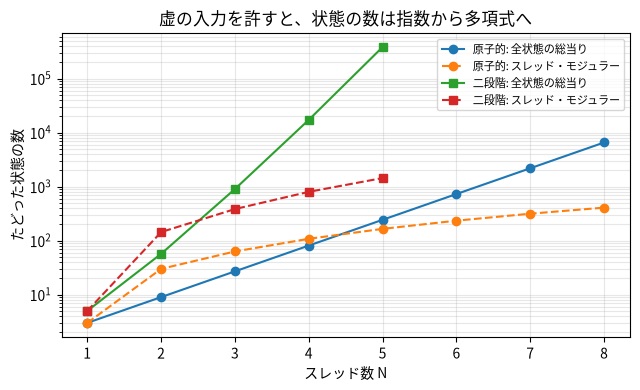

In [43]:
def counter_step(kind, k, cap):
    def step(i, l, g):
        pc, t = l
        if kind == "原子的":
            return [((pc + 1, 0), min(g + 2, cap))] if pc < k else []
        if pc < 2 * k:
            if pc % 2 == 0:
                return [((pc + 1, g), g)]            # 読んで覚える
            return [((pc + 1, 0), min(t + 2, cap))]  # 覚えた値 + 2 を書く
        return []
    return step

k = 2
rows = []
for kind, Nmax in [("原子的", 8), ("二段階", 5)]:
    for N in range(1, Nmax + 1):
        cap = 2 * k * N + 2
        t0 = time.time(); Gs = explore_global(N, (0, 0), 0, counter_step(kind, k, cap)); t1 = time.time()
        R, G, work = explore_modular(N, (0, 0), 0, counter_step(kind, k, cap)); t2 = time.time()
        done = 2 * k if kind == "二段階" else k
        fin = sorted({g for ls, g in Gs if all(l[0] == done for l in ls)})
        allg = {g for _, g in Gs}; modg = {g for r in R for (_, g) in r}
        rows.append((kind, N, len(Gs), sum(len(r) for r in R), t1 - t0, t2 - t1))
        print(f"{kind} N={N}: 全状態 {len(Gs):>7} / モジュラー {sum(len(r) for r in R):>4}   "
              f"偶数: {all(g % 2 == 0 for g in allg)}/{all(g % 2 == 0 for g in modg)}   "
              f"c≤4N: {max(allg) <= 4 * N}/{max(modg) <= 4 * N}   終了時の c(全状態) {fin}")

fig, ax = plt.subplots(figsize=(6.5, 4))
for kind, mk in [("原子的", "o"), ("二段階", "s")]:
    xs = [r[1] for r in rows if r[0] == kind]
    ax.semilogy(xs, [r[2] for r in rows if r[0] == kind], mk + "-", label=f"{kind}: 全状態の総当り")
    ax.semilogy(xs, [r[3] for r in rows if r[0] == kind], mk + "--", label=f"{kind}: スレッド・モジュラー")
ax.set_xlabel("スレッド数 N"); ax.set_ylabel("たどった状態の数"); ax.grid(alpha=.3, which="both"); ax.legend(fontsize=8)
ax.set_title("虚の入力を許すと、状態の数は指数から多項式へ")
plt.tight_layout(); plt.show()

- 全状態の総当りは、スレッドが一つ増えるごとに約 3 倍(原子的)、約 16〜22 倍(二段階)に増える。スレッド・モジュラー検査は多項式で済む(スレッドが少ないうちは、虚の入力を余分に抱えるぶん、かえって多い)。**虚の入力を許すと、計算量が指数から多項式に下がる。** report0 §7.3 で予告したとおりである。
- 「$c$ はいつも偶数」は、各 CS が偶数を偶数に移すという局所的な(帰納的な)性質なので、スレッド・モジュラー検査でも正しく判定できる。
- 「$c\le 4N$」は、スレッド・モジュラー検査では破れたと報告される(偽の警報)。各スレッドは、ほかのスレッドがあと何回足すかを知らずに、ほかのスレッドが起こしうる「2 を足す」変化を何度でも受け取るからである。**個数・保存則(「ちょうど何回」)は、虚の入力の総体では判定できない。** report0 §7.3 の「保存則は虚実行で調べると偽の反例が出る」と同じことである。
- 二段階の加算では、全状態の総当りで終了時の $c$ が $4N$ より小さくなりうる(本物のバグ。加算が失われる)。スレッド・モジュラー検査は、終了時の値をそもそも表せない(ほかのスレッドが終わったかどうかを知らない)。

## §7 非因果的な部品 ―― load buffering・out-of-thin-air・promise

report0 §5.5 で、ロックを使わない並列処理の実機では、未来の書き込みを読む実行(load buffering)が実際に起き、自分で自分を正当化する値(out-of-thin-air)を禁じる規則を書くのが難しいことに触れた。これは部品に意味を与える問題と深く関わっている。

C/C++ のような言語のメモリモデルは、コンパイラの最適化(命令の並べ替え)を許すために、各スレッドが「後で書く値」を先に他のスレッドに見せることを許したい。Batty ら(2015)は、候補実行ごとに条件を課すやり方(report0 の言葉では、rf を一つ決めて、その実行が許されるかを調べるやり方)では、許したい実行と禁じたい out-of-thin-air の実行を区別できないことを示した。

Kang ら(2017)の **promising semantics** は、この問題に部品ごとの意味で答えた。各スレッドは、将来の書き込みを **約束**(promise)として先に出してよい。ただしその約束は、スレッドが **単独で、ほかのスレッドの約束に頼らずに** 実際にその書き込みを行えることが確かめられたとき(certification)にだけ許される。

report0 の階層でいえば、約束は「未来の状態を読ませる」ことであり、因果を破る B・L の段に入る。certification は、その非因果的な部分が、スレッドという部品の中で **自己無撞着に正当化される** ことを要求する条件で、report0 の定理 4 の「一周して整合するものだけが存在する」を、部品ごとに確かめられる形に制限したものと見られる。out-of-thin-air の値は、その正当化が部品をまたいでしかできない(循環が二つのスレッドにまたがる)値である。この対応を厳密にすることは今後の課題とする。

## §8 継続と虚実行 ―― 再実行・世界の数・線形な継続

### 8.1 ELDE の再実行は、何度でも再開できる継続を作る方法だった

report0 の実装は、プロセスを Python のジェネレータで書いた。ジェネレータは **一度しか再開できない継続** である。途中の状態を複製できないので、虚実行(状態のコピー)を作るたびに、プロセスを最初から再実行して同じ地点まで進めた。JRF の Perl 版 ELDE も、プロセスを「何度も最初から実行し直す」方式だった。

これは、一度しか使えない継続から **何度でも再開できる継続**(call/cc の継続)を作る、知られた方法と同じである。Koppel, Scherer, Solar-Lezama(2018)は、例外と状態だけを使い、継続を捕まえる代わりに「計算全体をその地点まで再実行する」ことで、限定継続を実装した(thermometer continuations)。ELDE の再実行は、その素朴な形である。

### 8.2 時間泥棒の夕べ

JRF は 2011 年、Haskell の callCC で「排中律」`gigi` を書き、それを使う二つの物語を作った(《時間泥棒の夕べ》)。`gigi` は最初「ない」(`InRight`)と答え、後で誰かが「ある」証拠を渡すと、捨てた世界から証拠を持って過去に戻り、「ある」(`InLeft`)と答え直す。店主ニノのところでは誰も証拠を持ってこないので「Unhappy End」、ニコラのところでは賢者ホラの教えを知った敵が特別なものを持ってくるので、過去に戻って「Happy End」になる。

`run_with_callcc` は、一度しか再開できないジェネレータを最初から再実行することで、この callCC を実現する。

In [44]:
def story(shop):
    def prog():
        s = yield ("callcc",)                        # gigi: 排中律
        if s[0] == "right":                          # 「ない」と答えた世界
            k = s[1]
            experience = "Search Something..."
            answer = "SomethingOrdinary" if shop == "nino" else "SomethingSpecial"
            if shop == "nicola":                     # 敵が特別なものを持ってくる → 過去に戻る
                yield ("throw", k, (answer, experience))
            return experience + " Unhappy End. Got " + answer
        ans, experience = s[1]                       # 「ある」と答え直した世界
        return experience + " Happy End. Got " + ans
    return prog

for shop in ["nino", "nicola"]:
    worlds = run_with_callcc(story(shop))
    print(f"== {shop}: 世界の数 {len(worlds)}")
    for i, (log, res) in enumerate(worlds):
        print(f"   世界 {i}: {' / '.join(log)}  → {res if res else '(捨てられた)'}")

== nino: 世界の数 1
   世界 0: callcc#0 → right  → Search Something... Unhappy End. Got SomethingOrdinary
== nicola: 世界の数 2
   世界 0: callcc#0 → right / 継続#0 を値 ('SomethingSpecial', 'Search Something...') で再開(この世界は捨てる)  → (捨てられた)
   世界 1: callcc#0 → left  → Search Something... Happy End. Got SomethingSpecial


JRF の 2011 年の実行結果(ニノは "Unhappy End. Got SomethingOrdinary"、ニコラは "Happy End. Got SomethingSpecial")と一致する。ニコラの物語には世界が二つあり、一つ目は捨てられる(JRF の言う「死んだ夢の世界」)。

### 8.3 定理 E: 世界の数 = 1 + 余分に再開した回数

継続を捕まえた地点から実行が続くたびに、その地点を親とする枝が一本出る(通常の return が一本目)。実行の全体は、捕まえた地点を内部の点とする木になり、最後まで行った(あるいは捨てられた)世界が葉である。report0 の定理 1 の証明で使った数え上げから、次が言える。

**定理 E.** 葉の数(世界の数)は、$1 + \sum_x(\text{地点 } x \text{ から続いた回数} - 1)$ に等しい(和は、一回以上続いた地点についてとる)。すなわち **世界の数 = 1 + 継続を余分に再開した回数**。とくに、すべての継続を一度しか再開しない(線形に使う)なら、世界は一つである。継続が状態のすべてを抱えている(一本の逐次プログラムで、状態は継続の中の局所変数だけ)なら、そのとき実行は実実行である。複数のプロセスが状態を受け渡す場合については §8.5 で補う。

ニコラの物語では、`gigi` の継続が二回(通常の return と、過去に戻る一回)使われたので、世界は 2 つになる。report0 §10.2 の母関数 $G(x) = \sum x^{\ell - 1}$ の $x$ は、「継続を一回余分に再開することの重み」と読める。

In [45]:
%%writefile -a test.lean
/-! ## 2. 定理 E: 世界の数 = 1 + 余分に再開した回数

有限の集合 `V` の各要素(CS、または継続を再開してできた世界)が、どこから続いたかを
`par : V → Option V` で表す(`none` は最初)。どの要素からも続かないものが葉(最後まで行った世界)。
葉の数は、1 + Σ(各点から続いたものの数 − 1)(続いたものが一つ以上ある点について)に等しい。
継続の言葉では、捕まえた時点 `x` から続いた回数(通常の return を含む)が `x` のファイバーの大きさで、
**世界の数 = 1 + 継続を余分に再開した回数**。一度しか再開しない(線形な)継続だけなら、世界は一つ。 -/

variable {V : Type} [Fintype V] [DecidableEq V]

def leaves (par : V → Option V) : Finset (Option V) :=
  Finset.univ.filter (fun x => ∀ v, par v ≠ x)

/-- 点 `x` から続いたものの数。 -/
def fanout (par : V → Option V) (x : Option V) : ℕ :=
  (Finset.univ.filter (fun v => par v = x)).card

theorem card_leaves (par : V → Option V) :
    (leaves par).card + (Finset.univ.image par).card = Fintype.card V + 1 := by
  have h : leaves par = Finset.univ \ Finset.univ.image par := by
    ext x; simp [leaves]
  rw [h, Finset.card_sdiff_of_subset (Finset.subset_univ _), Finset.card_univ,
    Fintype.card_option]
  have := Finset.card_le_univ (Finset.univ.image par)
  rw [Fintype.card_option] at this
  omega

theorem sum_fanout (par : V → Option V) :
    ∑ x ∈ Finset.univ.image par, fanout par x = Fintype.card V := by
  rw [← Finset.card_univ, Finset.card_eq_sum_card_image par Finset.univ]
  rfl

/-- **定理 E.** 葉の数 = 1 + Σ_x (x から続いたものの数 − 1)。 -/
theorem thmE (par : V → Option V) :
    (leaves par).card = 1 + ∑ x ∈ Finset.univ.image par, (fanout par x - 1) := by
  have hc := card_leaves par
  have hs := sum_fanout par
  have hpos : ∀ x ∈ Finset.univ.image par, 1 ≤ fanout par x := by
    intro x hx
    obtain ⟨v, -, rfl⟩ := Finset.mem_image.mp hx
    unfold fanout
    exact Finset.card_pos.mpr ⟨v, by simp⟩
  have : ∑ x ∈ Finset.univ.image par, (fanout par x - 1) + (Finset.univ.image par).card =
      ∑ x ∈ Finset.univ.image par, fanout par x := by
    rw [Finset.card_eq_sum_ones, ← Finset.sum_add_distrib]
    exact Finset.sum_congr rfl (fun x hx => Nat.sub_add_cancel (hpos x hx))
  omega


Appending to test.lean


### 8.4 線形な継続と古典論理

Griffin(1990)は、callCC の型が古典論理のパースの法則 $((A\to B)\to A)\to A$ に対応することを示した。callCC を持つ言語のプログラムは、排中律を使う古典論理の証明にあたる。JRF の `gigi` はまさに排中律 $A \vee \neg A$ の証明である。

一方、Filinski(1992)と Berdine, O'Hearn, Reddy, Thielecke(2002)は、継続を **線形に**(ちょうど一度だけ)使う CPS を調べた。Berdine らによれば、例外、コルーチン、goto、末尾呼び出しなど、ほとんどの制御機能は継続を線形に使い、そうでないのは **バックトラック**(やり直し)だけである。

これを虚実行の言葉に移すと、次の対応ができる。

| 制御 | 継続の使い方 | 実行 | 論理 |
|---|---|---|---|
| 例外・コルーチン・goto・ジェネレータ | 線形(一度だけ) | 実実行(状態の移動) | 直観主義的(線形) |
| バックトラック・callCC による排中律 | 二度以上 | 虚実行(状態のコピー、世界が分かれる) | 古典論理 |

report0 は、実実行を線形論理の資源として、虚実行を「!」をつけてコピーを許したものとして整理した。継続の側から見ても同じ線が引ける。**虚実行を許すことは、継続のコピーを許すことであり、論理の上では古典論理への拡張にあたる。** これは、虚数が実数の「2 乗すれば 0 以上」を捨てて方程式をいつでも解けるようにしたのと同じく、「一度しか使わない」を捨てて「どちらかである(排中律)」をいつでも言えるようにした拡張である。

JRF の callCC の goto の例で "stop" を送ると、サーバーの return が「サーバーを受け取った直後のクライアント」に戻り、同じ要求を出し直して終わらなかった(GHC で実測)。これは、継続の余分な再開が、終わらない木(葉に届かない枝)を作る例である。時間ループの言葉では、戻った先が同じ値で同じ跳躍をもう一度起こすので、整合の条件は $x = x$ で、どの値でも整合する(report0 定理 4 (2) の「二つ以上」の側)。反復ではそのどれも選べず、Haskell の意味論でいえば最小の不動点(止まらない計算 ⊥)になる。この「同じ過去に何度も戻る反復」は、report3 §3 で扱った。

### 8.5 定理 E′: 継続を何度でも再開できても、作れる実行は rf ∪ po が循環しないものまで

8.3 の「線形な継続なら実実行」は、状態が継続の中にしかない場合の話である。report0 の ELDE のように、複数のプロセスが共有状態を受け渡す場合は、もう一つの「コピー」がある。スケジューラ(ELDE の総当りの本体)は、状態の **値** を保存しておいて、何人にでも渡せる。

そこで、次のスケジューラを考える。各プロセスは一度しか再開できない継続(ジェネレータ)で、CS を一つずつ進める。スケジューラは、これまでに出てきたどの unlock 状態でも保存しておき、lock を求めたプロセスに渡せる。CS $v$ を実行できるのは、$v$ に渡す状態を書いた CS(rf の親)と、同じプロセスで $v$ より前の CS が、すでに実行されたときだけである。

**定理 E′.** rf を一つ固定する。このスケジューラで、各 CS をちょうど一回実行してその rf を作れる ⇔ rf ∪ po が循環しない(report0 の階層の I 以下)。

**証明.** スケジューラの実行順に時刻を振れば、rf ∪ po の辺はどれも時刻を増やすので、循環はありえない。逆に、循環しなければ、各 CS をその「祖先の数」(rf ∪ po をさかのぼって届く CS の数)の小さい順に実行すればよい。辺の先は祖先の数が真に大きい。∎

ここから、次の三つのことがわかる。

1. **虚実行を作るのに、継続のコピーは要らない.** 一つの虚実行(I 以下の rf)は、継続を一度ずつしか使わないスケジューラで作れる。要るのは状態の値のコピーである。ELDE が再実行(何度でも再開できる継続)を必要としたのは、一つの虚実行を作るためではなく、**たくさんの世界を、途中まで共有しながら総当りする** ためだった(定理 E の世界の木)。とくに ELDE その1 の lock 仕様の実行(E0)は E0 ⊂ T ⊂ I なので、このスケジューラで作れる。
2. **実実行は、状態も継続も線形に扱ったもの.** 状態の値を一度しか渡さないスケジューラが作るのは実実行だけである(report0 定理 1: 各状態が高々一度しか読まれない)。継続のコピーと状態のコピーは、一本の逐次プログラムでは同じこと(継続が状態を抱えている)だが、複数のプロセスでは別の軸になる。
3. **時間逆行・時間ループ(B・L)は、どんなスケジューラでも作れない.** それらの実行は、前から計算するのではなく、自己無撞着性で決まる(report0 定理 4)。callCC の goto ループは、それを「同じ過去に何度も戻る反復」で近づけようとするもので、整合する点があっても反復がそこに着くとは限らない(stop の例、report3 §3)。

Lean では、rf ∪ po の辺 `EdgeRP` について、単射な時刻 `τ` で辺が時刻を増やすものがある ⇔ 循環がない、を `sched_iff` として証明した。

In [46]:
%%writefile -a test.lean
/-! ## 3. 定理 E′: スケジューラで作れる実行は、rf ∪ po が循環しないものに限る

一度しか再開できない継続(ジェネレータ)でプロセスを動かし、状態の値はいくらでも保存して配れるスケジューラを考える。
CS `v` を実行できるのは、`v` が読む状態を書いた CS(`rf v`)と、同じプロセスで `v` より前の CS(`po`)が、
すでに実行されたときだけである。スケジューラの実行順(メタな時刻)を単射 `τ` で表す。
そういう順序がある ⇔ rf ∪ po が循環しない(report0 の階層の I 以下)。
時間逆行・時間ループ(B・L)の rf は、どんなスケジューラでも作れず、自己無撞着性(report0 定理 4)でしか存在しない。 -/

section Sched

variable {V : Type} [Fintype V]

/-- rf ∪ po の辺。 -/
def EdgeRP (rf : V → Option V) (po : V → V → Prop) (a b : V) : Prop := rf b = some a ∨ po a b

open Relation in
/-- **定理 E′.** スケジューラの実行順があるのは、rf ∪ po が循環しないときに限る。 -/
theorem sched_iff (rf : V → Option V) (po : V → V → Prop) :
    (∃ τ : V → ℕ, Function.Injective τ ∧ ∀ a b, EdgeRP rf po a b → τ a < τ b) ↔
      ∀ a, ¬ TransGen (EdgeRP rf po) a a := by
  classical
  constructor
  · rintro ⟨τ, -, hτ⟩ a h
    have : ∀ x y, TransGen (EdgeRP rf po) x y → τ x < τ y := by
      intro x y hxy
      induction hxy with
      | single h => exact hτ _ _ h
      | tail _ h ih => exact ih.trans (hτ _ _ h)
    exact lt_irrefl _ (this a a h)
  · intro hac
    -- 祖先の数で並べ、同じ数のものは番号で並べる
    let anc : V → ℕ := fun v => (Finset.univ.filter (fun u => TransGen (EdgeRP rf po) u v)).card
    let e := Fintype.equivFin V
    let N := Fintype.card V
    have hanc : ∀ a b, EdgeRP rf po a b → anc a < anc b := by
      intro a b hab
      apply Finset.card_lt_card
      refine ⟨fun u hu => ?_, fun hsub => ?_⟩
      · simp only [Finset.mem_filter, Finset.mem_univ, true_and] at hu ⊢
        exact hu.tail hab
      · have : a ∈ Finset.univ.filter (fun u => TransGen (EdgeRP rf po) u b) := by
          simp [TransGen.single hab]
        have := hsub this
        simp only [Finset.mem_filter, Finset.mem_univ, true_and] at this
        exact hac a this
    refine ⟨fun v => anc v * N + (e v : ℕ), ?_, ?_⟩
    · intro a b h
      have ha : (e a : ℕ) < N := (e a).isLt
      have hb : (e b : ℕ) < N := (e b).isLt
      have hmod : (e a : ℕ) = (e b : ℕ) := by
        have h1 := congrArg (· % N) h
        simp only at h1
        rwa [Nat.mul_add_mod_of_lt ha, Nat.mul_add_mod_of_lt hb] at h1
      exact e.injective (Fin.ext hmod)
    · intro a b hab
      have hlt := hanc a b hab
      have ha : (e a : ℕ) < N := (e a).isLt
      calc anc a * N + (e a : ℕ) < anc a * N + N := by omega
        _ = (anc a + 1) * N := by ring
        _ ≤ anc b * N := Nat.mul_le_mul_right _ hlt
        _ ≤ anc b * N + (e b : ℕ) := Nat.le_add_right _ _

end Sched

end ImagExec.R2


Appending to test.lean


## §9 まとめ・予想・今後の課題

### 9.1 まとめ

- **部品に意味を与えるには虚の入力が要る.** 実実行だけの意味は並列合成について閉じない(定理 C、Lean)。すべての虚の入力を含む意味は閉じるが細かすぎる。完全抽象な意味はその間にある(§2・§3)。
- **ELDE その1 の規則は、Brookes の軌跡の隙間と同じ形** をしている。lock 仕様は、プロセスの軌跡のどこに隙間(他からの受け渡し)を開けるかを指定したものである(§3)。
- **各 lock に一つずつの虚の入力が必要十分**(定理 H、Lean)。スケジュールを選べる検査者(ELDE の設定)に対しては、完全抽象な意味は「各 lock の前に一つずつ任意に割り込ませた実行」で、どの lock の虚の入力も省けず、一つで足りる。これは ELDE その1 の lock 仕様の形で、「E0 が最小限の虚か」に肯定的に答える。観測する側が記憶を持つと、すべての虚の入力が要る(スケジュールを選べない観測では、少なくとも何もしない CS の位置は見えない。定理 I)。スケジュールを選べない観測でも、相手はプロセスと同じ長さ(各 lock に一回の割り込み)で足りる(定理 H′、Lean)。記憶のある相手が見分けるのは「外れたときに一手で潰せる」虚の入力の列だけで(定理 J)、CS が状態の数 − 1 個以下なら、恒等写像の CS を消して一致することが文脈同値に等しい(定理 K)。状態の数が効くのは、相手が自分の書いた後のプロセスの進み具合を知らず、位置の数が状態の数に届くと「どこから走っても避けたい値にならない値」がなくなりうるからである(§4)。
- **虚の入力の総体を許すと、計算量が指数から多項式に下がる**(スレッド・モジュラー検査)。局所的な不変条件は正しく判定でき、個数・保存則は判定できない(§5・§6)。
- **非因果的な部品**: 弱いメモリモデルの promise と certification は、未来の値を部品の意味に入れ、その自己無撞着性を部品の中で確かめる仕組みと見られる(§7)。
- **継続**: ELDE の再実行は、何度でも再開できる継続を作る方法と同じである。世界の数 = 1 + 継続を余分に再開した回数(定理 E、Lean)。線形な継続 = 実実行、継続のコピー = 虚実行 = 古典論理(状態が継続の中にしかない場合)。複数のプロセスでは、継続を一度ずつしか使わなくても、状態の値のコピーで rf ∪ po が循環しない虚実行はすべて作れ、時間ループだけは作れない(定理 E′)(§8)。

### 9.2 虚数との比較

| | 虚数 | 虚実行 |
|---|---|---|
| なくても原理的には解ける | 実数解は実数の範囲で求まる | 実実行は有限個なので総当りできる |
| 部分に意味を与える | 回路の各素子に複素インピーダンスを与えて組み立てる | 各プロセスに虚の入力を含む意味を与えて組み立てる(§3) |
| 計算が楽になる | 複素数の指数関数で微分方程式が代数になる | 虚の入力の総体で検査が指数から多項式に(§6) |
| 本当に必要か | 量子力学では実験で必要と示された(Renou ら 2021) | 並列合成について閉じた意味には、実実行の外の入力が必要(定理 C)。どの lock の虚の入力も省けない(定理 H (3)) |

### 9.3 今後の課題

1. **予想 2″ の残りと、反例の特徴づけ.** CS がちょうど状態の数のとき(定理 K の外、$|S| \le 4$ では計算機で確認済み)の証明。区別できなくなる組の特徴づけ(両側が満ちていることは必要だが、十分ではない)と、反例が始まる CS の数($|S|=2,3,4$ で 3, 4, 6?)の一般形。予想 3(一歩ずつ付いていく相手で足りる)の証明。§4.6 の末尾の境界の解析の完成。厳密な判定法の長さの補題の Lean 化。記憶のない相手に対する完全抽象な意味(定理 H′ で有限個の検査で決まることはわかった)を、割り込みの意味の商として明示的に書くこと。Brookes の stuttering・mumbling の閉包との正確な対応。
2. **ELDE の階層との対応.** 定理 H は「各 lock に一つずつの虚の入力」が必要十分であることを示した。これを report0 の rf の言葉(E0 の受け渡しの集合)で直接述べ直し、トンネル・因果的コピーの段がそれ以上の何を区別するかを調べる。
3. **promise と定理 4 の対応の厳密化**(§7)。
4. **継続の線形性の判定.** プログラムが継続を線形に使っているかを型で判定できれば、そのプログラムの実行は虚実行を含まない(ELDE の総当りで実実行だけを数えればよい)と静的に言える。ただし定理 E′ のとおり、これは状態が継続の中にしかない場合で、複数のプロセスでは状態の値のコピーも見る必要がある。
5. **callCC の意味論の形式化.** 定理 E は世界の木についての組合せの定理として述べ、callCC そのものは形式化していない。Haskell の transformers の `callCC` の意味論を Lean で書き、再実行による実現(`run_with_callcc`)と一致することを示すこと(Koppel ら 2018 の主張の、この設定での形式化)。

## 参考文献

### JRF の文献

- JRF《Exhaustive Lock Dependency Emulator その１ 並列処理の総当り》JRF のソフトウェア Tips, 2011-06-20(追記 2018-04-06)。 http://jrf.cocolog-nifty.com/software/2011/06/post-1.html
- JRF《Haskell の callCC で goto を作る》同, 2011-01-20。 http://jrf.cocolog-nifty.com/software/2011/01/post-2.html
- JRF《時間泥棒の夕べ − 排中律と call/cc》JRF の私見：雑記, 2011-01-20。 http://jrf.cocolog-nifty.com/column/2011/01/post-1.html (配布物 momo_hs-20110214.shar の momo_0.hs)
- JRF & Claude Opus 5.5『虚実行論 ―― 並列処理の総当りから「虚」の理論へ』(report0)、『虚実行と合流』(report1)、『時間ループと最適化』(report3)。

### 意味論・検証

- S. Owicki, D. Gries, "An axiomatic proof technique for parallel programs I", *Acta Informatica* 6, 319–340, 1976.
- C. B. Jones, "Tentative steps toward a development method for interfering programs", *ACM TOPLAS* 5(4), 596–619, 1983(rely-guarantee)。
- S. Brookes, "Full abstraction for a shared-variable parallel language", *Information and Computation* 127(2), 145–163, 1996(会議版 LICS 1993)。
- C. Flanagan, S. Qadeer, "Thread-modular model checking", *SPIN* 2003, LNCS 2648, doi:10.1007/3-540-44829-2_14.
- M. Batty, K. Memarian, K. Nienhuis, J. Pichon-Pharabod, P. Sewell, "The problem of programming language concurrency semantics", *ESOP* 2015, LNCS 9032, 283–307.
- J. Kang, C.-K. Hur, O. Lahav, V. Vafeiadis, D. Dreyer, "A promising semantics for relaxed-memory concurrency", *POPL* 2017, 175–189.

### 継続と論理

- T. G. Griffin, "A formulae-as-types notion of control", *POPL* 1990, 47–58.
- A. Filinski, "Linear continuations", *POPL* 1992, 27–38.
- J. Berdine, P. O'Hearn, U. Reddy, H. Thielecke, "Linear continuation-passing", *Higher-Order and Symbolic Computation* 15(2–3), 181–208, 2002.
- J. Koppel, G. Scherer, A. Solar-Lezama, "Capturing the future by replaying the past (functional pearl)", *Proc. ACM Program. Lang.* 2(ICFP), 2018.
- J.-Y. Girard, "Linear logic", *Theoretical Computer Science* 50, 1987.

### その他

- M.-O. Renou ら, "Quantum theory based on real numbers can be experimentally falsified", *Nature* 600, 2021.
- L. de Moura, S. Ullrich, "The Lean 4 theorem prover and programming language", *CADE-28*, 2021. / The mathlib Community, "The Lean mathematical library", *CPP* 2020.

### 謝辞と注意

本稿の整理(ELDE その1 の規則と Brookes の軌跡の対応、必要な虚の量の探索と予想、promise と定理 4 の対応、継続との対応表)は、Claude Opus 5.5 が report0・report1 と JRF の記事をもとに組み立てたものである。定理 C・E・E′・H は Lean 4 + Mathlib で証明した。定理 C・E・E′ は数学的には易しい。定理 H と H′ は、記憶のない部品と記憶のない相手という限られたモデルでの定理で、記憶のある検査者の場合は文章による証明である。定理 H (3) は Lean で証明した。定理 I は Lean で証明した。§4 の予想 2′ は一般には誤りであることを厳密な判定法で示し、予想 2″ に改めた。補題 S・定理 J・定理 K(予想 2″ の CS ≦ 状態の数 − 1 の部分)は Lean で証明し、定理 K の相手を実際に作ってすべてのインタリーブでも確かめた。CS = 状態の数の場合は $|S| \le 4$ で計算機により確かめただけである。厳密な判定法の正しさ(長さの補題と知識の状態の十分性)は文章による証明である。§7 の promise との対応は解釈であって、定理ではない。文献は照合した(記録は refs_BIBLIO.md)。

## 付録: Lean による一括検証

ここまでの `%%writefile` セルで `test.lean` が出来上がっている。最後に、使った公理を表示する行を足し、Lean 4(v4.34.1)+ Mathlib(v4.34.1)をそろえてまとめて検証する。

* **Colab**: elan をインストールし、`imagexec_lean/` に Mathlib を依存に持つ Lake プロジェクトを作る。`lake exe cache get` でビルド済みの .olean を取得する(初回は数分)。
* **ローカル**: カレントディレクトリかその親に、すでに Mathlib 入りの `lakefile.lean` があれば、それをそのまま使う。

エラーがなく、`#print axioms` が標準の公理(`propext`, `Classical.choice`, `Quot.sound`)だけを挙げれば、証明は通っている。

In [47]:
%%writefile -a test.lean
#print axioms ImagExec.R2.not_compositional
#print axioms ImagExec.R2.thmE
#print axioms ImagExec.R2.sched_iff
#print axioms ImagExec.R2H.inter_blocks
#print axioms ImagExec.R2H.blocks_realizable
#print axioms ImagExec.R2H.thmH
#print axioms ImagExec.R2H.thmH3
#print axioms ImagExec.R2H.thmH'
#print axioms ImagExec.R2H.thmI
#print axioms ImagExec.R2H.sep_single
#print axioms ImagExec.R2H.sep_single_nil
#print axioms ImagExec.R2M.lemmaS
#print axioms ImagExec.R2M.lemmaS_conv
#print axioms ImagExec.R2M.thmJ_nec
#print axioms ImagExec.R2M.thmJ_last
#print axioms ImagExec.R2M.thmJ_suff
#print axioms ImagExec.R2M.thmJ
#print axioms ImagExec.R2M.thmK
#print axioms ImagExec.R2M.thmK_card
#print axioms ImagExec.R2M.thmK_long


Appending to test.lean


In [48]:
%%bash
set -e
export PATH="$HOME/.elan/bin:$PATH"
if [ -f lakefile.lean ] && grep -q mathlib lakefile.lean; then
  echo "using the existing Lake project in the current directory"
  echo "." > .leandir
elif [ -f ../lakefile.lean ] && grep -q mathlib ../lakefile.lean; then
  echo "using the existing Lake project in the parent directory"
  echo ".." > .leandir
else
  if ! command -v lake >/dev/null 2>&1; then
    curl -sSfL https://raw.githubusercontent.com/leanprover/elan/master/elan-init.sh \
      | sh -s -- -y --default-toolchain none
  fi
  mkdir -p imagexec_lean && cd imagexec_lean
  echo 'leanprover/lean4:v4.34.1' > lean-toolchain
  cat > lakefile.lean <<'EOF'
import Lake
open Lake DSL

package imagexec_lean

require mathlib from git
  "https://github.com/leanprover-community/mathlib4.git" @ "v4.34.1"
EOF
  lake update 2>&1 | tail -3
  lake exe cache get 2>&1 | tail -3
  cd ..
  echo "imagexec_lean" > .leandir
fi

using the existing Lake project in the parent directory


In [49]:
%%bash
export PATH="$HOME/.elan/bin:$PATH"
LEANDIR=$(cat .leandir)
FILE=$(pwd)/test.lean
cd "$LEANDIR"
time lake env lean "$FILE" && echo "=== test.lean: all theorems checked ==="


'ImagExec.R2.not_compositional' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec

.R2.thmE' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.R2.sched_iff' depends

 on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.R2H.inter_blocks' depends on axioms: [

propext, Classical.choice, Quot.sound]
'ImagExec.R2H.blocks_realizable' depends on axioms: [propext,

 Classical.choice, Quot.sound]
'ImagExec.R2H.thmH' depends on axioms: [propext, Classical.choice, Qu

ot.sound]
'ImagExec.R2H.thmH3' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.

... (9 outputs left out)

ImagExec.R2M.thmK_card' depends on axioms: [propext, Classical.choice, Quot.sound]
'ImagExec.R2M.thm

K_long' depends on axioms: [propext, Classical.choice, Quot.sound]



real	0m4.505s
user	0m6.733s
sys	0m1.295s


=== test.lean: all theorems checked ===
